# Sailboat rig as a 3D frame: Morgan 462 ketch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RigFrame/rigframe/blob/main/notebooks/morgan-462-ketch.ipynb)

**Pynite** (3D frame, tension-only stays, P-Delta, linear buckling), cross-checked with
**OpenSeesPy** (initial-strain pretension, P-Delta and corotational large-displacement runs). The same
method as the Oceanis 440 and Island Packet 40 notebooks, extended to **two masts**.

The Morgan 462 is a **masthead ketch**: a main mast with a genoa on the forestay, and a smaller **mizzen**
mast aft, behind the centre cockpit. A ketch raises a question the sloop and cutter studies didn't have:
**how the two masts hold each other up.**

- **With a triatic stay** (the default here), a wire runs from the main masthead to the mizzen masthead.
  The main has no backstay of its own; the forestay's pull goes through the triatic into the mizzen,
  and the mizzen's backstays hold it. The two rigs act as one structure.
- **With split backstays** (`backstay_arrangement = "split"`), the main's two backstay legs pass either
  side of the mizzen to the quarters, and the mizzen stands on its own rigging. §10 runs both.

**What is published** (cited where used):

| Item | Value | Source |
|---|---|---|
| I, J, P, E | 50.75, 18.75, 43.25, 13.00 ft | [Good Old Boat sail data](https://goodoldboat.com/saildata/boat/morgan-462-ketch/), [Murray Yacht Sales (sailboatdata)](https://murrayyachtsales.com/morgan-46-reviews-and-more/) |
| Mizzen PY, EY | 26.50, 9.00 ft | the same two sources |
| Displacement, ballast | 30,000 lb, 8,400 lb lead | Murray (sailboatdata) and Good Old Boat's description. Good Old Boat's table says 33,000 lb; the lower figure has more sources |
| LOA, LWL, beam, draft | 46.5, 39.25, 13.5 ft, 5.25 ft (6.0 ft deep option) | the same two sources |
| Mast height | 56.5 ft above the waterline | Murray (sailboatdata) |
| Rig, designer, build | masthead ketch (also built as a sloop); Henry Scheel; Morgan Yachts, 1979–84 | the same two sources |

**Nothing about the 462's spars or standing rigging was found** in any public source: not the spreader
count, mast step, wire sizes, the mizzen's position or height, or whether boats carried a triatic. So
everything below the published lines in §0 is a `# PLACEHOLDER`. The main mast copies the IP40 layout (one
spreader set, caps, fore and aft lowers); the mizzen gets the same layout, smaller. Every number in this
notebook is an **estimate** until the boat is measured. This is a study model, not a rig certification.

**Units: SI throughout** (m, N, Pa, N·m). Wire sizes are in inches, as the boat's would be.

**Companion note:** [the companion PDF](https://github.com/rigframe/rigframe/releases/download/sample-reports/morgan-462-ketch-companion.pdf)
defines the load cases with free-body diagrams, explains the terms and lists the textbook equations and rig
standards behind the model. **Generated files** (rewritten on every run): the item-by-item
[report](output/morgan-462-ketch/REPORT.md) (§13), the standalone 3D viewer
`output/morgan-462-ketch/viewer-3d.html` (§14), and the companion's figures `output/morgan-462-ketch/assets/rig-m462-*.svg` (§15).

**Axes.** Inputs and results are in **boat axes**: $x$ forward, $y$ to port, $z$ up, with the origin at the
main mast on deck. The mizzen sits at negative $x$. Pynite treats global $Y$ as vertical, so the solvers
work in $(X, Y, Z) = (x,\ z,\ -y)$. One helper, `to_solver`, does the conversion.

**Running this notebook.** Two ways, and neither needs the rest of rigframe:

- **Google Colab:** the badge above opens it in your browser. Run the cells in order (Runtime → Run all). The setup
  cell below fetches this repository for its data, and the install cell after it adds what Colab lacks in about a
  minute. If the install cell asks you to restart the session, do (Runtime → Restart session) and run all again.
  Colab runs a newer Python than 3.12; if OpenSees won't load there, its cross-check reports SKIP and the rest runs.
- **On your computer:** with Python 3.12, from the repository's `notebooks/` folder:
  `python -m venv .venv`, activate it, `pip install -r requirements.txt` (or just run the install cell), then open this
  notebook in Jupyter or VS Code.
  Python 3.12 matters only for the OpenSees cross-check, whose Windows build needs exactly 3.12.

Everything it writes goes to `output/morgan-462-ketch/`: the item-by-item report (`REPORT.md`, with its figures in `assets/`)
and the standalone 3D viewer (`viewer-3d.html`). `tools/md_to_tabloid_pdf.py` turns the report into an 11 × 17 in PDF.
The finished reports from this notebook are in [the sample-reports release](https://github.com/rigframe/rigframe/releases/tag/sample-reports).

**Edit only the `RigParams` cell.** It holds every input; the values marked `# PLACEHOLDER` are estimates to replace
with measurements. This is an engineering estimate, not a rig survey.

In [1]:
# Setup: works as is in Google Colab or in a local venv.
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:                       # Colab opens the notebook on its own: fetch the repo for its data
    if not Path("/content/rigframe").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RigFrame/rigframe", "/content/rigframe"],
                       check=True)
    os.chdir("/content/rigframe/notebooks")

WIRE_CSV = Path("../data/wire_1x19_316.csv")           # 1x19 316 breaking loads from four catalogues
OUT = Path("output") / "morgan-462-ketch"                         # the report, its figures and the 3D viewer go here
OUT.mkdir(parents=True, exist_ok=True)
print("writing to", OUT.as_posix())

writing to output/morgan-462-ketch


In [2]:
# Optional: install what this notebook needs. In Colab, run it. In a local venv where you've already run
# `pip install -r requirements.txt`, you can skip it; running it anyway only installs what's missing.
import importlib.metadata as md
import subprocess
import sys
from pathlib import Path


def installed(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None


NEED = {"PyNiteFEA": "1.0.1", "sectionproperties": "3.10.2", "openseespy": "3.8.0.0"}   # built and checked on these
todo = [f"{p}=={v}" for p, v in NEED.items() if installed(p) != v] + (["prettytable"] if not installed("prettytable") else [])
if not todo:
    print("Nothing to install: everything this notebook needs is here.")
else:
    # Colab has already loaded numpy, scipy, pandas and matplotlib. Hold them at their installed versions so pip
    # can't replace them under the running session; pip then picks dependency versions that fit them.
    held = {p: installed(p) for p in ("numpy", "scipy", "pandas", "matplotlib") if installed(p)}
    hold = Path("hold-loaded-packages.txt")
    hold.write_text("".join(f"{p}=={v}\n" for p, v in held.items()))
    print("Installing", ", ".join(todo), "(about a minute)...")
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo, "-c", str(hold)])
    if r.returncode != 0:
        print("No versions fit the loaded packages, so installing without holding them.")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *todo], check=True)
    hold.unlink()
    moved = [f"{p} {v} -> {installed(p)}" for p, v in held.items() if installed(p) != v]
    if moved:
        raise RuntimeError("pip had to update " + ", ".join(moved) + ", which this session has already loaded. "
                           "Restart the session (Colab: Runtime > Restart session), then run all cells again. "
                           "This cell will then find everything installed and skip itself.")
    print("Installed. Carry on.")

Nothing to install: everything this notebook needs is here.


In [3]:
import json, math, os, shutil, subprocess, tempfile, time
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.linalg as sla
import matplotlib.pyplot as plt
from matplotlib import cm, colors as mcolors

from Pynite import FEModel3D
from Pynite.Analysis import _partition_D
from sectionproperties.pre.library import elliptical_hollow_section, rectangular_section
from sectionproperties.analysis import Section

FT, IN, LBF, LB = 0.3048, 0.0254, 4.4482216152605, 0.45359237   # m, m, N, kg
G_ACC = 9.80665                                                  # m/s^2

# Chart colours: fixed categorical order, one entity = one colour everywhere
C_PYNITE, C_OPS_PD, C_OPS_CR, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})


def to_solver(v):
    """Boat axes (x fwd, y port, z up) -> solver axes (X fwd, Y up, Z stbd). Works on forces and moments too."""
    x, y, z = v
    return (x, z, -y)


def to_boat(V):
    X, Y, Z = V
    return (X, -Z, Y)

---
## §0 Inputs: the one cell to edit

Everything the model needs is in `RigParams`. Published values are marked with their source; everything
else is a `# PLACEHOLDER` to replace with measurements from the boat.

**How the dock tune is set.** Each turnbuckled group gets a target tension as a percentage of its wire's
design MBL, measured on its bottom segment, where a Loos gauge would go. The model solves for all the
turnbuckle shortenings at once. The forestay sits inside the genoa furler and has no adjuster, so its
target is reached by whatever holds the main masthead aft:

- **Triatic:** the triatic has a fixed length, so the forestay is tuned by the **mizzen backstays**,
  through the triatic. Seven turnbuckles: main caps, fore and aft lowers; mizzen caps, fore and aft lowers;
  mizzen backstays.
- **Split backstays:** the main backstays tune the forestay, and the mizzen backstays tune the mizzen forestay.
  Eight turnbuckles.

**$RM_{30}$** sizes the sailing case: $\Delta \cdot g \cdot GZ_{30}$ with an **assumed** $GZ_{30} = 0.70$ m,
the same placeholder as the other two studies.

In [4]:
@dataclass
class RigParams:
    # ---- published (see table above) ------------------------------------------------------
    I: float = 50.75 * FT                 # forestay height above sheer (masthead rig)
    J: float = 18.75 * FT                 # main mast to forestay tack
    P: float = 43.25 * FT                 # main luff
    E: float = 13.00 * FT                 # main foot
    PY: float = 26.50 * FT                # mizzen luff
    EY: float = 9.00 * FT                 # mizzen foot
    displacement_kg: float = 30000 * LB
    beam: float = 13.5 * FT
    # ---- how the masts hold each other ----------------------------------------------------
    backstay_arrangement: str = "triatic" # PLACEHOLDER  "triatic" (main head -> mizzen head) | "split" (main backstays round the mizzen)
    # ---- main mast ------------------------------------------------------------------------
    keel_stepped: bool = True             # PLACEHOLDER  heel pinned below deck + partners
    z_heel: float = -1.80                 # PLACEHOLDER  heel height (m)
    z_boom: float = 1.80                  # PLACEHOLDER  gooseneck height above deck
    mast_above_hounds: float = 0.20       # PLACEHOLDER
    spreader_z_frac: float = 0.50         # PLACEHOLDER  one set, as a fraction of I
    spreader_len: float = 1.55            # PLACEHOLDER  root to tip (m)
    sweep_deg: float = 0.0                # PLACEHOLDER  in line
    chainplate: dict = field(default_factory=lambda: {   # PLACEHOLDER  (x, |y|) per shroud group
        "cap": (-0.10, 1.85), "lowerF": (0.50, 1.80), "lowerA": (-0.75, 1.80),
        "zcap": (-7.10, 1.70), "zlowerF": (-6.60, 1.65), "zlowerA": (-7.55, 1.65)})
    stem: tuple = (18.75 * FT, 0.0, 0.0)  # forestay tack (x = J)
    backstay_foot: tuple = (-9.60, 1.70, 0.40)           # PLACEHOLDER  split main backstay legs (x, |y|, z)
    # ---- mizzen ---------------------------------------------------------------------------
    x_mizzen: float = -7.00               # PLACEHOLDER  mizzen position, aft of the main (m)
    IY: float = 10.00                     # PLACEHOLDER  mizzen masthead (triatic, backstays) above deck (m)
    mizzen_keel_stepped: bool = False     # PLACEHOLDER  False: deck-stepped, pinned at deck
    z_boom_mz: float = 1.70               # PLACEHOLDER  mizzen gooseneck above deck
    mizzen_above_hounds: float = 0.15     # PLACEHOLDER
    mz_spreader_z_frac: float = 0.50      # PLACEHOLDER  fraction of IY
    mz_spreader_len: float = 0.95         # PLACEHOLDER
    mz_backstay_foot: tuple = (-9.30, 1.20, 0.40)        # PLACEHOLDER  mizzen backstay legs (x, |y|, z)
    mz_forestay_tack: tuple = (-4.40, 0.0, 0.60)         # PLACEHOLDER  split arrangement only: mizzen forestay to the cockpit's forward end
    # ---- wire (keys into the 1x19 table) -- PLACEHOLDER: no published sizes ------------------
    wire: dict = field(default_factory=lambda: {
        "cap": "7/16 in", "lowerF": "3/8 in", "lowerA": "3/8 in", "forestay": "7/16 in", "backstay": "3/8 in",
        "triatic": "5/16 in", "zcap": "1/4 in", "zlowerF": "1/4 in", "zlowerA": "1/4 in", "zbackstay": "5/16 in",
        "zforestay": "1/4 in"})
    pretension_pct: dict = field(default_factory=lambda: {   # dock tune, % of design MBL, bottom segment
        "cap": 20.0, "lowerF": 10.0, "lowerA": 12.0, "forestay": 20.0,
        "zcap": 15.0, "zlowerF": 10.0, "zlowerA": 10.0,
        "zforestay": 12.0})                                  # split backstays only: set by the mizzen backstays
    # ---- sailing case -----------------------------------------------------------------------
    GZ30: float = 0.70                    # PLACEHOLDER  m, righting arm at 30 deg
    RM_factor: float = 1.0
    sail_plan: str = "full"               # "full" | "jib_and_jigger" | "headsail_only" | "main_only" | "reefed_main_only"
    reef_fraction: float = 0.60           # PLACEHOLDER  reefed main luff as a fraction of P
    headsail_LP_over_J: float = 1.30      # PLACEHOLDER  Good Old Boat lists 130% and 150% genoas
    main_load_shape: str = "triangular"   # "triangular" (max at boom) | "uniform"
    # ---- spar sections (mm) for sectionproperties; OVERRIDE wins if given -----------------
    mast_chord: float = 280.0             # PLACEHOLDER  main: fore-aft depth
    mast_width: float = 180.0             # PLACEHOLDER
    mast_wall: float = 5.5                # PLACEHOLDER
    mast_slot: float = 26.0               # what-if only: a luff slot for an in-mast furler
    mast_override: dict | None = None     # maker's {"A", "I_fa", "I_ath", "J"} for the main, if found
    mz_chord: float = 190.0               # PLACEHOLDER  mizzen
    mz_width: float = 125.0               # PLACEHOLDER
    mz_wall: float = 4.0                  # PLACEHOLDER
    E_al: float = 70e9
    sigma_y_al: float = 240e6             # PLACEHOLDER  aluminium yield (Pa) for utilisation
    G_al: float = 26.3e9
    spreader_section: dict = field(default_factory=lambda: {   # PLACEHOLDER  main spreaders, 140 x 40 mm airfoil
        "A": 7.0e-4, "I_vert": 2.0e-7, "I_horiz": 1.6e-6, "J": 5.0e-7, "c_vert": 0.020, "c_horiz": 0.070})
    mz_spreader_section: dict = field(default_factory=lambda: {   # PLACEHOLDER  mizzen spreaders, 100 x 28 mm
        "A": 3.5e-4, "I_vert": 5.0e-8, "I_horiz": 4.0e-7, "J": 1.2e-7, "c_vert": 0.014, "c_horiz": 0.050})
    E_wire: float = 107.5e9
    # ---- mesh -----------------------------------------------------------------------------
    h_max: float = 0.50
    forestay_segments: int = 12
    release_spreader_root: bool = True

    @property
    def RM30(self):
        return self.displacement_kg * G_ACC * self.GZ30


params = RigParams()
print(f"I = {params.I:.3f} m   J = {params.J:.3f} m   P = {params.P:.3f} m   E = {params.E:.3f} m   "
      f"PY = {params.PY:.3f} m   EY = {params.EY:.3f} m")
print(f"displacement {params.displacement_kg:,.0f} kg;  RM30 (placeholder, GZ30 = {params.GZ30} m) = {params.RM30/1e3:.1f} kN*m")
assert params.z_boom + params.P < params.I + params.mast_above_hounds, "main head above the masthead"
assert params.z_boom_mz + params.PY < params.IY + params.mizzen_above_hounds, "mizzen head above the mizzen masthead"

I = 15.469 m   J = 5.715 m   P = 13.183 m   E = 3.962 m   PY = 8.077 m   EY = 2.743 m
displacement 13,608 kg;  RM30 (placeholder, GZ30 = 0.7 m) = 93.4 kN*m


---
## §1 Reference: 1x19 316 stainless rigging wire

The same table as the other two rig notebooks, `data/wire_1x19_316.csv`: every value as read
from four catalogs on 2026-10-22, each in its own column. The design MBL is the lowest catalog value.

| Column | Source | Basis |
|---|---|---|
| `MBL_kN_Lindemann` | [Lindemann, 1x19 AISI 316](https://industrie.lindemann-kg.de/en/15/Drahtseile/1%20x%2019) | DIN 3053 |
| `MBL_kN_S3i` | [S3i, 1x19 316](https://s3i.co.uk/1x19.php) | BS MA 29, grade 1.4401 |
| `MBL_kN_NanceUnderwood` | [Nance & Underwood Rigging](http://www.riggingandsails.com/rigging-breaking-strengths.shtml) | imperial and metric 316 tables |
| `MBL_kN_Lexco` | [Lexco Cable, 1x19 type 316](https://catalog.lexcocable.com/viewitems/all-categories-strand-bridge-rope/1-x-19-stainless-steel-aircraft-cable-type-316) | minimum breaking strength |

- **Inch sizes have fewer sources,** because two catalogs are metric only. **7/16 in and 5/16 in rest on
  Lexco alone**; 3/8 in and 1/4 in have two sources each.
- **Stiffness:** $E_{eff} = 107.5$ GPa on the gross area (S3i). Shigley's $E_r$ is "the modulus of
  elasticity of the rope, not the wire" (Shigley 10th ed., §17-6 Wire Rope, printed p. 908).

In [5]:
WIRE = pd.read_csv(WIRE_CSV).set_index("size")
show = WIRE[["d_mm", "d_in", "MBL_design_kN", "MBL_design_lbf", "MBL_spread_pct", "n_sources",
             "mass_kg_per_m", "EA_kN", "stretch_mm_per_m_at_20pctMBL"]]
display(show.style.format({"d_mm": "{:.2f}", "d_in": "{:.3f}", "MBL_design_kN": "{:.1f}",
                           "MBL_design_lbf": "{:,.0f}", "MBL_spread_pct": "{:.0f}%",
                           "mass_kg_per_m": "{:.3f}", "EA_kN": "{:,.0f}",
                           "stretch_mm_per_m_at_20pctMBL": "{:.2f}"}))


def wire_props(size, E_wire=None):
    """A (m^2), E (Pa), MBL (N) for a size key such as '10 mm' or '5/16 in'."""
    r = WIRE.loc[size]
    E_ = params.E_wire if E_wire is None else E_wire
    return {"A": r.A_gross_mm2 * 1e-6, "E": E_, "MBL": r.MBL_design_kN * 1e3, "d_mm": r.d_mm}


print("wire:", ", ".join(f"{g} {s} ({wire_props(s)['MBL']/1e3:.1f} kN)" for g, s in params.wire.items()))

,d_mm,d_in,MBL_design_kN,MBL_design_lbf,MBL_spread_pct,n_sources,mass_kg_per_m,EA_kN,stretch_mm_per_m_at_20pctMBL
size,,,,,,,,,
3 mm,3.00,0.118,7.1,"1,588",6%,3,0.045,760,1.86
1/8 in,3.17,0.125,7.9,"1,780",0%,1,0.052,851,1.86
5/32 in,3.97,0.156,12.5,"2,800",0%,1,0.082,"1,330",1.87
4 mm,4.00,0.158,12.6,"2,822",7%,3,0.079,"1,351",1.86
3/16 in,4.76,0.188,17.6,"3,960",1%,2,0.115,"1,915",1.84
5 mm,5.00,0.197,19.6,"4,410",7%,3,0.124,"2,111",1.86
7/32 in,5.56,0.219,23.8,"5,350",2%,2,0.152,"2,607",1.83
6 mm,6.00,0.236,28.3,"6,351",7%,3,0.178,"3,039",1.86
1/4 in,6.35,0.250,30.7,"6,900",3%,2,0.201,"3,404",1.80


wire: cap 7/16 in (89.0 kN), lowerF 3/8 in (64.5 kN), lowerA 3/8 in (64.5 kN), forestay 7/16 in (89.0 kN), backstay 3/8 in (64.5 kN), triatic 5/16 in (47.2 kN), zcap 1/4 in (30.7 kN), zlowerF 1/4 in (30.7 kN), zlowerA 1/4 in (30.7 kN), zbackstay 5/16 in (47.2 kN), zforestay 1/4 in (30.7 kN)


---
## §2 Spar sections: two placeholder ovals

Neither spar's maker or section is known, so both are **closed oval tubes**: the main 280 × 180 mm with a
5.5 mm wall, the mizzen 190 × 125 mm with a 4 mm wall. They're sized for a 13.6-tonne masthead ketch, not
measured. `sectionproperties` gives $A$, $I$, $J$, $C_w$ and the shear centre for each; check 1 tests the main's
$I$ against the closed form and check 11 its $J$ against Bredt's formula.

The **slotted** variant of the main (a 26 mm luff slot in the aft face) is a what-if for an in-mast
furling retrofit, used only in §8's torsional check.

In [6]:
def mast_section(chord, width, wall, slot=None, n=128, mesh=15.0):
    """Closed (and optionally slotted) elliptical tube. Inputs in mm; returns SI (m^2, m^4) plus the shear-centre offset (m)."""
    closed = elliptical_hollow_section(d_x=chord, d_y=width, t=wall, n=n)
    variants = [("closed", closed)]
    if slot:
        cut = rectangular_section(d=slot, b=3 * wall).shift_section(x_offset=-chord / 2 - 1.5 * wall, y_offset=-slot / 2)
        variants.append(("slotted", closed - cut))
    out = {}
    for name, g in variants:
        sec = Section(g.create_mesh(mesh_sizes=[mesh]))
        sec.calculate_geometric_properties()
        sec.calculate_warping_properties()
        cx, cy = sec.get_c()
        ixx, iyy, _ = sec.get_ic()          # ixx = int y^2 dA (athwart bending), iyy = int x^2 dA (fore-aft)
        out[name] = {"A": sec.get_area() * 1e-6, "I_fa": iyy * 1e-12, "I_ath": ixx * 1e-12,
                     "J": sec.get_j() * 1e-12, "Cw": sec.get_gamma() * 1e-18,
                     "x_sc": (sec.get_sc()[0] - cx) * 1e-3}
    return out


SEC = mast_section(params.mast_chord, params.mast_width, params.mast_wall, params.mast_slot)
SEC_MZ = mast_section(params.mz_chord, params.mz_width, params.mz_wall)
if params.mast_override:
    MAST = {k: params.mast_override[k] for k in ("A", "I_fa", "I_ath")}
    MAST["J"] = params.mast_override.get("J", SEC["closed"]["J"])
else:
    MAST = {k: SEC["closed"][k] for k in ("A", "I_fa", "I_ath", "J")}
MZ = {k: SEC_MZ["closed"][k] for k in ("A", "I_fa", "I_ath", "J")}
# every spar section by member kind, with its extreme-fibre distances (m) for the stress check
SPARS = {"mast": {**MAST, "c_fa": params.mast_chord / 2e3, "c_ath": params.mast_width / 2e3},
         "mizzen": {**MZ, "c_fa": params.mz_chord / 2e3, "c_ath": params.mz_width / 2e3},
         "spreader": params.spreader_section, "mizzen_spreader": params.mz_spreader_section}

rows = {}
for lab, v in [("main, closed oval (frame)", SEC["closed"]), ("main, what-if luff slot", SEC["slotted"]),
               ("mizzen, closed oval (frame)", SEC_MZ["closed"])]:
    rows[lab] = {"A (mm²)": v["A"] * 1e6, "mass (kg/m)": v["A"] * 2700, "I_fa (cm⁴)": v["I_fa"] * 1e8,
                 "I_ath (cm⁴)": v["I_ath"] * 1e8, "J (cm⁴)": v["J"] * 1e8, "Cw (cm⁶)": v["Cw"] * 1e12,
                 "shear centre fwd of centroid (mm)": v["x_sc"] * 1e3}
display(pd.DataFrame(rows).T.style.format("{:.4g}"))

,A (mm²),mass (kg/m),I_fa (cm⁴),I_ath (cm⁴),J (cm⁴),Cw (cm⁶),shear centre fwd of centroid (mm)
"main, closed oval (frame)",3878,10.47,3246,1641,4306,3187,-6.889e-09
"main, what-if luff slot",3733,10.08,2966,1640,3.65,4.356e+05,257.9
"mizzen, closed oval (frame)",1928,5.206,745.7,390.4,1014,319,1.009e-12


---
## §3 Geometry, shared by both solvers

`rig_geometry` lays out both masts once, in boat axes. Pynite and OpenSees are both built from it.

- **Main mast:** keel-stepped (heel pinned, partners hold it sideways), one spreader set, caps over the
  spreader tip to the masthead, fore and aft lowers to the spreader root, forestay to the stem fitting.
- **Mizzen:** deck-stepped by default (pinned at the deck, twist held), with the same layout at its own scale:
  caps, fore and aft lowers, and two backstay legs to the quarters.
- **Between them:** the triatic from masthead to mizzen masthead, or (split arrangement) two main backstay
  legs passing outside the mizzen to the quarters. Without a triatic nothing holds the mizzen masthead forward
  (its in-line caps lead very slightly aft, and the first tune attempt went singular), so the split
  arrangement adds a **mizzen forestay** from the mizzen masthead to the cockpit's forward end, a placeholder
  position.
- **Every wire has its own chainplate node, fully fixed,** so its reaction is its tension and its turnbuckle
  can be set independently.

In [7]:
GROUP_OF = {}   # wire segment name -> group
STAYS = ("forestay",)
MAST_KINDS = ("mast", "mizzen")


def mast_column(prefix, x0, levels, h_max, nodes):
    """Nodes up one mast through every level that matters, no element longer than h_max. Returns the node names."""
    levels = sorted(set(round(z, 9) for z in levels))
    zlist = [levels[0]]
    for z0, z1 in zip(levels[:-1], levels[1:]):
        n = max(1, math.ceil((z1 - z0) / h_max - 1e-9))
        zlist += list(np.linspace(z0, z1, n + 1)[1:])
    names = []
    for k, z in enumerate(zlist):
        nm = f"{prefix}{k:02d}"
        nodes[nm] = (float(x0), 0.0, float(z))
        names.append(nm)
    return names


def rig_geometry(p, segmented_stays=False):
    nodes, beams, wires, supports = {}, [], [], {}
    # ---- main mast
    zs1 = p.spreader_z_frac * p.I
    z_bottom = p.z_heel if p.keel_stepped else 0.0
    mast_nodes = mast_column("M", 0.0, [z_bottom, 0.0, p.z_boom, zs1, p.z_boom + p.P, p.z_boom + p.reef_fraction * p.P,
                                        p.I, p.I + p.mast_above_hounds], p.h_max, nodes)
    at = lambda names, z: min(names, key=lambda n: abs(nodes[n][2] - z))
    key = {"bottom": mast_nodes[0], "partners": at(mast_nodes, 0.0), "boom": at(mast_nodes, p.z_boom),
           "s1": at(mast_nodes, zs1), "head": at(mast_nodes, p.I), "top": mast_nodes[-1]}
    # ---- mizzen
    zm1 = p.mz_spreader_z_frac * p.IY
    zmb = -1.2 if p.mizzen_keel_stepped else 0.0
    mz_nodes = mast_column("Z", p.x_mizzen, [zmb, 0.0, p.z_boom_mz, zm1, p.z_boom_mz + p.PY, p.IY,
                                             p.IY + p.mizzen_above_hounds], p.h_max, nodes)
    zkey = {"bottom": mz_nodes[0], "partners": at(mz_nodes, 0.0), "boom": at(mz_nodes, p.z_boom_mz),
            "s1": at(mz_nodes, zm1), "head": at(mz_nodes, p.IY), "top": mz_nodes[-1]}
    for names, kind in ((mast_nodes, "mast"), (mz_nodes, "mizzen")):
        for a, b in zip(names[:-1], names[1:]):
            beams.append({"name": f"{kind}_{a}", "i": a, "j": b, "kind": kind})

    # supports: True = fixed, in BOAT axes (ux, uy, uz, rx, ry, rz)
    supports[key["bottom"]] = (True, True, True, False, False, True)
    if p.keel_stepped:
        supports[key["partners"]] = (True, True, False, False, False, False)
    supports[zkey["bottom"]] = (True, True, True, False, False, True)
    if p.mizzen_keel_stepped:
        supports[zkey["partners"]] = (True, True, False, False, False, False)

    sw = math.radians(p.sweep_deg)
    for side, s in (("P", 1.0), ("S", -1.0)):
        for pre, k_, L_, x0, z_, kind in (("", key, p.spreader_len, 0.0, zs1, "spreader"),
                                          ("z", zkey, p.mz_spreader_len, p.x_mizzen, zm1, "mizzen_spreader")):
            tip = f"{pre.upper()}T1{side}"
            nodes[tip] = (x0 - L_ * math.sin(sw), s * L_ * math.cos(sw), z_)
            beams.append({"name": f"{kind}1_{side}", "i": k_["s1"], "j": tip, "kind": kind})

        def chain(group, pts, labels):
            cp = f"CP_{group}_{side}"
            cx, cy = p.chainplate[group]
            nodes[cp] = (cx, s * cy, 0.0)
            supports[cp] = (True,) * 6
            for seg, (a, b) in zip(labels, zip([cp] + pts[:-1], pts)):
                wires.append({"name": f"{group}_{seg}_{side}", "i": a, "j": b, "group": group,
                              "bottom": a == cp, "side": side})

        chain("cap", [f"T1{side}", key["head"]], ["V1", "V2"])
        chain("lowerF", [key["s1"]], ["D1F"])
        chain("lowerA", [key["s1"]], ["D1A"])
        chain("zcap", [f"ZT1{side}", zkey["head"]], ["V1", "V2"])
        chain("zlowerF", [zkey["s1"]], ["D1F"])
        chain("zlowerA", [zkey["s1"]], ["D1A"])
        for group, foot, top in (("zbackstay", p.mz_backstay_foot, zkey["head"]),
                                 ("backstay", p.backstay_foot, key["head"])):
            if group == "backstay" and p.backstay_arrangement != "split":
                continue
            nm = f"BS_{group}_{side}"
            nodes[nm] = (foot[0], s * foot[1], foot[2])
            supports[nm] = (True,) * 6
            wires.append({"name": f"{group}_{side}", "i": nm, "j": top, "group": group, "bottom": True, "side": side})
    if p.backstay_arrangement == "triatic":
        wires.append({"name": "triatic", "i": zkey["head"], "j": key["head"], "group": "triatic",
                      "bottom": False, "side": "C"})
    else:                                     # without a triatic the mizzen needs its own forestay to stand against its backstays
        nodes["ZSTEM"] = tuple(p.mz_forestay_tack)
        supports["ZSTEM"] = (True,) * 6
        wires.append({"name": "zforestay", "i": "ZSTEM", "j": zkey["head"], "group": "zforestay", "bottom": True, "side": "C"})

    # forestay: one member, or a chain of segments for the stay-sag case (§10)
    nodes["STEM"] = tuple(p.stem)
    supports["STEM"] = (True,) * 6
    nseg = p.forestay_segments if segmented_stays else 1
    seq = ["STEM"]
    for k in range(1, nseg):
        nm = f"FS{k:02d}"
        nodes[nm] = tuple(np.add(p.stem, k / nseg * np.subtract(nodes[key["head"]], p.stem)))
        supports[nm] = (False, False, False, True, True, True)
        seq.append(nm)
    seq.append(key["head"])
    for k, (a, b) in enumerate(zip(seq[:-1], seq[1:])):
        wires.append({"name": "forestay" if k == 0 else f"forestay_s{k+1:02d}", "i": a, "j": b,
                      "group": "forestay", "bottom": k == 0, "side": "C"})
    for w in wires:
        GROUP_OF[w["name"]] = w["group"]
    return {"nodes": nodes, "beams": beams, "wires": wires, "supports": supports, "key": key, "zkey": zkey,
            "stays": {"forestay": seq}, "stay_interior": seq[1:-1], "mast_nodes": mast_nodes, "mz_nodes": mz_nodes,
            "z": {"s1": zs1, "head": p.I, "mz_s1": zm1, "mz_head": p.IY}, "arrangement": p.backstay_arrangement}


def unit(a, b):
    v = np.subtract(b, a)
    return v / np.linalg.norm(v)


def seg_len(geo, w):
    return float(np.linalg.norm(np.subtract(geo["nodes"][w["j"]], geo["nodes"][w["i"]])))


def group_len(geo, group):
    return sum(seg_len(geo, w) for w in geo["wires"] if w["group"] == group and w["side"] in ("P", "C"))


GEO = rig_geometry(params)
print(f"{len(GEO['nodes'])} nodes, {len(GEO['beams'])} beams ({len(GEO['mast_nodes'])-1} main, {len(GEO['mz_nodes'])-1} mizzen), "
      f"{len(GEO['wires'])} wire segments; arrangement: {GEO['arrangement']}")
for w in GEO["wires"]:
    if w["side"] in ("P", "C"):
        print(f"  {w['name']:<16} {w['i']:>14} -> {w['j']:<6} L = {seg_len(GEO, w):6.3f} m")

81 nodes, 64 beams (37 main, 23 mizzen), 20 wire segments; arrangement: triatic
  cap_V1_P               CP_cap_P -> T1P    L =  7.741 m
  cap_V2_P                    T1P -> M36    L =  7.888 m
  lowerF_D1F_P        CP_lowerF_P -> M20    L =  7.957 m
  lowerA_D1A_P        CP_lowerA_P -> M20    L =  7.976 m
  zcap_V1_P             CP_zcap_P -> ZT1P   L =  5.057 m
  zcap_V2_P                  ZT1P -> Z22    L =  5.089 m
  zlowerF_D1F_P      CP_zlowerF_P -> Z11    L =  5.280 m
  zlowerA_D1A_P      CP_zlowerA_P -> Z11    L =  5.294 m
  zbackstay_P      BS_zbackstay_P -> Z22    L =  9.944 m
  triatic                     Z22 -> M36    L =  8.883 m
  forestay                   STEM -> M36    L = 16.491 m


### Each spreader tip must push its cap outboard

A spreader works only if the wire **bends outward** at the tip. This checks both masts.

In [8]:
def wire_bend_check(geo):
    n = geo["nodes"]; rows = []
    for lab, (a, tip, b) in (("main", ("CP_cap_P", "T1P", geo["key"]["head"])),
                             ("mizzen", ("CP_zcap_P", "ZT1P", geo["zkey"]["head"]))):
        pa, pt, pb = map(np.array, (n[a], n[tip], n[b]))
        f = (pt[2] - pa[2]) / (pb[2] - pa[2])
        y_line = pa[1] + f * (pb[1] - pa[1])
        rows.append({"spreader": lab, "tip |y| (m)": abs(pt[1]), "straight-line |y| (m)": abs(y_line),
                     "deflection outboard (mm)": (abs(pt[1]) - abs(y_line)) * 1e3,
                     "wire angle at tip (deg)": math.degrees(math.acos(np.dot(unit(pa, pt), unit(pt, pb)))),
                     "cap angle to mast above the tip (deg)": math.degrees(math.atan2(abs(pt[1]), pb[2] - pt[2]))})
    return pd.DataFrame(rows).set_index("spreader")


BEND = wire_bend_check(GEO)
display(BEND.style.format("{:.3f}"))
assert (BEND["deflection outboard (mm)"] > 0).all(), "a spreader tip is inside its wire line: check its length"

,tip |y| (m),straight-line |y| (m),deflection outboard (mm),wire angle at tip (deg),cap angle to mast above the tip (deg)
spreader,,,,,
main,1.550,0.925,625.000,9.141,11.332
mizzen,0.950,0.850,100.000,2.499,10.758


---
## §4 Loads: dock tune and the righting-moment case

**Dock tune** has no external load, only turnbuckle shortenings: an enforced displacement of each wire's
chainplate node in Pynite (lack of fit), an initial strain $\delta/L$ in OpenSees.

**Sailing case.** Heel is to starboard, so the wind is from port and the sail force acts toward $-y$. A
ketch carries up to three sails, split **by area** at one pressure:

- $A_m = \tfrac12 P E$ (main), $A_g = \tfrac12 I J \cdot (LP/J)$ (genoa), $A_z = \tfrac12 P_Y E_Y$ (mizzen).
- **Main and mizzen:** each triangular along its own mast from its boom to the head of its luff, largest at
  the boom, centroid at $z_{boom} + P/3$.
- **Genoa:** a triangle on the forestay; 1/3 of its force at the masthead, 2/3 at the stem.
- The pressure is scaled so the moment about the deck is $k \cdot RM_{30}$:
  $$F_m\,\bar z_m + F_g\,\tfrac{I}{3} + F_z\,\bar z_z = k\,RM_{30}$$
  Check 6 confirms it from the reactions.

**Sail plans** (`sail_plan`): `"full"` (genoa, main and mizzen), `"jib_and_jigger"` (genoa and mizzen,
main down: the classic ketch rig for a blow), `"headsail_only"`, `"main_only"` and `"reefed_main_only"`.

**What this case leaves out:** drive forces, sheet and halyard loads, self-weight, pitching inertia,
the forestay's sag tension (§10 runs it), and a mizzen staysail.

In [9]:
def add_mast_load(loads, geo, kind, z0, L, F, shape="triangular"):
    """Consistent nodal loads for a sail spread along one mast from z0 to z0 + L, total force F toward starboard."""
    if F == 0:
        return
    w = (lambda z: 2 * F / L * (1 - (z - z0) / L)) if shape == "triangular" else (lambda z: F / L)
    e_q = np.array([0.0, -1.0, 0.0]); mvec = np.cross([0.0, 0.0, 1.0], e_q)
    for b in geo["beams"]:
        if b["kind"] != kind:
            continue
        za, zb = geo["nodes"][b["i"]][2], geo["nodes"][b["j"]][2]
        if za < z0 - 1e-9 or zb > z0 + L + 1e-9:
            continue
        Le, w1, w2 = zb - za, w(za), w(zb)
        loads[b["i"]][:3] += Le * (7 * w1 + 3 * w2) / 20 * e_q
        loads[b["j"]][:3] += Le * (3 * w1 + 7 * w2) / 20 * e_q
        loads[b["i"]][3:] += Le**2 * (3 * w1 + 2 * w2) / 60 * mvec
        loads[b["j"]][3:] -= Le**2 * (2 * w1 + 3 * w2) / 60 * mvec


def rm_loads(p, geo, stay_sag=False):
    """Nodal loads in boat axes {node: [Fx, Fy, Fz, Mx, My, Mz]} for heel to starboard.
    stay_sag=True spreads the genoa's load along a segmented forestay instead of lumping it at its ends."""
    main_on = p.sail_plan in ("full", "main_only", "reefed_main_only")
    genoa_on = p.sail_plan in ("full", "headsail_only", "jib_and_jigger")
    mizzen_on = p.sail_plan in ("full", "jib_and_jigger")
    Pm = p.P * (p.reef_fraction if p.sail_plan == "reefed_main_only" else 1.0)
    c = {"triangular": 1 / 3, "uniform": 1 / 2}[p.main_load_shape]
    A_m = 0.5 * Pm * p.E if main_on else 0.0
    A_g = 0.5 * p.I * p.J * p.headsail_LP_over_J if genoa_on else 0.0
    A_z = 0.5 * p.PY * p.EY if mizzen_on else 0.0
    zbar_m, zbar_z = p.z_boom + c * Pm, p.z_boom_mz + c * p.PY
    M_target = p.RM_factor * p.RM30
    pr = M_target / (A_m * zbar_m + A_g * p.I / 3 + A_z * zbar_z)
    F_m, F_g, F_z = pr * A_m, pr * A_g, pr * A_z
    loads = {n: np.zeros(6) for n in geo["nodes"]}
    add_mast_load(loads, geo, "mast", p.z_boom, Pm, F_m, p.main_load_shape)
    add_mast_load(loads, geo, "mizzen", p.z_boom_mz, p.PY, F_z, p.main_load_shape)
    e_q = np.array([0.0, -1.0, 0.0])
    seq = geo["stays"]["forestay"]
    if F_g > 0 and stay_sag:
        # Triangular luff load, largest at the tack: same resultant and moment about the deck as the lumped split.
        assert len(seq) > 2, "stay_sag needs rig_geometry(p, segmented_stays=True)"
        pts = [np.array(geo["nodes"][n]) for n in seq]
        s_ = np.concatenate([[0.0], np.cumsum([np.linalg.norm(b - a) for a, b in zip(pts[:-1], pts[1:])])])
        Lf = s_[-1]
        wf = lambda s: 2 * F_g / Lf * (1 - s / Lf)
        for k in range(len(seq) - 1):
            Ls, w1, w2 = s_[k + 1] - s_[k], wf(s_[k]), wf(s_[k + 1])
            loads[seq[k]][:3] += Ls * (2 * w1 + w2) / 6 * e_q
            loads[seq[k + 1]][:3] += Ls * (w1 + 2 * w2) / 6 * e_q
        loads["STEM"][:] = 0.0
    elif F_g > 0:
        loads[seq[-1]][:3] += F_g / 3 * e_q
    info = {"F_main": F_m, "F_genoa": F_g, "F_mizzen": F_z, "head_share_on_rig": F_g / 3, "pressure_Pa": pr,
            "M_target": M_target, "zbar_main": zbar_m, "zbar_mizzen": zbar_z}
    return {n: v for n, v in loads.items() if np.any(v)}, info


LOADS, LINFO = rm_loads(params, GEO)
print(f"main {LINFO['F_main']/1e3:.2f} kN at z = {LINFO['zbar_main']:.2f} m;  genoa {LINFO['F_genoa']/1e3:.2f} kN "
      f"(1/3 at the masthead);  mizzen {LINFO['F_mizzen']/1e3:.2f} kN at z = {LINFO['zbar_mizzen']:.2f} m;  "
      f"pressure {LINFO['pressure_Pa']:.0f} Pa")
M_check = sum(GEO["nodes"][n][2] * -v[1] for n, v in LOADS.items()) + sum(v[3] for v in LOADS.values())
print(f"moment of nodal loads about the deck = {M_check/1e3:.3f} kN*m   target = {LINFO['M_target']/1e3:.3f} kN*m")

main 4.81 kN at z = 6.19 m;  genoa 10.59 kN (1/3 at the masthead);  mizzen 2.04 kN at z = 4.39 m;  pressure 184 Pa
moment of nodal loads about the deck = 93.413 kN*m   target = 93.413 kN*m


---
## §5 Pynite model and solver

- **Spars** use `add_section(A, Iy, Iz, J)` with one section per kind: main, mizzen, main spreaders and
  mizzen spreaders. For a vertical member **$I_z$ is fore-and-aft bending**.
- **Wires** are `tension_only` with every end moment released; tension = −`axial`.
- **Solver:** `analyze_PDelta` (two-cycle). The OpenSees corotational run in §9 is the reference.

**Dock tune by Newton iteration.** Which turnbuckles exist depends on the arrangement (`tune_spec`): seven
with the triatic, where the mizzen backstays tune the forestay, and eight with split backstays.

In [10]:
def tune_spec(p):
    """(turnbuckle groups, {group: the wire group whose bottom-segment tension it sets})."""
    groups = ["cap", "lowerF", "lowerA", "zcap", "zlowerF", "zlowerA", "zbackstay"]
    target = {g: g for g in groups}
    if p.backstay_arrangement == "triatic":
        target["zbackstay"] = "forestay"                 # the triatic passes the mizzen backstays' pull to the forestay
    else:
        groups.insert(3, "backstay"); target["backstay"] = "forestay"
        target["zbackstay"] = "zforestay"                # the mizzen's own forestay, held by its backstays
    return tuple(groups), target


def build_pynite(p, geo, deltas, loads=None):
    m = FEModel3D()
    m.add_material("Al", p.E_al, p.G_al, 0.33, 2700)
    m.add_material("Wire", p.E_wire, p.E_wire / 2.6, 0.3, 7950)
    for kind in MAST_KINDS:
        m.add_section(kind, SPARS[kind]["A"], SPARS[kind]["I_ath"], SPARS[kind]["I_fa"], SPARS[kind]["J"])
    for kind in ("spreader", "mizzen_spreader"):
        ss = SPARS[kind]
        m.add_section(kind, ss["A"], ss["I_horiz"], ss["I_vert"], ss["J"])
    for nm, xyz in geo["nodes"].items():
        m.add_node(nm, *to_solver(xyz))
    for nm, fix in geo["supports"].items():
        t = to_solver(fix[:3]); r = to_solver(fix[3:])
        m.def_support(nm, *(bool(abs(v)) for v in t), *(bool(abs(v)) for v in r))
    for nm in geo["stay_interior"]:
        for dof in ("DX", "DY", "DZ"):               # 1 N/m: removes the slack-chain singularity of the first P-Delta cycle
            m.def_support_spring(nm, dof, 1.0)
    for b in geo["beams"]:
        m.add_member(b["name"], b["i"], b["j"], "Al", b["kind"])
        if b["kind"].endswith("spreader") and p.release_spreader_root:
            m.def_releases(b["name"], Rzi=True)
    for w in geo["wires"]:
        size = p.wire[w["group"]]
        sname = f"wire_{size}"
        if sname not in m.sections:
            m.add_section(sname, wire_props(size)["A"], 1e-12, 1e-12, 1e-12)
        m.add_member(w["name"], w["i"], w["j"], "Wire", sname, tension_only=True)
        m.def_releases(w["name"], Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True)
        d = deltas.get(w["group"], 0.0) if w["bottom"] else 0.0
        if d:
            disp = to_solver(-d * unit(geo["nodes"][w["i"]], geo["nodes"][w["j"]]))
            for comp, val in zip(("DX", "DY", "DZ"), disp):
                m.def_node_disp(w["i"], comp, float(val))
    m.add_load_combo("Dock", {})
    if loads:
        for nm, v in loads.items():
            F, M = to_solver(v[:3]), to_solver(v[3:])
            for comp, val in zip(("FX", "FY", "FZ", "MX", "MY", "MZ"), (*F, *M)):
                if abs(val) > 0:
                    m.add_node_load(nm, comp, float(val), case="Sail")
        m.add_load_combo("RM", {"Sail": 1.0})
    return m


def pynite_tensions(m, geo, combo):
    out = {}
    for w in geo["wires"]:
        mem = m.members[w["name"]]
        out[w["name"]] = 0.0 if not mem.active.get(combo, True) else -mem.axial(mem.L() / 2, combo)
    return out


def solve_pynite(p, geo, deltas, loads=None, pdelta=True):
    m = build_pynite(p, geo, deltas, loads)
    with np.errstate(invalid="ignore"):          # coincident chainplate nodes: Pynite's 0/0 angle test is noise
        (m.analyze_PDelta if pdelta else m.analyze)(check_stability=False)
    return m


def tune(p, geo, pdelta=True, tol=1.0, max_iter=10, verbose=False):
    """Turnbuckle shortenings (m) that put the target tension in each tuned group's bottom segment."""
    groups, target_of = tune_spec(p)
    target = np.array([p.pretension_pct[target_of[g]] / 100 * wire_props(p.wire[target_of[g]])["MBL"] for g in groups])
    probe = {g: next(w["name"] for w in geo["wires"]
                     if w["group"] == target_of[g] and w["bottom"] and w["side"] in ("P", "C")) for g in groups}

    def T_of(dvec):
        t = pynite_tensions(solve_pynite(p, geo, dict(zip(groups, dvec)), None, pdelta), geo, "Dock")
        return np.array([t[probe[g]] for g in groups])

    def L0(g):                                    # start from each wire's own stretch, T L / EA, so every wire is taut
        if target_of[g] in STAYS:
            return group_len(geo, target_of[g])
        return seg_len(geo, next(w for w in geo["wires"] if w["name"] == probe[g]))
    d = np.array([target[k] * L0(g) / (wire_props(p.wire[target_of[g]])["A"] * p.E_wire) for k, g in enumerate(groups)])
    T, h = T_of(d), 2e-4
    for it in range(max_iter):
        Jm = np.column_stack([(T_of(d + h * np.eye(len(groups))[k]) - T) / h for k in range(len(groups))])
        step = np.linalg.solve(Jm, target - T)
        for _ in range(6):
            T_new = T_of(d + step)
            if np.max(np.abs(T_new - target)) < np.max(np.abs(T - target)):
                break
            step = step / 2
        d, T = d + step, T_new
        if verbose:
            print(f"  iter {it+1}: max |T - target| = {np.max(np.abs(T - target)):.3e} N")
        if np.max(np.abs(T - target)) < tol:
            break
    return dict(zip(groups, d)), dict(zip(groups, T)), dict(zip(groups, target))


TUNED, TARGET_OF = tune_spec(params)
t0 = time.perf_counter()
DELTAS, T_TUNED, T_TARGET = tune(params, GEO, verbose=True)
print(f"tuned in {time.perf_counter()-t0:.1f} s")
display(pd.DataFrame({"sets tension in": [TARGET_OF[g] for g in TUNED],
                      "wire": [params.wire[TARGET_OF[g]] for g in TUNED],
                      "target (% MBL)": [params.pretension_pct[TARGET_OF[g]] for g in TUNED],
                      "target (kN)": [T_TARGET[g] / 1e3 for g in TUNED],
                      "target (lbf)": [T_TARGET[g] / LBF for g in TUNED],
                      "achieved (kN)": [T_TUNED[g] / 1e3 for g in TUNED],
                      "turnbuckle shortening (mm)": [DELTAS[g] * 1e3 for g in TUNED]},
                     index=[f"{g} turnbuckle" for g in TUNED])
        .style.format({"target (% MBL)": "{:.0f}", "target (kN)": "{:.2f}", "target (lbf)": "{:,.0f}",
                       "achieved (kN)": "{:.2f}", "turnbuckle shortening (mm)": "{:.2f}"}))

  iter 1: max |T - target| = 2.194e+02 N


  iter 2: max |T - target| = 4.678e-01 N
tuned in 19.2 s


,sets tension in,wire,target (% MBL),target (kN),target (lbf),achieved (kN),turnbuckle shortening (mm)
cap turnbuckle,cap,7/16 in,20,17.79,"4,000",17.79,32.49
lowerF turnbuckle,lowerF,3/8 in,10,6.45,"1,450",6.45,6.39
lowerA turnbuckle,lowerA,3/8 in,12,7.74,"1,740",7.74,15.71
zcap turnbuckle,zcap,1/4 in,15,4.60,"1,035",4.60,17.93
zlowerF turnbuckle,zlowerF,1/4 in,10,3.07,690,3.07,0.10
zlowerA turnbuckle,zlowerA,1/4 in,10,3.07,690,3.07,14.50
zbackstay turnbuckle,forestay,7/16 in,20,17.79,"4,000",17.79,51.42


In [11]:
M_PY = solve_pynite(params, GEO, DELTAS, LOADS, pdelta=True)


def pynite_results(m, geo, combo):
    disp = {n: to_boat((m.nodes[n].DX[combo], m.nodes[n].DY[combo], m.nodes[n].DZ[combo])) for n in geo["nodes"]}
    rx = {n: np.array([*to_boat((m.nodes[n].RxnFX[combo], m.nodes[n].RxnFY[combo], m.nodes[n].RxnFZ[combo])),
                       *to_boat((m.nodes[n].RxnMX[combo], m.nodes[n].RxnMY[combo], m.nodes[n].RxnMZ[combo]))])
          for n in geo["supports"]}
    N = {kind: {b["i"]: m.members[b["name"]].axial(m.members[b["name"]].L() / 2, combo)
                for b in geo["beams"] if b["kind"] == kind} for kind in MAST_KINDS}
    return {"T": pynite_tensions(m, geo, combo), "disp": disp, "rxn": rx, "mast_N": N["mast"], "mz_N": N["mizzen"]}


RES = {c: pynite_results(M_PY, GEO, c) for c in ("Dock", "RM")}

---
## §6 Results: wire tensions and safety factors

SF is the wire's design MBL divided by its tension. Windward (port) shrouds load up, leeward ones unload;
a wire at zero has gone **slack**. Names starting with `z` belong to the mizzen.

In [12]:
def tension_table(res_dock, res_rm, geo, p):
    rows = []
    for w in geo["wires"]:
        mbl = wire_props(p.wire[w["group"]])["MBL"]
        td, tr = res_dock["T"][w["name"]], res_rm["T"][w["name"]]
        rows.append({"segment": w["name"], "wire": p.wire[w["group"]], "MBL (kN)": mbl / 1e3,
                     "dock (kN)": td / 1e3, "RM case (kN)": tr / 1e3,
                     "RM % MBL": 100 * tr / mbl, "SF (RM)": mbl / tr if tr > 1 else np.inf,
                     "slack in RM case": "SLACK" if tr < 1.0 else ""})
    return pd.DataFrame(rows).set_index("segment")


TT = tension_table(RES["Dock"], RES["RM"], GEO, params)
display(TT.style.format({"MBL (kN)": "{:.1f}", "dock (kN)": "{:.2f}", "RM case (kN)": "{:.2f}",
                         "RM % MBL": "{:.1f}", "SF (RM)": "{:.2f}"}))

head, zhead = GEO["key"]["head"], GEO["zkey"]["head"]
dh, dz_ = RES["RM"]["disp"][head], RES["RM"]["disp"][zhead]
Nmax = {c: max(RES[c]["mast_N"].values()) for c in RES}
Nmax_mz = {c: max(RES[c]["mz_N"].values()) for c in RES}
print(f"masthead, RM case: fwd {dh[0]*1e3:+.1f} mm, port {dh[1]*1e3:+.1f} mm;  "
      f"mizzen masthead: fwd {dz_[0]*1e3:+.1f} mm, port {dz_[1]*1e3:+.1f} mm")
print(f"max compression: main {Nmax['Dock']/1e3:.1f} kN dock, {Nmax['RM']/1e3:.1f} kN RM;  "
      f"mizzen {Nmax_mz['Dock']/1e3:.1f} kN dock, {Nmax_mz['RM']/1e3:.1f} kN RM")

,wire,MBL (kN),dock (kN),RM case (kN),RM % MBL,SF (RM),slack in RM case
segment,,,,,,,
cap_V1_P,7/16 in,89.0,17.79,26.85,30.2,3.31,
cap_V2_P,7/16 in,89.0,18.16,27.43,30.8,3.24,
lowerF_D1F_P,3/8 in,64.5,6.45,13.22,20.5,4.88,
lowerA_D1A_P,3/8 in,64.5,7.74,14.57,22.6,4.43,
zcap_V1_P,1/4 in,30.7,4.60,4.79,15.6,6.41,
zcap_V2_P,1/4 in,30.7,4.64,4.82,15.7,6.37,
zlowerF_D1F_P,1/4 in,30.7,3.07,4.42,14.4,6.94,
zlowerA_D1A_P,1/4 in,30.7,3.07,4.42,14.4,6.95,
zbackstay_P,5/16 in,47.2,12.45,12.73,27.0,3.70,


masthead, RM case: fwd -93.6 mm, port -94.9 mm;  mizzen masthead: fwd -111.1 mm, port -4.3 mm
max compression: main 84.4 kN dock, 84.7 kN RM;  mizzen 40.2 kN dock, 40.2 kN RM


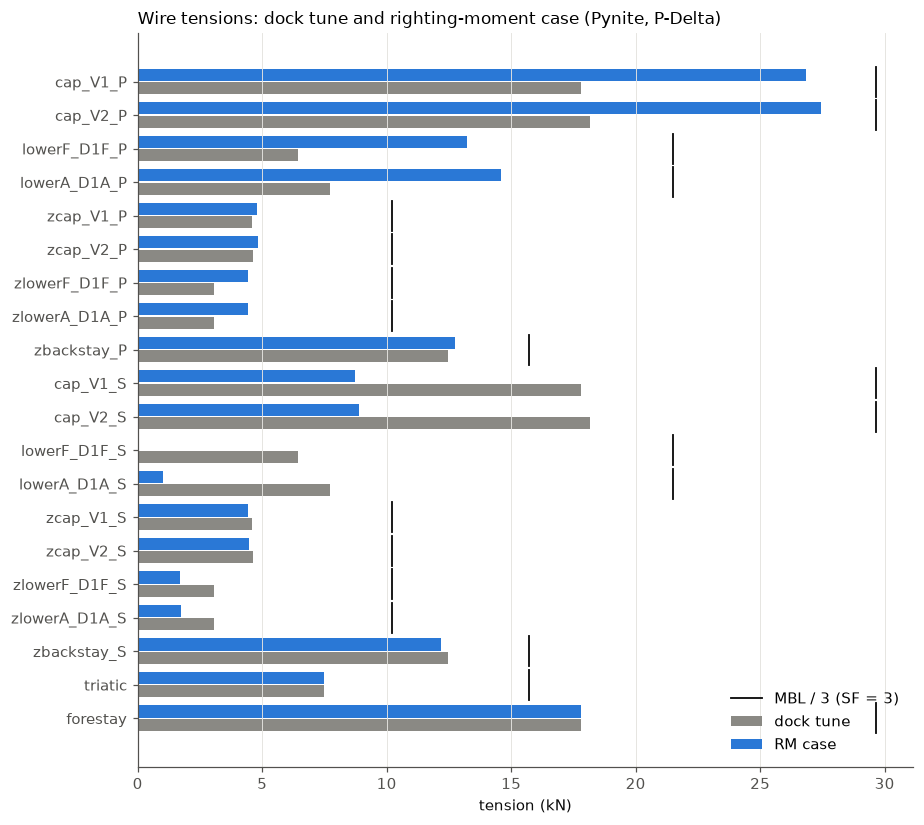

In [13]:
def plot_tensions(tt):
    segs = list(tt.index)
    y = np.arange(len(segs))
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(segs) + 1.2))
    ax.barh(y + 0.2, tt["dock (kN)"], height=0.36, color=C_GREY, label="dock tune")
    ax.barh(y - 0.2, tt["RM case (kN)"], height=0.36, color=C_PYNITE, label="RM case")
    for k, s in enumerate(segs):
        ax.plot([tt.loc[s, "MBL (kN)"] / 3] * 2, [k - 0.45, k + 0.45], color="#0b0b0b", lw=1.2)
    ax.plot([], [], color="#0b0b0b", lw=1.2, label="MBL / 3 (SF = 3)")
    ax.set_yticks(y, segs); ax.invert_yaxis()
    ax.set_xlabel("tension (kN)"); ax.grid(axis="y", visible=False)
    ax.set_title("Wire tensions: dock tune and righting-moment case (Pynite, P-Delta)", loc="left", fontsize=11)
    ax.legend(loc="lower right", frameon=False)
    plt.tight_layout(); plt.show()


plot_tensions(TT)

### What the tensions show (default placeholders)

- **At the dock, the mizzen backstays are the hardest-worked wires.** They hold the forestay's 17.8 kN tune
  through the triatic: the triatic carries 7.5 kN, and each 5/16 in mizzen backstay 12.5 kN (26% of MBL, SF 3.8).
  The backstays are steep, leading only about a quarter of their tension aft, so it takes a lot of tension to
  hold the triatic's pull.
- **The mizzen masthead moves 111 mm aft at the dock,** and the mizzen bows about 25 mm aft at mid-height. The
  main masthead follows it, 94 mm aft, through the triatic. With these placeholders the mizzen is the soft link
  in the forestay's support.
- **With full sails, the main caps govern:** 27.4 kN on the windward upper segment (31% of MBL, SF 3.2). The
  windward lowers reach 13–15 kN, the leeward forward lower goes slack and the leeward aft lower drops to 1 kN.
- **The mizzen hardly notices a steady sailing load** in this lumped case: its caps rise from 4.6 to 4.8 kN, and
  the triatic and mizzen backstays don't change. The genoa's one-third share at the masthead is mostly carried by
  the main's caps. §10's forestay-sag cases change that.

---
## §7 Bend of both masts, and the deformed rig

Displacements are measured from the **as-drawn geometry, in which every wire is stress-free**, so the
mastheads' dock movement includes the stays' own stretch (rake). The bend plots remove it by measuring from
each mast's chord, deck to masthead.

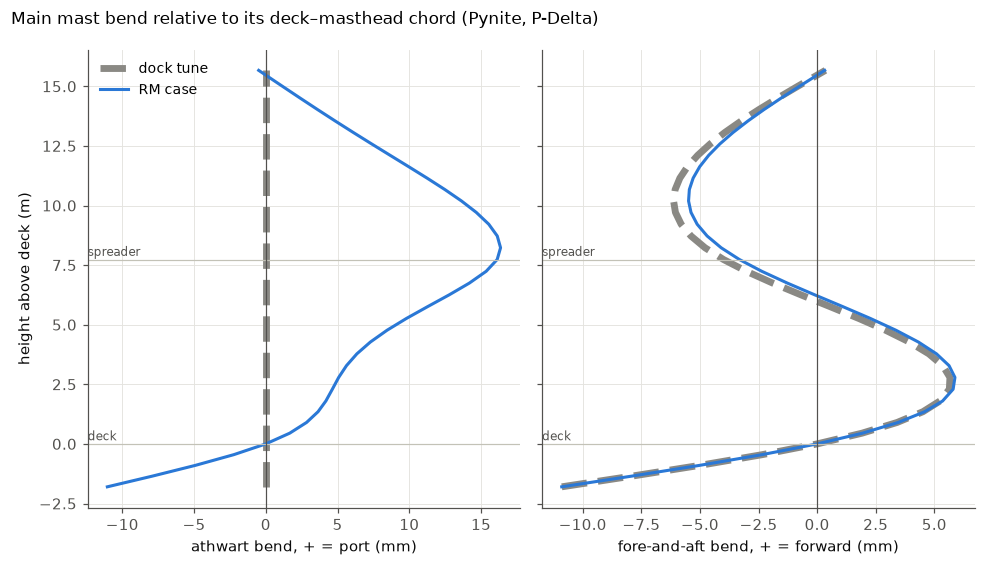

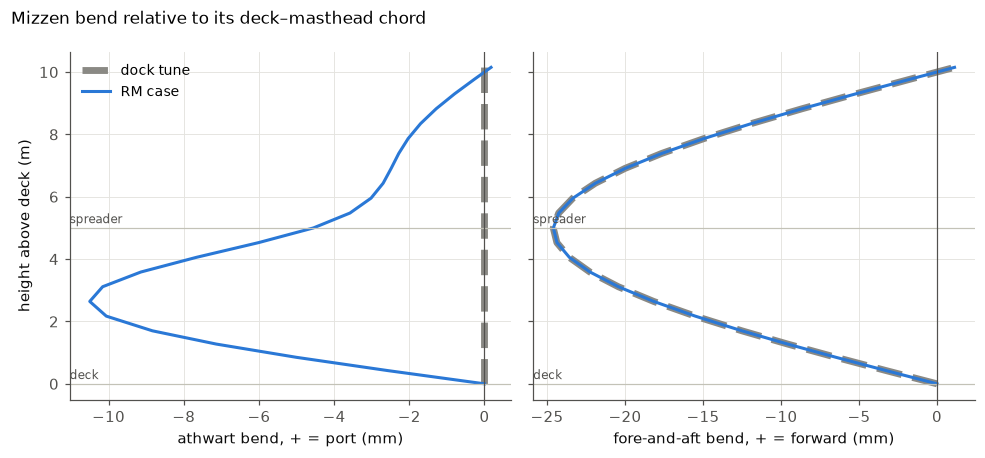

Dock: masthead  -93.6 mm fwd,   +0.0 mm port;  mizzen masthead -111.0 mm fwd,   +0.0 mm port
RM  : masthead  -93.6 mm fwd,  -94.9 mm port;  mizzen masthead -111.1 mm fwd,   -4.3 mm port
dock bow, main: -6.1 mm fore-and-aft at z = 10.2 m
dock bow, mizzen: -24.6 mm fore-and-aft at z = 5.0 m


In [14]:
def mast_curve(res, geo, comp, mast="main", chord=True):
    """Mast displacement along `comp` against height, measured from the deck-to-masthead chord if chord=True."""
    names, k_ = (geo["mast_nodes"], geo["key"]) if mast == "main" else (geo["mz_nodes"], geo["zkey"])
    zs = np.array([geo["nodes"][n][2] for n in names])
    u = np.array([res["disp"][n][comp] for n in names])
    if chord:
        h = k_["head"]
        u = u - res["disp"][h][comp] * zs / geo["nodes"][h][2]
    return zs, u


def plot_bend(curves, title, mast="main"):
    fig, axs = plt.subplots(1, 2, figsize=(9, 5.2 if mast == "main" else 4.2), sharey=True)
    for ax, comp, lab in zip(axs, (1, 0), ("athwart bend, + = port (mm)", "fore-and-aft bend, + = forward (mm)")):
        for k, (name, (res, color, ls)) in enumerate(curves.items()):
            z, u = mast_curve(res, GEO, comp, mast)
            ax.plot(u * 1e3, z, color=color, ls=ls, label=name, lw=4.5 if k == 0 else 2.0,
                    alpha=0.45 if k == 0 and len(curves) > 2 else 1.0)
        zs_ = GEO["z"]["s1"] if mast == "main" else GEO["z"]["mz_s1"]
        for zz, t in ((zs_, "spreader"), (0.0, "deck")):
            ax.axhline(zz, color="#c3c2b7", lw=0.8); ax.text(ax.get_xlim()[0], zz + 0.15, t, fontsize=8, color="#52514e")
        ax.axvline(0, color="#52514e", lw=0.8); ax.set_xlabel(lab)
    axs[0].set_ylabel("height above deck (m)")
    axs[0].legend(frameon=False, loc="upper left", fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()


plot_bend({"dock tune": (RES["Dock"], C_GREY, "--"), "RM case": (RES["RM"], C_PYNITE, "-")},
          "Main mast bend relative to its deck–masthead chord (Pynite, P-Delta)")
plot_bend({"dock tune": (RES["Dock"], C_GREY, "--"), "RM case": (RES["RM"], C_PYNITE, "-")},
          "Mizzen bend relative to its deck–masthead chord", mast="mizzen")
for c in ("Dock", "RM"):
    a_, b_ = RES[c]["disp"][head], RES[c]["disp"][zhead]
    print(f"{c:4s}: masthead {a_[0]*1e3:+6.1f} mm fwd, {a_[1]*1e3:+6.1f} mm port;  "
          f"mizzen masthead {b_[0]*1e3:+6.1f} mm fwd, {b_[1]*1e3:+6.1f} mm port")
for mast in ("main", "mizzen"):
    zb, ub = mast_curve(RES["Dock"], GEO, 0, mast)
    ub = np.where(zb >= 0.0, ub, 0.0)                   # above the deck only: the chord runs deck to masthead
    i_ = int(np.argmax(np.abs(ub)))
    print(f"dock bow, {mast}: {ub[i_]*1e3:+.1f} mm fore-and-aft at z = {zb[i_]:.1f} m")

**Linear against P-Delta**, for comparison. Sway amplification grows as about $1/(1 - 1/\lambda)$ (§8).

In [15]:
M_LIN = solve_pynite(params, GEO, DELTAS, LOADS, pdelta=False)
RES_LIN = {c: pynite_results(M_LIN, GEO, c) for c in ("Dock", "RM")}
display(pd.DataFrame({lab: {"masthead athwart (mm)": r["RM"]["disp"][head][1] * 1e3,
                            "mizzen masthead athwart (mm)": r["RM"]["disp"][zhead][1] * 1e3,
                            "windward cap V1 (kN)": r["RM"]["T"]["cap_V1_P"] / 1e3,
                            "windward mizzen cap V1 (kN)": r["RM"]["T"]["zcap_V1_P"] / 1e3,
                            "forestay (kN)": r["RM"]["T"]["forestay"] / 1e3}
                      for lab, r in (("linear", RES_LIN), ("P-Delta", RES))})
        .style.format("{:.1f}").set_caption("RM case, Pynite"))

,linear,P-Delta
masthead athwart (mm),-95.4,-94.9
mizzen masthead athwart (mm),-3.6,-4.3
windward cap V1 (kN),26.9,26.8
windward mizzen cap V1 (kN),4.8,4.8
forestay (kN),17.8,17.8


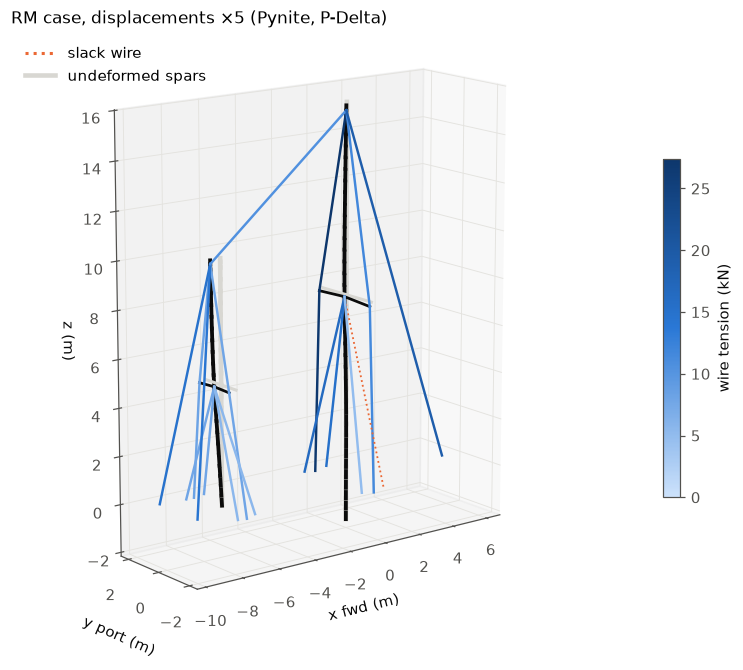

In [16]:
def plot_rig3d(geo, res, scale=20.0, title=""):
    n = geo["nodes"]
    P_ = lambda nm, s=0.0: np.add(n[nm], s * np.array(res["disp"][nm]))
    Tmax = max(res["T"].values())
    cmap = mcolors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
    fig = plt.figure(figsize=(9, 8)); ax = fig.add_subplot(projection="3d")
    for b in geo["beams"]:
        a0, b0 = P_(b["i"]), P_(b["j"]); a1, b1 = P_(b["i"], scale), P_(b["j"], scale)
        big = b["kind"] in MAST_KINDS
        ax.plot(*zip(a0, b0), color="#d8d7d2", lw=3 if big else 2)
        ax.plot(*zip(a1, b1), color="#0b0b0b", lw=2.5 if big else 1.8)
    for w in geo["wires"]:
        t = res["T"][w["name"]]
        a1, b1 = P_(w["i"], scale), P_(w["j"], scale)
        if t < 1.0:
            ax.plot(*zip(a1, b1), color=C_OPS_PD, lw=1.2, ls=":")
        else:
            ax.plot(*zip(a1, b1), color=cmap(0.15 + 0.85 * t / Tmax), lw=1.6)
    ax.plot([], [], color=C_OPS_PD, ls=":", label="slack wire")
    ax.plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    ax.set_xlabel("x fwd (m)"); ax.set_ylabel("y port (m)"); ax.set_zlabel("z (m)")
    xs = [v[0] for v in n.values()]; zs = [v[2] for v in n.values()]
    ax.set_ylim(-2.5, 2.5); ax.set_yticks([-2, 0, 2])
    ax.set_box_aspect((np.ptp(xs), 5.0, np.ptp(zs)))
    ax.view_init(elev=14, azim=-128)
    sm = cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(0, Tmax / 1e3))
    fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.08, label="wire tension (kN)")
    ax.legend(loc="upper left", frameon=False); ax.set_title(title, loc="left", fontsize=11)
    plt.show()


plot_rig3d(GEO, RES["RM"], scale=5, title="RM case, displacements ×5 (Pynite, P-Delta)")

---
## §8 Buckling: linear eigenvalue from Pynite's $K$ and $K_g$

The buckling load factor $\lambda$ is the smallest positive root of $(K + \lambda K_g)\phi = 0$ over the free
DOFs, with $K_g$ from the solved axial forces. With two masts, each mode is labelled by **which mast moves
most** and whether it sways or twists. The pinned-panel Euler estimate, $P_{cr} = \pi^2 E I / L^2$ on the
weaker axis, is given for each panel of each mast as a floor. The torsional-flexural check (Timoshenko &
Gere, in AISC's singly-symmetric form) runs on the main, closed and with the slotted what-if:

$$P_T = \frac{GJ + \pi^2 E C_w / L^2}{r_0^2},\qquad r_0^2 = x_0^2 + \frac{I_{fa} + I_{ath}}{A},\qquad H = 1 - \frac{x_0^2}{r_0^2}$$

$$P_{TF} = \frac{P_e + P_T}{2H}\left[1 - \sqrt{1 - \frac{4 P_e P_T H}{(P_e + P_T)^2}}\right],\qquad P_e = \frac{\pi^2 E I_{ath}}{L^2}$$

In [17]:
def buckling_factor(m, combo, nmodes=3):
    D1, _, _ = _partition_D(m)
    K = m.K(combo, sparse=True, check_stability=False).toarray()
    Kg = m.Kg(combo, sparse=True, first_step=False).toarray()   # Pynite 1.0.1's dense branch has a zeros(n, n) bug
    K11, Kg11 = K[np.ix_(D1, D1)], Kg[np.ix_(D1, D1)]
    vals, vecs = sla.eig(K11, -Kg11)
    vals = np.real_if_close(vals)
    ok = np.isfinite(vals) & (np.abs(np.imag(vals)) < 1e-9) & (np.real(vals) > 1e-6)
    order = np.argsort(np.real(vals[ok]))
    lam = np.real(vals[ok])[order][:nmodes]
    phi = np.real(vecs[:, ok][:, order[:nmodes]])
    full = np.zeros((len(m.nodes) * 6, phi.shape[1])); full[D1, :] = phi
    return lam, full


def mode_kind(m, geo, phi, k):
    """Which mast dominates mode k, and whether it sways or twists (twist times the half-chord)."""
    out = {}
    for mast, names, r in (("main", geo["mast_nodes"], params.mast_chord / 2e3), ("mizzen", geo["mz_nodes"], params.mz_chord / 2e3)):
        ids = [m.nodes[n].ID for n in names]
        out[mast] = (max(np.hypot(phi[i * 6 + 0, k], phi[i * 6 + 2, k]) for i in ids),
                     max(abs(phi[i * 6 + 4, k]) for i in ids) * r)
    mast = max(out, key=lambda s: max(out[s]))
    sway, twist = out[mast]
    return f"{mast}, {'flexural' if sway >= twist else 'torsional'}"


def panel_table(p, geo, res):
    rows = []
    for mast, Nd, sec, zl in (("main", res["mast_N"], MAST, [0.0, geo["z"]["s1"], geo["z"]["head"]]),
                              ("mizzen", res["mz_N"], MZ, [0.0, geo["z"]["mz_s1"], geo["z"]["mz_head"]])):
        names = geo["mast_nodes"] if mast == "main" else geo["mz_nodes"]
        for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), ("deck–spreader", "spreader–head")):
            N = max(v for n, v in Nd.items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
            L = zb - za
            Pcr = math.pi**2 * p.E_al * min(sec["I_fa"], sec["I_ath"]) / L**2
            rows.append({"mast": mast, "panel": nm, "L (m)": L, "peak N (kN)": N / 1e3, "Euler Pcr (kN)": Pcr / 1e3, "Pcr / N": Pcr / N})
    return pd.DataFrame(rows).set_index(["mast", "panel"])


LAM, PHI = buckling_factor(M_PY, "RM", 6)
LAM_DOCK, PHI_DOCK = buckling_factor(M_PY, "Dock", 6)
KINDS = [mode_kind(M_PY, GEO, PHI, k) for k in range(len(LAM))]
display(pd.DataFrame({"λ RM case": LAM, "mode (RM)": KINDS, "λ dock": LAM_DOCK,
                      "mode (dock)": [mode_kind(M_PY, GEO, PHI_DOCK, k) for k in range(len(LAM_DOCK))]},
                     index=pd.RangeIndex(1, len(LAM) + 1, name="mode")).style.format({"λ RM case": "{:.2f}", "λ dock": "{:.2f}"}))
display(panel_table(params, GEO, RES["RM"]).style.format("{:.2f}"))


def torsional_flexural(p, geo, res, sec_props):
    zl = [0.0, geo["z"]["s1"], geo["z"]["head"]]; rows = []
    for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), ("deck–spreader", "spreader–head")):
        N = max(v for n, v in res["mast_N"].items() if za - 1e-9 <= geo["nodes"][n][2] < zb)
        L = zb - za
        for label, sp in sec_props.items():
            A, x0 = sp["A"], sp["x_sc"]
            r0sq = x0**2 + (sp["I_fa"] + sp["I_ath"]) / A
            H = 1 - x0**2 / r0sq
            Pe = math.pi**2 * p.E_al * sp["I_ath"] / L**2
            PT = (p.G_al * sp["J"] + math.pi**2 * p.E_al * sp["Cw"] / L**2) / r0sq
            PTF = (Pe + PT) / (2 * H) * (1 - math.sqrt(max(0.0, 1 - 4 * Pe * PT * H / (Pe + PT)**2)))
            rows.append({"panel": nm, "section": label, "peak N (kN)": N / 1e3, "P_e (kN)": Pe / 1e3,
                         "P_T (kN)": PT / 1e3, "P_TF (kN)": PTF / 1e3, "P_TF / N": PTF / N})
    return pd.DataFrame(rows).set_index(["panel", "section"])


TF = torsional_flexural(params, GEO, RES["RM"], {"main, closed oval (as modelled)": {**SEC["closed"], **{k: MAST[k] for k in ("A", "I_fa", "I_ath")}},
                                                 "main, what-if slotted for in-mast furling": SEC["slotted"]})
display(TF.style.format("{:.2f}"))

,λ RM case,mode (RM),λ dock,mode (dock)
mode,,,,
1,3.05,"mizzen, flexural",3.05,"mizzen, flexural"
2,3.57,"main, flexural",3.59,"main, flexural"
3,3.87,"mizzen, flexural",3.87,"mizzen, flexural"
4,5.10,"main, flexural",5.56,"main, flexural"
5,5.98,"mizzen, flexural",5.98,"mizzen, flexural"
6,6.10,"mizzen, flexural",6.10,"mizzen, flexural"


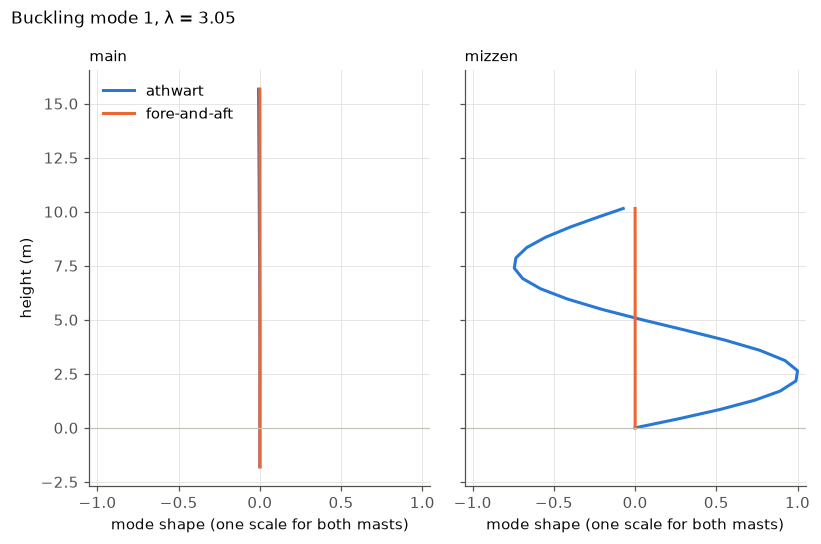

In [18]:
def plot_mode(m, geo, phi, lam, k=0):
    fig, axs = plt.subplots(1, 2, figsize=(7.5, 5.0), sharey=True)
    peak = max(np.max(np.abs([to_boat(phi[m.nodes[n].ID * 6:m.nodes[n].ID * 6 + 3, k]) for n in names]))
               for names in (geo["mast_nodes"], geo["mz_nodes"]))
    for ax, names, lab in ((axs[0], geo["mast_nodes"], "main"), (axs[1], geo["mz_nodes"], "mizzen")):
        z = np.array([geo["nodes"][n][2] for n in names])
        u = np.array([to_boat(phi[m.nodes[n].ID * 6:m.nodes[n].ID * 6 + 3, k]) for n in names]) / peak
        ax.plot(u[:, 1], z, color=C_PYNITE, label="athwart"); ax.plot(u[:, 0], z, color=C_OPS_PD, label="fore-and-aft")
        ax.axhline(0, color="#c3c2b7", lw=0.8); ax.set_xlim(-1.05, 1.05); ax.set_title(lab, loc="left", fontsize=10)
        ax.set_xlabel("mode shape (one scale for both masts)")
    axs[0].set_ylabel("height (m)"); axs[0].legend(frameon=False, loc="upper left")
    fig.suptitle(f"Buckling mode {k+1}, λ = {lam[k]:.2f}", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()


plot_mode(M_PY, GEO, PHI, LAM, 0)

### What the buckling numbers say (placeholder sections and geometry)

- **The first buckling mode is the mizzen's, λ ≈ 3.05,** at the dock and sailing alike, with the main's first
  mode next at 3.6. The mizzen carries 40 kN of compression from its own tune plus the triatic's pull, on a
  section a third as stiff as the main's. Pretension sets the margin: the sailing load barely changes it.
- **The pinned-panel Euler floors** are 2.2 for the main's lower panel (7.7 m) and 2.7 for the mizzen's. The frame
  does better because each mast is continuous and the wires stiffen it.
- **Torsional-flexural buckling doesn't arise for the closed ovals.** The slotted what-if for the main fails it
  ($P_{TF}/N = 0.66$ in the lower panel), the same lesson as the other two studies: an in-mast furling mast
  needs internal walls.

---
## §9 Cross-check: OpenSeesPy

**How it runs.** The model goes to OpenSeesPy as JSON, runs in a separate Python process, and comes back the same way, as with CalculiX or Elmer. The notebook uses the first interpreter that can import `openseespy`: the one named in the environment variable `RIGFRAME_OPENSEES_PYTHON`, the notebook's own, or a sidecar venv at `~/python-venvs/opensees-py312`. OpenSeesPy 3.8's Windows build links `python312.dll`, so on Windows that has to be Python 3.12; on Linux and Colab, 3.12 or later. If none is found, these checks report **SKIP**. Its license allows research, education and internal use; it isn't OSI open source.

The OpenSees model uses the same nodes and sections: `elasticBeamColumn` spars, `corotTruss` wires on
tension-only `InitStrainMaterial`, pretension first, then the sail load in ten steps, once with the `PDelta`
transformation and once with `Corotational` (the reference).

**What the comparison found:**

- **Corotational OpenSees and P-Delta Pynite agree within 0.4% on every wire of the triatic rig,** forestay and
  triatic included, and within 0.06% on masthead sway (check 8). Check 13 repeats the comparison on the split
  rig.
- **Second-order shortening shows up again, and this time it's measured.** A mast that bends or rakes drops its
  head by about $\tfrac12\int (du/dz)^2 dz$, which linear-strain elements leave out. From Pynite's own dock shapes
  (bend and rake together) that is 0.31 mm for the main and 0.76 mm for the mizzen, which rakes 111 mm aft.
  OpenSees corotational puts the mastheads 0.30 and 0.76 mm lower. On the split rig the mizzen's short, lightly loaded stays (about 10 mm of stretch) feel that as a
  1.3–1.5% tension difference, so check 13 gives them a documented 2.5% band.
- **OpenSees's own `PDelta` transformation runs high again:** 0.4–2% on the main wires and up to 6.5% on the
  mizzen lowers (information table after §12). The corotational run is the reference.

In [19]:
OPS_SCRIPT = r'''
import json, sys
import openseespy.opensees as ops

def run(model, transf):
    ops.wipe(); ops.model("basic", "-ndm", 3, "-ndf", 6)
    tag = {}
    for k, (nm, xyz) in enumerate(model["nodes"].items(), start=1):
        tag[nm] = k; ops.node(k, *xyz)
    for nm, fix in model["fix"].items():
        ops.fix(tag[nm], *fix)
    ttags = {}
    for k, b in enumerate(model["beams"], start=1):
        vz = tuple(round(v, 12) for v in b["vecxz"])
        if vz not in ttags:
            ttags[vz] = len(ttags) + 1
            ops.geomTransf(transf, ttags[vz], *vz)
        extra = ["-releasez", 1] if b.get("release_z_i") else []
        ops.element("elasticBeamColumn", k, tag[b["i"]], tag[b["j"]], b["A"], b["E"], b["G"], b["J"],
                    b["Iy"], b["Iz"], ttags[vz], *extra)
    nb = len(model["beams"])
    for k, w in enumerate(model["wires"], start=1):
        ops.uniaxialMaterial("Elastic", 2 * k - 1, w["E"], 0.0, 0.0)
        ops.uniaxialMaterial("InitStrainMaterial", 2 * k, 2 * k - 1, w["eps0"])
        ops.element("Truss" if transf == "Linear" else "corotTruss", nb + k, tag[w["i"]], tag[w["j"]], w["A"], 2 * k)
    nw, base = len(model["wires"]), len(tag) + 1
    for k, sp in enumerate(model.get("springs", [])):
        g, mt = base + k, 2 * nw + 1 + k
        ops.node(g, *ops.nodeCoord(tag[sp["node"]])); ops.fix(g, 1, 1, 1, 1, 1, 1)
        ops.uniaxialMaterial("Elastic", mt, sp["k"])
        ops.element("zeroLength", nb + nw + 1 + k, g, tag[sp["node"]], "-mat", mt, mt, mt, "-dir", 1, 2, 3)

    def solve(nsteps):
        ops.constraints("Transformation"); ops.numberer("RCM"); ops.system("UmfPack")
        ops.test("NormDispIncr", 1e-10, 200); ops.algorithm("Newton")
        ops.integrator("LoadControl", 1.0 / nsteps); ops.analysis("Static")
        for s in range(nsteps):
            if ops.analyze(1) != 0:
                ops.algorithm("KrylovNewton")
                if ops.analyze(1) != 0:
                    raise RuntimeError(f"no convergence at step {s}")
                ops.algorithm("Newton")

    def collect():
        ops.reactions()
        axial = lambda kind: {b["i"]: ops.eleResponse(k, "localForce")[0]          # i-end axial, + = compression
                              for k, b in enumerate(model["beams"], start=1) if b["kind"] == kind}
        return {"disp": {nm: ops.nodeDisp(t)[:3] for nm, t in tag.items()},
                "T": {w["name"]: ops.eleResponse(nb + k, "axialForce")[0] for k, w in enumerate(model["wires"], start=1)},
                "rxn": {nm: ops.nodeReaction(tag[nm]) for nm in model["fix"]},
                "mast_N": axial("mast"), "mz_N": axial("mizzen"),
                "lf": [ops.eleResponse(k, "localForce") for k in range(1, len(model["beams"]) + 1)]}

    ops.timeSeries("Constant", 1); ops.pattern("Plain", 1, 1)
    solve(1)
    dock = collect()
    ops.loadConst("-time", 0.0)
    ops.timeSeries("Linear", 2); ops.pattern("Plain", 2, 2)
    for nm, v in model["loads"].items():
        ops.load(tag[nm], *v)
    solve(model.get("nsteps", 10))
    return {"Dock": dock, "RM": collect()}

model = json.load(open(sys.argv[1]))
out = {tr: run(model, tr) for tr in model["transfs"]}
json.dump(out, open(sys.argv[2], "w"))
'''

def find_opensees_python():
    """An interpreter that can import openseespy: $RIGFRAME_OPENSEES_PYTHON, this one, or a sidecar venv.
    None means the OpenSees cross-check is skipped."""
    import sys
    home = Path.home() / "python-venvs" / "opensees-py312"
    for c in (os.environ.get("RIGFRAME_OPENSEES_PYTHON"), sys.executable, home / "Scripts" / "python.exe", home / "bin" / "python"):
        if c and Path(c).exists() and subprocess.run([str(c), "-c", "import openseespy.opensees"],
                                                     capture_output=True).returncode == 0:
            return Path(c)
    return None


OPS_PY = find_opensees_python()
print("OpenSees cross-check:", "will run" if OPS_PY else "openseespy not found, so it will SKIP")


def pynite_local_z(m, name):
    return tuple(float(v) for v in m.members[name].T()[2, :3])     # third row = local z in global coordinates


def opensees_model(p, geo, deltas, loads, m_ref):
    model = {"nodes": {n: to_solver(xyz) for n, xyz in geo["nodes"].items()}, "fix": {}, "beams": [], "wires": [],
             "loads": {}, "transfs": ["PDelta", "Corotational"]}
    for nm, fix in geo["supports"].items():
        t, r = to_solver(fix[:3]), to_solver(fix[3:])
        model["fix"][nm] = [int(bool(abs(v))) for v in (*t, *r)]
    for b in geo["beams"]:
        s_ = SPARS[b["kind"]]
        if b["kind"] in MAST_KINDS:
            A, Iy, Iz, J = s_["A"], s_["I_ath"], s_["I_fa"], s_["J"]
        else:
            A, Iy, Iz, J = s_["A"], s_["I_horiz"], s_["I_vert"], s_["J"]
        model["beams"].append({"i": b["i"], "j": b["j"], "kind": b["kind"], "A": A, "E": p.E_al, "G": p.G_al,
                               "J": J, "Iy": Iy, "Iz": Iz, "vecxz": pynite_local_z(m_ref, b["name"]),
                               "release_z_i": b["kind"].endswith("spreader") and p.release_spreader_root})
    for w in geo["wires"]:
        d = deltas.get(w["group"], 0.0) if w["bottom"] else 0.0
        model["wires"].append({"name": w["name"], "i": w["i"], "j": w["j"], "A": wire_props(p.wire[w["group"]])["A"],
                               "E": p.E_wire, "eps0": d / seg_len(geo, w)})
    for nm, v in loads.items():
        model["loads"][nm] = [*to_solver(v[:3]), *to_solver(v[3:])]
    model["springs"] = [{"node": nm, "k": 1.0} for nm in geo["stay_interior"]]
    return model


def run_opensees(model):
    if OPS_PY is None:
        return None
    work = Path(tempfile.mkdtemp(prefix="rig_ops_"))           # a temporary folder, removed afterwards
    try:
        (work / "ops_rig.py").write_text(OPS_SCRIPT)
        (work / "model.json").write_text(json.dumps(model))
        r = subprocess.run([str(OPS_PY), "-I", str(work / "ops_rig.py"), str(work / "model.json"), str(work / "out.json")],
                           capture_output=True, text=True, timeout=600)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-3000:])
        raw = json.loads((work / "out.json").read_text())
    finally:
        shutil.rmtree(work, ignore_errors=True)
    out = {}
    for tr, cases in raw.items():
        out[tr] = {c: {"T": d["T"], "disp": {n: to_boat(v) for n, v in d["disp"].items()},
                       "rxn": {n: np.array([*to_boat(v[:3]), *to_boat(v[3:])]) for n, v in d["rxn"].items()},
                       "mast_N": d["mast_N"], "mz_N": d["mz_N"], "lf": d.get("lf")} for c, d in cases.items()}
    return out


t0 = time.perf_counter()
OPS = run_opensees(opensees_model(params, GEO, DELTAS, LOADS, M_PY))
print("OpenSees:", "openseespy not found -> SKIP" if OPS is None else f"ran in {time.perf_counter()-t0:.1f} s")

OpenSees cross-check: will run


OpenSees: ran in 1.4 s


,Pynite dock,OPS PDelta dock,Pynite RM,OPS PDelta RM,OPS corot RM
segment,,,,,
cap_V1_P,17.79,17.95,26.85,27.19,26.83
cap_V2_P,18.16,18.32,27.43,27.78,27.41
lowerF_D1F_P,6.45,6.59,13.22,13.35,13.20
lowerA_D1A_P,7.74,7.84,14.57,14.63,14.57
zcap_V1_P,4.60,4.81,4.79,4.99,4.77
zcap_V2_P,4.64,4.85,4.82,5.03,4.80
zlowerF_D1F_P,3.07,3.48,4.42,4.83,4.39
zlowerA_D1A_P,3.07,3.35,4.42,4.70,4.40
zbackstay_P,12.45,12.63,12.73,12.97,12.71


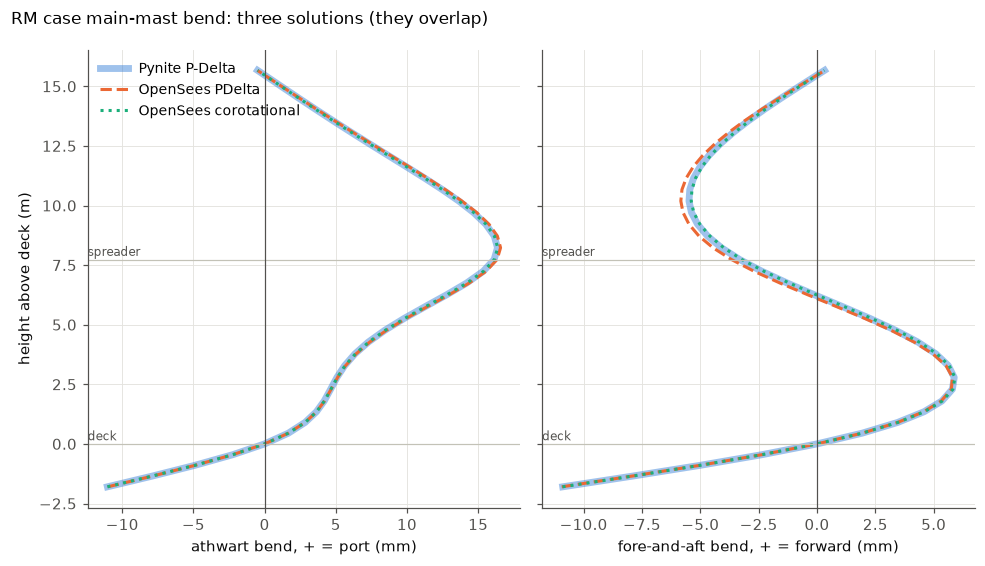

dock bow shortening, main: 0.31 mm (Pynite curve); OpenSees corotational puts the main masthead -0.30 mm relative to Pynite
dock bow shortening, mizzen: 0.76 mm (Pynite curve); OpenSees corotational puts the mizzen masthead -0.76 mm relative to Pynite


In [20]:
if OPS is not None:
    CMP = pd.DataFrame([{"segment": w["name"],
                         "Pynite dock": RES["Dock"]["T"][w["name"]] / 1e3, "OPS PDelta dock": OPS["PDelta"]["Dock"]["T"][w["name"]] / 1e3,
                         "Pynite RM": RES["RM"]["T"][w["name"]] / 1e3, "OPS PDelta RM": OPS["PDelta"]["RM"]["T"][w["name"]] / 1e3,
                         "OPS corot RM": OPS["Corotational"]["RM"]["T"][w["name"]] / 1e3} for w in GEO["wires"]]).set_index("segment")
    display(CMP.style.format("{:.2f}").set_caption("wire tension (kN)"))
    plot_bend({"Pynite P-Delta": (RES["RM"], C_PYNITE, "-"), "OpenSees PDelta": (OPS["PDelta"]["RM"], C_OPS_PD, "--"),
               "OpenSees corotational": (OPS["Corotational"]["RM"], C_OPS_CR, ":")},
              "RM case main-mast bend: three solutions (they overlap)")

    def bow_shortening(res, mast):
        z_, ux = mast_curve(res, GEO, 0, mast, chord=False)
        k = z_ >= 0.0
        return 0.5 * np.trapezoid(np.gradient(ux[k], z_[k])**2, z_[k])
    for mast, h_ in (("main", head), ("mizzen", zhead)):
        dz = OPS["Corotational"]["Dock"]["disp"][h_][2] - RES["Dock"]["disp"][h_][2]
        print(f"dock bow shortening, {mast}: {bow_shortening(RES['Dock'], mast)*1e3:.2f} mm (Pynite curve); "
              f"OpenSees corotational puts the {mast} masthead {dz*1e3:+.2f} mm relative to Pynite")

---
## §10 Load cases side by side

One table with every case. The first block runs on the triatic rig, the second on the same boat with
split backstays and no triatic, retuned to the same targets.

| Case | What it represents |
|---|---|
| Dock tune | Preload only |
| Full sails, RM ×1.0 and ×1.5 | Genoa, main and mizzen |
| Jib and jigger, RM ×1.0 | Genoa and mizzen, main down: the ketch's usual rig for a blow |
| Reefed main only, RM ×1.0 | Main reefed to `reef_fraction` of P, nothing else |
| Forestay sag, RM ×1.0 and ×1.5 | Full sails with the genoa's load along the forestay |
| Jib and jigger, forestay sag | The blow rig with the genoa along the forestay |
| Split backstays: dock, full sails, forestay sag | The same boat with no triatic, each mast standing on its own |

**Why the sag cases use the corotational solver:** a sagging stay's tension rises through second-order
stretch, $\tfrac12\int (dy/ds)^2\,ds$, which a linearised P-Delta solve (Pynite) leaves out. On a ketch with a
triatic, that rise goes straight through the triatic into the mizzen backstays. **Hand bound** for a stay with
rigid ends (Irvine): $\dfrac{(T - T_0)L}{EA} = \dfrac{1}{2T^2}\int_0^L V(s)^2\,ds$.

In [21]:
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import brentq


def cable_T_fixed_ends(T0, L, EA, w_of_s, n=4000):
    """Tension in a pretensioned cable with rigid ends under a transverse load w(s), small-sag theory."""
    s_ = np.linspace(0.0, L, n + 1)
    w_ = w_of_s(s_)
    R0 = np.trapezoid((L - s_) * w_, s_) / L
    V = R0 - cumulative_trapezoid(w_, s_, initial=0.0)
    I2 = np.trapezoid(V**2, s_)
    return brentq(lambda T: (T - T0) * L / EA - I2 / (2 * T**2), T0, T0 + 1e8)


def stay_sag_mm(geo, res, group="forestay"):
    seq = geo["stays"][group]
    if len(seq) < 3:
        return np.nan
    P_ = [np.add(geo["nodes"][n], res["disp"][n]) for n in seq]
    a, b = P_[0], P_[-1]
    u = (b - a) / np.linalg.norm(b - a)
    return 1e3 * max(np.linalg.norm((q - a) - np.dot(q - a, u) * u) for q in P_[1:-1])


def summarize(label, solver, geo, p, res, lam=np.nan, bound=np.nan):
    T = res["T"]
    mbl = {w["name"]: wire_props(p.wire[w["group"]])["MBL"] for w in geo["wires"]}
    sf = {n: mbl[n] / t for n, t in T.items() if t > 500.0}
    gov = min(sf, key=sf.get)
    hd, zd = res["disp"][geo["key"]["head"]], res["disp"][geo["zkey"]["head"]]
    return {"case": label, "solver": solver,
            "cap V2 wwd (kN)": T["cap_V2_P"] / 1e3, "fwd lower wwd (kN)": T["lowerF_D1F_P"] / 1e3,
            "aft lower wwd (kN)": T["lowerA_D1A_P"] / 1e3,
            "forestay (kN)": max(t for n, t in T.items() if GROUP_OF.get(n) == "forestay") / 1e3, "forestay bound (kN)": bound / 1e3,
            "triatic (kN)": T.get("triatic", np.nan) / 1e3, "main backstay wwd (kN)": T.get("backstay_P", np.nan) / 1e3,
            "mizzen cap V2 wwd (kN)": T["zcap_V2_P"] / 1e3, "mizzen aft lower wwd (kN)": T["zlowerA_D1A_P"] / 1e3,
            "mizzen backstay wwd (kN)": T["zbackstay_P"] / 1e3, "mizzen forestay (kN)": T.get("zforestay", np.nan) / 1e3,
            "min SF": sf[gov], "governing wire": gov,
            "main N max (kN)": max(res["mast_N"].values()) / 1e3, "mizzen N max (kN)": max(res["mz_N"].values()) / 1e3,
            "masthead fwd (mm)": hd[0] * 1e3, "masthead athwart (mm)": hd[1] * 1e3,
            "mizzen head fwd (mm)": zd[0] * 1e3, "mizzen head athwart (mm)": zd[1] * 1e3,
            "forestay sag (mm)": stay_sag_mm(geo, res), "λ": lam,
            "slack (< 0.5 kN)": ", ".join(n for n, t in T.items() if t < 500.0) or "none"}


def section_stress(N, M_fa, M_ath, kind, p=params):
    """Peak |stress| (Pa): |N|/A plus the two bending stresses combined at the worst point of an oval outline.
    For a spreader, 'fa' is bending in the vertical plane and 'ath' bending in the horizontal plane."""
    s_ = SPARS[kind]
    if kind in MAST_KINDS:
        s1, s2 = M_fa * s_["c_fa"] / s_["I_fa"], M_ath * s_["c_ath"] / s_["I_ath"]
    else:
        s1, s2 = M_fa * s_["c_vert"] / s_["I_vert"], M_ath * s_["c_horiz"] / s_["I_horiz"]
    return abs(N) / s_["A"] + math.hypot(s1, s2)


def beam_stresses_pynite(m, geo, combo):
    out = {}
    for b in geo["beams"]:
        mem = m.members[b["name"]]
        cands = []
        for x in (0.0, mem.L() / 2, mem.L()):
            N, Mz, My = mem.axial(x, combo), mem.moment("Mz", x, combo), mem.moment("My", x, combo)
            cands.append((section_stress(N, Mz, My, b["kind"]), N, Mz, My))
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


def beam_stresses_ops(res, geo):
    out = {}
    for b, lf in zip(geo["beams"], res["lf"]):
        cands = [(section_stress(lf[0], lf[5], lf[4], b["kind"]), lf[0], lf[5], lf[4]),
                 (section_stress(lf[6], lf[11], lf[10], b["kind"]), -lf[6], lf[11], lf[10])]
        out[b["name"]] = max(cands, key=lambda c: c[0])
    return out


def run_case_set(p, geo, deltas, tag, m_dock=None, with_dock=True, pyn_cases=(), sag_cases=(), geo_fs=None, deltas_fs=None):
    """Run Pynite cases on geo and corotational stay-sag cases on geo_fs; add rows to ROWS and STRESS."""
    if with_dock:
        lam_d = buckling_factor(m_dock, "Dock", 1)[0][0]
        r_d = pynite_results(m_dock, geo, "Dock")
        lab = f"{tag}Dock tune"
        ROWS.append(summarize(lab, "Pynite P-Delta", geo, p, r_d, lam_d))
        STRESS[lab] = {"geo": geo, "p": p, "solver": "Pynite P-Delta", "T": r_d["T"], "s": beam_stresses_pynite(m_dock, geo, "Dock"),
                       "res": r_d, "info": None, "lam": lam_d, "loads": {}}
    for label, kw in pyn_cases:
        pc = replace(p, **kw)
        ld, inf_ = rm_loads(pc, geo)
        mc_ = solve_pynite(pc, geo, deltas, ld)
        r_ = pynite_results(mc_, geo, "RM")
        lam_ = buckling_factor(mc_, "RM", 1)[0][0]
        ROWS.append(summarize(tag + label, "Pynite P-Delta", geo, pc, r_, lam_))
        STRESS[tag + label] = {"geo": geo, "p": pc, "solver": "Pynite P-Delta", "T": r_["T"], "s": beam_stresses_pynite(mc_, geo, "RM"),
                               "res": r_, "info": inf_, "lam": lam_, "loads": ld}
    for label, kw, with_pynite_row in sag_cases:
        pc = replace(p, **kw)
        ld, inf = rm_loads(pc, geo_fs, stay_sag=True)
        m_fs = solve_pynite(pc, geo_fs, deltas_fs, ld)
        r_py = pynite_results(m_fs, geo_fs, "RM")
        T0 = pynite_results(m_fs, geo_fs, "Dock")["T"]["forestay"]
        L_fs = group_len(geo_fs, "forestay")
        bound = cable_T_fixed_ends(T0, L_fs, wire_props(pc.wire["forestay"])["A"] * pc.E_wire,
                                   lambda s, F=inf["F_genoa"], L=L_fs: 2 * F / L * (1 - s / L))
        SAG[tag + label] = {"loads": ld, "info": inf, "pynite": r_py, "bound": bound, "T0": T0, "geo": geo_fs}
        if with_pynite_row:
            ROWS.append(summarize(tag + label, "Pynite P-Delta", geo_fs, pc, r_py, buckling_factor(m_fs, "RM", 1)[0][0], bound))
        mod = opensees_model(pc, geo_fs, deltas_fs, ld, m_fs)
        mod["transfs"] = ["Corotational"]
        o = run_opensees(mod)
        SAG[tag + label]["ops"] = None if o is None else o["Corotational"]["RM"]
        if o is not None:
            ro = o["Corotational"]["RM"]
            ROWS.append(summarize(tag + label, "OpenSees corotational", geo_fs, pc, ro, np.nan, bound))
            STRESS[tag + label] = {"geo": geo_fs, "p": pc, "solver": "OpenSees corotational", "T": ro["T"],
                                   "s": beam_stresses_ops(ro, geo_fs), "res": ro, "info": inf, "lam": np.nan, "bound": bound, "loads": ld}
        else:
            print(f"{tag + label}: OpenSees openseespy not found, corotational row skipped")


t0 = time.perf_counter()
ROWS, STRESS, SAG = [], {}, {}
PYN_CASES = [("Full sails, RM ×1.0", dict(sail_plan="full", RM_factor=1.0)),
             ("Full sails, RM ×1.5", dict(sail_plan="full", RM_factor=1.5)),
             ("Jib and jigger, RM ×1.0", dict(sail_plan="jib_and_jigger", RM_factor=1.0)),
             (f"Reefed main only ({params.reef_fraction:.0%} of P), RM ×1.0", dict(sail_plan="reefed_main_only", RM_factor=1.0))]
SAG_CASES = [("Forestay sag, RM ×1.0", dict(sail_plan="full", RM_factor=1.0), True),
             ("Forestay sag, RM ×1.5", dict(sail_plan="full", RM_factor=1.5), False),
             ("Jib and jigger, forestay sag, RM ×1.0", dict(sail_plan="jib_and_jigger", RM_factor=1.0), False)]
GEO_FS = rig_geometry(params, segmented_stays=True)
DELTAS_FS, _, _ = tune(params, GEO_FS)
run_case_set(params, GEO, DELTAS, "", M_PY, True, PYN_CASES, SAG_CASES, GEO_FS, DELTAS_FS)

# the same boat with split backstays and no triatic, retuned to the same targets
P_SPLIT = replace(params, backstay_arrangement="split")
GEO_SP = rig_geometry(P_SPLIT)
DELTAS_SP, T_TUNED_SP, T_TARGET_SP = tune(P_SPLIT, GEO_SP)
GEO_SP_FS = rig_geometry(P_SPLIT, segmented_stays=True)
DELTAS_SP_FS, _, _ = tune(P_SPLIT, GEO_SP_FS)
M_SP = solve_pynite(P_SPLIT, GEO_SP, DELTAS_SP, rm_loads(P_SPLIT, GEO_SP)[0])
run_case_set(P_SPLIT, GEO_SP, DELTAS_SP, "Split backstays: ", M_SP, True, PYN_CASES[:1], SAG_CASES[:1], GEO_SP_FS, DELTAS_SP_FS)
SAG1 = SAG[SAG_CASES[0][0]]

SUMMARY = pd.DataFrame(ROWS).set_index(["case", "solver"])
print(f"{len(ROWS)} rows in {time.perf_counter()-t0:.1f} s")
num = {c: "{:.1f}" for c in SUMMARY.columns if SUMMARY[c].dtype.kind == "f"}
num.update({"min SF": "{:.2f}", "λ": "{:.2f}"})
display(SUMMARY.style.format(num, na_rep="—")
        .set_caption("Every case. wwd = windward (port). Pynite rows use two-cycle P-Delta; the corotational rows "
                     "include the forestay's second-order stretch. Wires starting with z are the mizzen's."))

13 rows in 125.5 s


### Spar stresses

For each element of either mast, and each spreader,

$$\sigma_{max} = \frac{|N|}{A} + \sqrt{\left(\frac{M_{fa}\,c_{fa}}{I_{fa}}\right)^2 + \left(\frac{M_{ath}\,c_{ath}}{I_{ath}}\right)^2}$$

with the placeholder ovals' $A$ and $I$, extreme fibres at half the chord and half the width, and
utilisation $\sigma_{max}/\sigma_y$ against an assumed 240 MPa (`sigma_y_al`). It's a first check of overall
stress only: no local wall buckling, no stress concentrations at tangs, spreader roots or sheave boxes, no fatigue.

In [22]:
def stress_row(label, d):
    geo, p_ = d["geo"], d["p"]
    row = {"case": label, "solver": d["solver"]}
    for kind, lab in (("mast", "main"), ("mizzen", "mizzen")):
        els = {b["name"]: b for b in geo["beams"] if b["kind"] == kind}
        k_ = max(els, key=lambda n: d["s"][n][0])
        sig, N, Mfa, Math = d["s"][k_]
        row.update({f"{lab} σ max (MPa)": sig / 1e6, f"{lab} util": sig / p_.sigma_y_al,
                    f"{lab} at z (m)": f"{geo['nodes'][els[k_]['i']][2]:.1f} to {geo['nodes'][els[k_]['j']][2]:.1f}",
                    f"{lab} M_ath (kN·m)": abs(Math) / 1e3, f"{lab} M_fa (kN·m)": abs(Mfa) / 1e3})
    sk = max((b["name"] for b in geo["beams"] if b["kind"].endswith("spreader")), key=lambda n: d["s"][n][0])
    wu = {w["name"]: d["T"][w["name"]] / wire_props(p_.wire[w["group"]])["MBL"] for w in geo["wires"]}
    wk = max(wu, key=wu.get)
    row.update({"spreader util": d["s"][sk][0] / p_.sigma_y_al, "most utilised wire": wk, "wire util": wu[wk]})
    return row


STRESS_TBL = pd.DataFrame([stress_row(k, v) for k, v in STRESS.items()]).set_index(["case", "solver"])


def util_shade(x):                                   # green within 25%, amber within 50%, red beyond
    c = "#c9ecd9" if x <= 0.25 else "#fbe3a6" if x <= 0.5 else "#f7c6c5"
    return f"background-color: {c}; color: #0b0b0b"


fmt = {c: "{:.0%}" for c in STRESS_TBL.columns if c.endswith("util")}
fmt.update({c: "{:.0f}" for c in STRESS_TBL.columns if "MPa" in c})
fmt.update({c: "{:.2f}" for c in STRESS_TBL.columns if "kN·m" in c})
display(STRESS_TBL.style.format(fmt).map(util_shade, subset=[c for c in STRESS_TBL.columns if c.endswith("util")])
        .set_caption(f"Peak stresses per case. Spar utilisation = σ / {params.sigma_y_al/1e6:.0f} MPa (assumed yield); "
                     "wire utilisation = tension / design MBL. Green ≤ 25%, amber ≤ 50%, red beyond."))

,,main σ max (MPa),main util,main at z (m),main M_ath (kN·m),main M_fa (kN·m),mizzen σ max (MPa),mizzen util,mizzen at z (m),mizzen M_ath (kN·m),mizzen M_fa (kN·m),spreader util,most utilised wire,wire util
case,solver,,,,,,,,,,,,,
Dock tune,Pynite P-Delta,43,18%,0.0 to 0.5,0.00,4.92,38,16%,4.5 to 5.0,0.00,1.36,8%,zbackstay_P,26%
"Full sails, RM ×1.0",Pynite P-Delta,50,21%,0.0 to 0.5,3.40,4.82,42,17%,4.5 to 5.0,0.74,1.36,11%,cap_V2_P,31%
"Full sails, RM ×1.5",Pynite P-Delta,63,26%,0.0 to 0.5,5.82,4.90,47,20%,2.2 to 2.6,1.47,0.92,12%,cap_V2_P,36%
"Jib and jigger, RM ×1.0",Pynite P-Delta,43,18%,0.0 to 0.5,0.12,4.84,47,20%,2.2 to 2.6,1.45,0.93,12%,cap_V2_P,35%
"Reefed main only (60% of P), RM ×1.0",Pynite P-Delta,160,67%,0.0 to 0.5,24.18,5.15,38,16%,4.5 to 5.0,0.01,1.34,8%,lowerA_D1A_P,34%
"Forestay sag, RM ×1.0",OpenSees corotational,54,23%,-0.4 to 0.0,3.56,4.43,79,33%,4.5 to 5.0,0.82,3.79,5%,zbackstay_P,52%
"Forestay sag, RM ×1.5",OpenSees corotational,69,29%,-0.4 to 0.0,5.83,4.48,110,46%,4.5 to 5.0,1.27,5.85,5%,zbackstay_P,65%
"Jib and jigger, forestay sag, RM ×1.0",OpenSees corotational,61,25%,7.2 to 7.7,1.31,7.28,106,44%,4.5 to 5.0,1.23,5.59,5%,zbackstay_P,64%
Split backstays: Dock tune,Pynite P-Delta,44,18%,0.0 to 0.5,0.00,4.93,27,11%,4.5 to 5.0,0.00,1.00,8%,cap_V2_P,20%


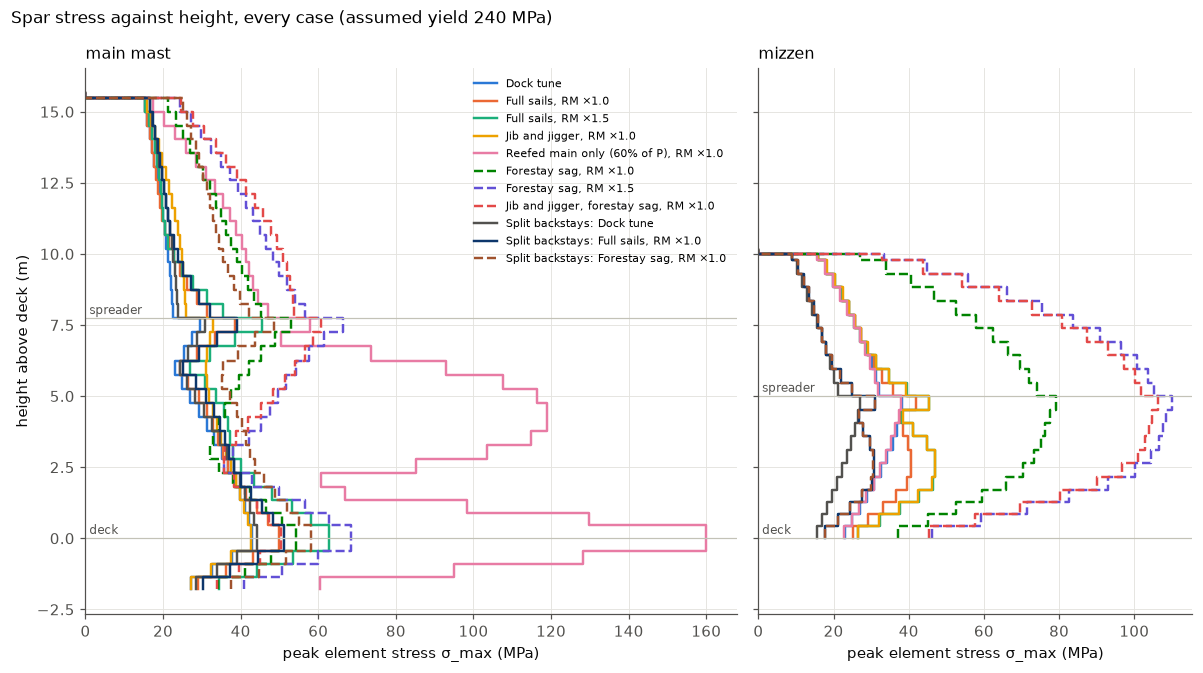

In [23]:
CASE_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#52514e",
                "#0d366b", "#a0522d", "#7a7a00"]
assert len(STRESS) <= len(CASE_COLOURS), "add a colour"
fig, axs = plt.subplots(1, 2, figsize=(11, 6.2), gridspec_kw={"width_ratios": [1.5, 1]}, sharey=True)
for (label, d), colr in zip(STRESS.items(), CASE_COLOURS):
    for ax, kind in zip(axs, MAST_KINDS):
        zs, sg = [], []
        for b in d["geo"]["beams"]:
            if b["kind"] == kind:
                zs += [d["geo"]["nodes"][b["i"]][2], d["geo"]["nodes"][b["j"]][2]]; sg += [d["s"][b["name"]][0] / 1e6] * 2
        ax.plot(sg, zs, color=colr, lw=1.6, ls="--" if d["solver"].startswith("OpenSees") else "-", label=label)
for ax, lab, zs_ in zip(axs, ("main mast", "mizzen"), (GEO["z"]["s1"], GEO["z"]["mz_s1"])):
    for zz, t in ((zs_, "spreader"), (0.0, "deck")):
        ax.axhline(zz, color="#c3c2b7", lw=0.8); ax.text(1, zz + 0.15, t, fontsize=8, color="#52514e")
    ax.set_xlabel("peak element stress σ_max (MPa)"); ax.set_title(lab, loc="left", fontsize=10.5); ax.set_xlim(left=0)
axs[0].set_ylabel("height above deck (m)")
axs[0].legend(frameon=False, fontsize=7.5, loc="upper right")
fig.suptitle(f"Spar stress against height, every case (assumed yield {params.sigma_y_al/1e6:.0f} MPa)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

### What the stresses show (placeholder sections, geometry and loads)

- **At the dock and with full sails the spars are modest:** the main peaks at 43–50 MPa (18–21%) at the
  partners, the mizzen at 38–42 MPa (16–17%) near its spreader.
- **Reefed main only loads the main's partners hardest: 160 MPa, 67% of the assumed yield,** with 24 kN·m of
  athwart bending. The whole heeling moment comes in low, most of it on the 7.7 m lower panel.
- **With a triatic, forestay sag loads the mizzen.** At RM ×1.0 the mizzen reaches 79 MPa (33%), and at ×1.5
  110 MPa (46%), with 63 kN of compression. Jib and jigger with forestay sag gives 106 MPa (44%).
- **With split backstays the mizzen stays at 27–31 MPa (11–13%) in every case,** because nothing ties it to the
  forestay. The main takes the difference: 118 kN of compression in the forestay-sag case against 105 kN with
  the triatic.
- **Spreaders stay below about 12%** on their placeholder sections.
- **Check 12:** Pynite and OpenSees agree on the full-sail peak to 0.05% on the main and 0.02% on the mizzen.

### What the cases show (default placeholders)

- **The triatic makes the mizzen backstays the rig's weakest link once the genoa loads the forestay.** In the
  forestay-sag case the forestay goes from 17.8 to 34.8 kN, and the triatic, which holds the main masthead aft,
  passes the rise on: 7.5 to 14.5 kN. The mizzen backstays go from 12.7 to 24.6 kN (52% of MBL, **SF 1.9**). At
  RM ×1.5 they reach 30.6 kN, **SF 1.5**, the lowest in the study. Jib and jigger with forestay sag is almost as
  bad: 30.1 kN, SF 1.6.
- **Both mastheads are pulled forward in those cases,** the main by about 120 mm and the mizzen by 106 mm from
  their dock positions. The mizzen's compression rises from 40 to 56 kN, and to 63 kN at ×1.5.
- **Split backstays decouple the masts.** The same forestay-sag case leaves the mizzen untouched (its backstays
  stay at 1.9 kN). The main backstays take the load instead, 5.5 to 16.2 kN (25% of MBL). The forestay rises
  further, to 40.8 kN against 34.8 kN, because two backstays straight to the quarters hold the masthead more
  stiffly than a triatic on a bending mizzen. So the forestay sags less (555 against 653 mm), the main carries
  more compression (118 against 105 kN), and the minimum SF is 2.2 on the forestay rather than 1.9 on the mizzen
  backstays.
- **Pynite's lumped and P-Delta stay-sag rows are the usual warning.** They leave the forestay at its dock
  tension and let it sag 1.2 m. Use the corotational rows for any loaded stay.
- **Reefed main only puts 22 kN on the windward aft lower** and loads the main's partners hardest (above).
- **Jib and jigger without sag** puts 31 kN on the main caps (SF 2.9). The mizzen's sail adds little; it's the
  genoa at the masthead.
- **Everything rests on placeholders.** The mizzen backstays' angle and size, the triatic's existence and the
  mizzen's stiffness decide these results. Measure those first.

---
## §11 Interactive explorer

The controls rerun the Pynite pipeline (tune, then the RM case) and redraw the tension plot. Each run takes
several seconds: the tune is a seven- or eight-unknown Newton solve. Widgets work in VS Code and classic
Jupyter; in a PDF export this cell shows only its last state.

In [24]:
try:
    import ipywidgets as W

    out = W.Output()

    def rerun(arrangement, x_mizzen, cap_pct, mz_backstay_pct, gz30, sail_plan):
        p = replace(params, backstay_arrangement=arrangement, x_mizzen=x_mizzen, GZ30=gz30, sail_plan=sail_plan,
                    chainplate={**params.chainplate, **{g: (params.chainplate[g][0] - params.x_mizzen + x_mizzen, params.chainplate[g][1])
                                                        for g in ("zcap", "zlowerF", "zlowerA")}},
                    pretension_pct={**params.pretension_pct, "cap": cap_pct, "zforestay": mz_backstay_pct})
        with out:
            out.clear_output(wait=True)
            g = rig_geometry(p)
            d, _, _ = tune(p, g)
            ld, info = rm_loads(p, g)
            m = solve_pynite(p, g, d, ld)
            res = {c: pynite_results(m, g, c) for c in ("Dock", "RM")}
            tt = tension_table(res["Dock"], res["RM"], g, p)
            lam, _ = buckling_factor(m, "RM", 1)
            sm = max(beam_stresses_pynite(m, g, "RM").items(), key=lambda kv: kv[1][0])
            print(f"RM30 = {p.RM30/1e3:.1f} kN*m   min SF = {tt['SF (RM)'].min():.2f} ({tt['SF (RM)'].idxmin()})   "
                  f"slack: {', '.join(tt.index[tt['slack in RM case'] == 'SLACK']) or 'none'}   λ = {lam[0]:.2f}   "
                  f"peak spar stress {sm[1][0]/1e6:.0f} MPa ({sm[0]})")
            plot_tensions(tt)

    ui = W.interactive(rerun, {"manual": True, "manual_name": "Run"},
                       arrangement=W.Dropdown(options=["triatic", "split"], value=params.backstay_arrangement, description="backstays"),
                       x_mizzen=W.FloatSlider(value=params.x_mizzen, min=-8.0, max=-6.0, step=0.1, description="mizzen x (m)"),
                       cap_pct=W.FloatSlider(value=params.pretension_pct["cap"], min=5, max=30, step=1, description="cap % MBL"),
                       mz_backstay_pct=W.FloatSlider(value=params.pretension_pct["zforestay"], min=5, max=30, step=1,
                                                     description="mz fstay %"),
                       gz30=W.FloatSlider(value=params.GZ30, min=0.3, max=1.2, step=0.05, description="GZ30 (m)"),
                       sail_plan=W.Dropdown(options=["full", "jib_and_jigger", "headsail_only", "main_only", "reefed_main_only"],
                                            value=params.sail_plan, description="sail plan"))
    display(W.VBox([ui, out]))
except ImportError:
    print("ipywidgets not available; edit RigParams in §0 instead")

---
## Placeholders to replace, roughly in order of how much they move the answer

1. **$GZ_{30}$** (that is, $RM_{30}$). Every sailing load scales with it. Also settle 30,000 against 33,000 lb.
2. **Triatic or not, and the mizzen's position and height** (`backstay_arrangement`, `x_mizzen`, `IY`). They
   decide how the forestay's pull reaches the hull.
3. **The mizzen backstays' foot** (`mz_backstay_foot`). With a triatic, their angle sets how much tension it
   takes to hold the main masthead.
4. **Both spar sections.** Chord, width and wall, or the makers' section numbers.
5. **Spreader count, heights and lengths** on both masts. The main may well have two sets.
6. **Every wire size**, with the MBL from each wire's certificate.
7. **Chainplate positions, heel depth, mast steps and boom heights.**

---
## §12 Checks

Each check has a stated tolerance and the reason for it. The last cell raises if any check fails.

In [25]:
CHECKS = []


def check(name, value, ref, rel_tol, why, skip=False):
    if skip:
        CHECKS.append({"check": name, "value": np.nan, "reference": np.nan, "rel err": np.nan, "tol": rel_tol,
                       "result": "SKIP", "why tolerance": why}); return
    err = abs(value - ref) / max(abs(ref), 1e-30)
    CHECKS.append({"check": name, "value": value, "reference": ref, "rel err": err, "tol": rel_tol,
                   "result": "PASS" if err <= rel_tol else "FAIL", "why tolerance": why})


# 1. sectionproperties closed ellipses vs closed form pi/4 (a b^3 - ai bi^3), semi-axes; main and mizzen
for lab, (ch, wd, tw), sec in (("main", (params.mast_chord, params.mast_width, params.mast_wall), SEC["closed"]),
                               ("mizzen", (params.mz_chord, params.mz_width, params.mz_wall), SEC_MZ["closed"])):
    a, b, t = ch / 2, wd / 2, tw
    check(f"1  sectionproperties {lab} tube I_fa", sec["I_fa"], math.pi / 4 * (b * a**3 - (b - t) * (a - t)**3) * 1e-12, 2e-3,
          "128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it")
    check(f"1  sectionproperties {lab} tube I_ath", sec["I_ath"], math.pi / 4 * (a * b**3 - (a - t) * (b - t)**3) * 1e-12, 2e-3,
          "same polygon error")

# 2. cantilever tip deflection PL^3/3EI on the main section, Pynite (and OpenSees below)
Lc, Pc = 10.0, 1000.0
mc = FEModel3D(); mc.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mc.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
mc.add_node("a", 0, 0, 0); mc.add_node("b", 0, Lc, 0)
mc.add_member("c", "a", "b", "Al", "mast"); mc.def_support("a", *[True] * 6)
mc.add_node_load("b", "FX", Pc, "L"); mc.add_load_combo("C", {"L": 1}); mc.analyze()
check("2a Pynite cantilever tip, fore-and-aft", mc.nodes["b"].DX["C"], Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9,
      "Euler-Bernoulli element is exact for a tip load")

# 3. pinned column buckling from K, Kg vs pi^2 EI/L^2
mb = FEModel3D(); mb.add_material("Al", params.E_al, params.G_al, 0.33, 2700)
mb.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"])
nel = 20
for k in range(nel + 1):
    mb.add_node(f"n{k}", 0, Lc * k / nel, 0)
for k in range(nel):
    mb.add_member(f"e{k}", f"n{k}", f"n{k+1}", "Al", "mast")
mb.def_support("n0", True, True, True, False, True, False)
mb.def_support(f"n{nel}", True, False, True, False, False, False)
mb.add_node_load(f"n{nel}", "FY", -1000.0, "L"); mb.add_load_combo("C", {"L": 1}); mb.analyze()
lam_b, phi_b = buckling_factor(mb, "C", 6)
r_tw = params.mast_chord / 2e3
kb = next(k for k in range(len(lam_b)) if max(np.hypot(phi_b[i * 6, k], phi_b[i * 6 + 2, k]) for i in range(nel + 1))
          >= max(abs(phi_b[i * 6 + 4, k]) for i in range(nel + 1)) * r_tw)
check("3  Pynite K/Kg pinned column vs Euler (first flexural mode)", lam_b[kb] * 1000.0, math.pi**2 * params.E_al * MAST["I_ath"] / Lc**2, 2e-3,
      "20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin")

# 4. symmetric two-shroud lack of fit vs hand statics
hL, yL, dl = 10.0, 1.5, 2e-3
wp = wire_props("3/8 in"); L4 = math.hypot(hL, yL); c4 = hL / L4
ms = FEModel3D(); ms.add_material("Al", params.E_al, params.G_al, 0.33, 2700); ms.add_material("W", params.E_wire, 40e9, 0.3, 7950)
ms.add_section("mast", MAST["A"], MAST["I_ath"], MAST["I_fa"], MAST["J"]); ms.add_section("w", wp["A"], 1e-12, 1e-12, 1e-12)
ms.add_node("base", 0, 0, 0); ms.add_node("head", 0, hL, 0); ms.add_node("cp", 0, 0, yL); ms.add_node("cs", 0, 0, -yL)
ms.add_member("mast", "base", "head", "Al", "mast"); ms.def_support("base", *[True] * 6)
for nm, cp in (("wp", "cp"), ("ws", "cs")):
    ms.add_member(nm, cp, "head", "W", "w", tension_only=True)
    ms.def_releases(nm, Ryi=True, Rzi=True, Rxj=True, Ryj=True, Rzj=True); ms.def_support(cp, *[True] * 6)
    u4 = unit((ms.nodes[cp].X, ms.nodes[cp].Y, ms.nodes[cp].Z), (0, hL, 0))
    for comp, val in zip(("DX", "DY", "DZ"), -dl * u4):
        if abs(val) > 0:
            ms.def_node_disp(cp, comp, float(val))
ms.add_load_combo("C", {}); ms.analyze(check_stability=False)
k_w, k_m = wp["A"] * params.E_wire / L4, MAST["A"] * params.E_al / hL
check("4  lack-of-fit pretension vs hand", -ms.members["wp"].axial(1.0, "C"), k_w * dl / (1 + 2 * c4**2 * k_w / k_m), 1e-6,
      "linear statics with one compatibility equation; exact to solver precision")


# 5. global equilibrium of the rig, both cases (reactions + applied = 0)
def resultant(res, loads):
    F = sum(res["rxn"].values())
    for v in loads.values():
        F = F + np.asarray(v)
    return F


for label, res_, tol_, why_ in (("linear", RES_LIN, 1e-9, "linear statics: rounding only"),
                                ("P-Delta", RES, 2e-3, "Pynite's two-cycle P-Delta is not iterated to convergence")):
    for c, ld in (("Dock", {}), ("RM", LOADS)):
        R = resultant(res_[c], ld)
        scale = LINFO["F_main"] + LINFO["F_mizzen"] + LINFO["head_share_on_rig"] if c == "RM" else max(T_TARGET.values())
        resid = np.linalg.norm(R[:3]) / scale
        CHECKS.append({"check": f"5  equilibrium {c}, {label}: |ΣF| / load scale", "value": resid, "reference": 0.0,
                       "rel err": resid, "tol": tol_, "result": "PASS" if resid <= tol_ else "FAIL", "why tolerance": why_})

# 6. heeling moment carried by the supports = k*RM30 (moment of reactions about the boat x-axis at the deck)
Mx = {c: sum(r[3] + (GEO["nodes"][n][1] * r[2] - GEO["nodes"][n][2] * r[1]) for n, r in RES_LIN[c]["rxn"].items())
      for c in ("Dock", "RM")}
check("6  support moment about deck x-axis = k RM30 (linear solve)", -(Mx["RM"] - Mx["Dock"]), LINFO["M_target"], 1e-9,
      "statics of the load generator: the stem share acts at deck level, so the rig carries all of k RM30")

# 7. dock tune hits its targets, both arrangements
for g in TUNED:
    check(f"7  dock tune (triatic): {TARGET_OF[g]} via {g} turnbuckle", T_TUNED[g], T_TARGET[g], 1e-3, "Newton stops at |error| < 1 N")
for g in tune_spec(P_SPLIT)[0]:
    check(f"7  dock tune (split): {tune_spec(P_SPLIT)[1][g]} via {g} turnbuckle", T_TUNED_SP[g], T_TARGET_SP[g], 1e-3,
          "Newton stops at |error| < 1 N")

# 8. Pynite P-Delta vs OpenSees corotational
skip = OPS is None
key_w = ["cap_V1_P", "cap_V2_P", "lowerF_D1F_P", "lowerA_D1A_P", "forestay", "triatic", "zcap_V1_P", "zlowerA_D1A_P", "zbackstay_P"]
TOL8 = {"forestay": (0.025, "bow shortening of the masts lowers the mastheads (§9), which linear-strain P-Delta omits"),
        "triatic": (0.025, "carries the forestay's pull, so inherits the forestay's bow-shortening difference")}
TOL13 = {**TOL8,
         "zforestay": (0.025, "the mizzen's ~0.17 mm bow shortening is 1.6% of this short, lightly loaded stay's ~10 mm stretch"),
         "zbackstay_P": (0.025, "the mizzen backstays balance the mizzen forestay, so they share its bow-shortening difference")}
for nm in key_w:
    tol8, why8 = TOL8.get(nm, (0.01, "two-cycle P-Delta vs exact kinematics; 1% on a loaded wire"))
    check(f"8  RM tension {nm}: Pynite vs OpenSees corotational", RES["RM"]["T"][nm],
          np.nan if skip else OPS["Corotational"]["RM"]["T"][nm], tol8, why8, skip)
check("8  RM masthead athwart: Pynite vs OpenSees corotational", RES["RM"]["disp"][head][1],
      np.nan if skip else OPS["Corotational"]["RM"]["disp"][head][1], 0.02, "displacement is the most sensitive output; 2%", skip)
check("8  dock max main compression: Pynite vs OpenSees corotational", Nmax["Dock"],
      np.nan if skip else max(OPS["Corotational"]["Dock"]["mast_N"].values()), 0.01,
      "pretension by enforced support motion (Pynite) vs initial strain (OpenSees)", skip)
check("8  dock max mizzen compression: Pynite vs OpenSees corotational", Nmax_mz["Dock"],
      np.nan if skip else max(OPS["Corotational"]["Dock"]["mz_N"].values()), 0.01, "as above, on the mizzen", skip)

# 2b. the same cantilever in OpenSees
cant = None
if OPS_PY.exists():
    cant = run_opensees({"nodes": {"a": (0, 0, 0), "b": (0, Lc, 0)}, "fix": {"a": [1] * 6}, "wires": [],
                         "beams": [{"i": "a", "j": "b", "kind": "mast", "A": MAST["A"], "E": params.E_al, "G": params.G_al,
                                    "J": MAST["J"], "Iy": MAST["I_ath"], "Iz": MAST["I_fa"], "vecxz": (0.0, 0.0, 1.0)}],
                         "loads": {"b": [Pc, 0, 0, 0, 0, 0]}, "transfs": ["PDelta"], "nsteps": 1})
check("2b OpenSees cantilever tip, fore-and-aft", np.nan if cant is None else cant["PDelta"]["RM"]["disp"]["b"][0],
      Pc * Lc**3 / (3 * params.E_al * MAST["I_fa"]), 1e-9, "exact element; also confirms Iz = I_fa in OpenSees", cant is None)

# 9. cable equation (rigid ends) vs OpenSees corotational on a single pretensioned cable with the sag-case genoa load
fs_wp = wire_props(params.wire["forestay"])
Lc9, T09, n9, F9 = group_len(GEO, "forestay"), SAG1["T0"], 40, SAG1["info"]["F_genoa"]
cab = None
if OPS_PY.exists():
    nodes9 = {f"c{k:02d}": (Lc9 * k / n9, 0.0, 0.0) for k in range(n9 + 1)}
    fix9 = {nm: ([1] * 6 if k in (0, n9) else [0, 0, 0, 1, 1, 1]) for k, nm in enumerate(nodes9)}
    w9 = lambda s: 2 * F9 / Lc9 * (1 - s / Lc9)
    loads9 = {nm: [0.0] * 6 for nm in nodes9}
    for k in range(n9):
        sa, sb = Lc9 * k / n9, Lc9 * (k + 1) / n9
        loads9[f"c{k:02d}"][2] += (sb - sa) * (2 * w9(sa) + w9(sb)) / 6
        loads9[f"c{k+1:02d}"][2] += (sb - sa) * (w9(sa) + 2 * w9(sb)) / 6
    cab = run_opensees({"nodes": nodes9, "fix": fix9, "beams": [], "transfs": ["Corotational"], "nsteps": 20,
                        "wires": [{"name": f"s{k:02d}", "i": f"c{k:02d}", "j": f"c{k+1:02d}", "A": fs_wp["A"],
                                   "E": params.E_wire, "eps0": T09 / (fs_wp["A"] * params.E_wire)} for k in range(n9)],
                        "loads": {k_: v for k_, v in loads9.items() if any(v)}})
T9_hand = cable_T_fixed_ends(T09, Lc9, fs_wp["A"] * params.E_wire, lambda s: 2 * F9 / Lc9 * (1 - s / Lc9))
check("9  cable equation vs OpenSees corotational, rigid-end forestay", np.nan if cab is None else
      max(cab["Corotational"]["RM"]["T"].values()), T9_hand, 0.01,
      "small-sag theory and 40 segments; tension also varies slightly along the cable", cab is None)

# 10. the sag-case loads carry the same heeling moment about the deck as the lumped case
ld10, inf10 = SAG1["loads"], SAG1["info"]
M10 = sum(GEO_FS["nodes"][n][2] * -v[1] - GEO_FS["nodes"][n][1] * v[2] for n, v in ld10.items()) + sum(v[3] for v in ld10.values())
check("10 forestay-sag loads: moment about deck = k RM30", M10, inf10["M_target"], 1e-9,
      "a linear luff load on straight segments: the truss-consistent nodal forces reproduce its moment exactly")

# 11. St-Venant J of the main tube against Bredt's thin-wall formula J = 4 A_m^2 / (closed integral of ds / t),
# with t(s) measured along the midline normal (the bore is the ellipse (a - t, b - t), not a parallel offset)
a, b, t = params.mast_chord / 2, params.mast_width / 2, params.mast_wall
am, bm = a - t / 2, b - t / 2
th11 = np.linspace(0, 2 * np.pi, 20001)[:-1]
mx, my = am * np.cos(th11), bm * np.sin(th11)
nx, ny = mx / am**2, my / bm**2; nn = np.hypot(nx, ny); nx, ny = nx / nn, ny / nn


def _near_root(A, B):
    qa = (nx / A)**2 + (ny / B)**2; qb = 2 * (mx * nx / A**2 + my * ny / B**2); qc = (mx / A)**2 + (my / B)**2 - 1
    r = np.sqrt(qb**2 - 4 * qa * qc); l1, l2 = (-qb + r) / (2 * qa), (-qb - r) / (2 * qa)
    return np.where(np.abs(l1) < np.abs(l2), l1, l2)


t_s = _near_root(a, b) - _near_root(a - t, b - t)
ds11 = np.hypot(-am * np.sin(th11), bm * np.cos(th11)) * (2 * np.pi / len(th11))
J_bredt = 4 * (math.pi * am * bm)**2 / np.sum(ds11 / t_s) * 1e-12
check("11 sectionproperties J vs Bredt thin-wall, real wall t(s) (main tube)", SEC["closed"]["J"], J_bredt, 1e-3,
      f"wall runs {t_s.min():.2f}–{t_s.max():.2f} mm; thin-wall theory drops O((t/b)^2) terms")

# 12. peak spar stress, full sails x1.0: Pynite P-Delta against OpenSees corotational (independent moments)
if OPS is not None and OPS["Corotational"]["RM"].get("lf"):
    s_ops = beam_stresses_ops(OPS["Corotational"]["RM"], GEO)
    s_py = STRESS["Full sails, RM ×1.0"]["s"]
    for kind in MAST_KINDS:
        mk_ = [b["name"] for b in GEO["beams"] if b["kind"] == kind]
        check(f"12 peak {kind} stress, full sails: Pynite vs OpenSees corotational", max(s_py[n][0] for n in mk_),
              max(s_ops[n][0] for n in mk_), 0.03, "tensions agree within 1%; moments are more sensitive, so 3%")
else:
    check("12 peak spar stress, full sails: Pynite vs OpenSees corotational", np.nan, np.nan, 0.03, "", True)
Pf, Pa, Lc_ = 1000.0, 500.0, 10.0
check("12 section_stress formula vs hand, cantilever root", section_stress(0.0, Pf * Lc_, Pa * Lc_, "mast"),
      math.hypot(Pf * Lc_ * params.mast_chord / 2e3 / MAST["I_fa"], Pa * Lc_ * params.mast_width / 2e3 / MAST["I_ath"]),
      1e-12, "same algebra, written out by hand")

# 13. the split-backstay rig, full sails x1.0: Pynite P-Delta against OpenSees corotational, so the second arrangement
# is cross-checked as independently as the first
LOADS_SP = rm_loads(P_SPLIT, GEO_SP)[0]
RES_SP = pynite_results(M_SP, GEO_SP, "RM")
o13 = run_opensees({**opensees_model(P_SPLIT, GEO_SP, DELTAS_SP, LOADS_SP, M_SP), "transfs": ["Corotational"]}) if OPS_PY.exists() else None
for nm in ("cap_V2_P", "lowerA_D1A_P", "forestay", "backstay_P", "zcap_V2_P", "zbackstay_P", "zforestay"):
    tol13, why13 = TOL13.get(nm, (0.01, "two-cycle P-Delta vs exact kinematics; 1% on a loaded wire"))
    check(f"13 split backstays, RM tension {nm}: Pynite vs OpenSees corotational", RES_SP["T"][nm],
          np.nan if o13 is None else o13["Corotational"]["RM"]["T"][nm], tol13, why13, o13 is None)

CHK = pd.DataFrame(CHECKS).set_index("check")
display(CHK.style.format({"value": "{:.6g}", "reference": "{:.6g}", "rel err": "{:.2e}", "tol": "{:.2g}"}))

,value,reference,rel err,tol,result,why tolerance
check,,,,,,
1 sectionproperties main tube I_fa,3.24578e-05,3.24839e-05,8.03e-04,0.002,PASS,128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it
1 sectionproperties main tube I_ath,1.64089e-05,1.64221e-05,8.03e-04,0.002,PASS,same polygon error
1 sectionproperties mizzen tube I_fa,7.45689e-06,7.46288e-06,8.03e-04,0.002,PASS,128-sided polygon under-fills the ellipse by ~cos(pi/128) on area; 0.2% covers it
1 sectionproperties mizzen tube I_ath,3.90423e-06,3.90736e-06,8.03e-04,0.002,PASS,same polygon error
"2a Pynite cantilever tip, fore-and-aft",0.146711,0.146711,1.32e-15,1e-09,PASS,Euler-Bernoulli element is exact for a tip load
3 Pynite K/Kg pinned column vs Euler (first flexural mode),113365,113365,8.44e-07,0.002,PASS,20 cubic elements: discretisation error ~1e-5; 0.2% leaves margin
4 lack-of-fit pretension vs hand,1436.62,1436.62,3.17e-16,1e-06,PASS,linear statics with one compatibility equation; exact to solver precision
"5 equilibrium Dock, linear: |ΣF| / load scale",3.29877e-12,0,3.30e-12,1e-09,PASS,linear statics: rounding only
"5 equilibrium RM, linear: |ΣF| / load scale",1.33203e-12,0,1.33e-12,1e-09,PASS,linear statics: rounding only


### Information only: large-displacement effect and leeward slack

In [26]:
if OPS is not None:
    info = pd.DataFrame({nm: {"PDelta (kN)": OPS["PDelta"]["RM"]["T"][nm] / 1e3,
                              "corotational (kN)": OPS["Corotational"]["RM"]["T"][nm] / 1e3,
                              "corot − PDelta (%)": 100 * (OPS["Corotational"]["RM"]["T"][nm] / max(OPS["PDelta"]["RM"]["T"][nm], 1e-9) - 1)}
                         for nm in key_w}).T
    display(info.style.format("{:.2f}"))
print("slack wires in the RM case:", ", ".join(TT.index[TT["slack in RM case"] == "SLACK"]) or "none")

,PDelta (kN),corotational (kN),corot − PDelta (%)
cap_V1_P,27.19,26.83,-1.32
cap_V2_P,27.78,27.41,-1.33
lowerF_D1F_P,13.35,13.20,-1.11
lowerA_D1A_P,14.63,14.57,-0.41
forestay,18.15,17.76,-2.13
triatic,7.62,7.46,-2.07
zcap_V1_P,4.99,4.77,-4.40
zlowerA_D1A_P,4.70,4.40,-6.45
zbackstay_P,12.97,12.71,-2.05


slack wires in the RM case: lowerF_D1F_S


In [27]:
n_fail = (CHK["result"] == "FAIL").sum(); n_pass = (CHK["result"] == "PASS").sum(); n_skip = (CHK["result"] == "SKIP").sum()
print(f"{n_pass} PASS, {n_fail} FAIL, {n_skip} SKIP")
assert n_fail == 0, CHK[CHK["result"] == "FAIL"]
print("ALL CHECKS OK")

53 PASS, 0 FAIL, 0 SKIP
ALL CHECKS OK


---
## §13 Report

This cell writes **`output/morgan-462-ketch/REPORT.md`**, and one four-panel figure per
load case to `output/morgan-462-ketch/assets/rig-m462-case-*.svg`, which the report embeds: the deflected rig from astern and in
profile coloured by utilisation with the sail loads drawn on, both masts' stress against height, and every
wire's % of MBL. It overwrites the file each run; set `WRITE_REPORT = False` to skip it. Treat the file as
generated output and don't hand-edit it.

The report opens with a **rigging list**, written by the cell below: every wire with its quantity, size, model length, breaking load and the highest load any case puts on it, plus totals by wire size and what to check before ordering.

In [28]:
# ---- Rigging list for §13's report: every wire as it would be ordered ----------------------------------------
RIG_LABEL = {"forestay": ("Forestay (inside the genoa furler)", "stem fitting to masthead"),
             "triatic": ("Triatic", "masthead to mizzen masthead"),
             "cap": ("Main caps (uppers)", "chainplate, over the spreader tip, to the masthead (one wire)"),
             "lowerF": ("Main forward lowers", "chainplate to the spreader root"),
             "lowerA": ("Main aft lowers", "chainplate to the spreader root"),
             "zbackstay": ("Mizzen backstay legs", "quarter to the mizzen masthead"),
             "zcap": ("Mizzen caps", "chainplate, over the mizzen spreader tip, to the mizzen masthead (one wire)"),
             "zlowerF": ("Mizzen forward lowers", "chainplate to the mizzen spreader root"),
             "zlowerA": ("Mizzen aft lowers", "chainplate to the mizzen spreader root"),
             "backstay": ("Main backstay legs", "quarter to the masthead, passing outside the mizzen"),
             "zforestay": ("Mizzen forestay", "cockpit's forward end to the mizzen masthead")}                   # group -> (name, where it runs), in the order the list shows them
RIG_PUBLISHED = set()           # groups whose wire size is published rather than a placeholder
RIG_NOTE = ("Nothing about this boat's spars or rigging is published, so every size and every length here is a placeholder. "
            "The main table is the rig as modelled in the base cases; wires only the split-backstay variant has follow it.")


def rigging_list_rows():
    """One row per wire type. Lengths come from the first geometry that has the group (the base rig first), so wires
    that only a variant has (split backstays) still appear. Loads are the largest over every case, on either side."""
    geos = list({id(g): g for g in [GEO] + [d["geo"] for d in STRESS.values()]}.values())
    pieces = {}
    for geo in geos:
        for w in geo["wires"]:
            p_ = pieces.setdefault(w["group"], {"geo": geo, "length": {}, "sides": set()})
            if p_["geo"] is geo:
                p_["sides"].add(w["side"])
                p_["length"][w["side"]] = p_["length"].get(w["side"], 0.0) + seg_len(geo, w)
    rows = []
    for g in list(RIG_LABEL) + [g for g in pieces if g not in RIG_LABEL]:
        if g not in pieces:
            continue
        p_ = pieces[g]
        size = params.wire[g]
        peak, peak_case, dock = 0.0, "", None
        for label, d in STRESS.items():
            for name, t in d["T"].items():
                if GROUP_OF.get(name) == g and t > peak:
                    peak, peak_case = t, label
            if dock is None and label.endswith("Dock tune") and d["geo"] is p_["geo"]:
                dock = max(t for name, t in d["T"].items() if GROUP_OF.get(name) == g)
        rows.append({"group": g, "qty": 1 if "C" in p_["sides"] else len(p_["sides"]), "size": size,
                     "d_mm": float(WIRE.loc[size, "d_mm"]), "n_sources": int(WIRE.loc[size, "n_sources"]),
                     "length": max(p_["length"].values()), "mbl": wire_props(size)["MBL"],
                     "mbl_lbf": float(WIRE.loc[size, "MBL_design_lbf"]), "dock": dock, "peak": peak,
                     "case": peak_case.replace(" (60% of P)", ""), "base": p_["geo"] is GEO})
    return rows


def rigging_list_md():
    """The report's rigging list: a table per rig, totals by wire size, and what to check before ordering."""
    ft_in = lambda m: f"{round(m / 0.0254) // 12} ft {round(m / 0.0254) % 12} in"
    head = ["| Item and where it runs | Qty | Wire, 1x19 316 | Length, centre to centre (each) | Design MBL | Dock tune | "
            "Highest load in any case | Size |", "| --- | ---: | --- | --- | --- | --- | --- | --- |"]

    def line(r):
        name, run = RIG_LABEL.get(r["group"], (r["group"], ""))
        dock = "—" if r["dock"] is None else f"{r['dock']/1e3:.1f} kN ({100 * r['dock'] / r['mbl']:.0f}%)"
        return (f"| **{name}**: {run} | {r['qty']} | {r['size']} ({r['d_mm']:.1f} mm) | {r['length']:.2f} m ({ft_in(r['length'])}) | "
                f"{r['mbl']/1e3:.1f} kN ({r['mbl_lbf']:,.0f} lbf) | {dock} | {r['peak']/1e3:.1f} kN, SF {r['mbl'] / r['peak']:.1f} "
                f"({r['case']}) | {'published' if r['group'] in RIG_PUBLISHED else 'placeholder'} |")

    rows = rigging_list_rows()
    base, variant = [r for r in rows if r["base"]], [r for r in rows if not r["base"]]
    tot = {}
    for r in base:
        t = tot.setdefault(r["size"], {"pieces": 0, "len": 0.0, "d_mm": r["d_mm"], "n": r["n_sources"]})
        t["pieces"] += r["qty"]; t["len"] += r["qty"] * r["length"]
    out = ["## Rigging list", "",
           "Every piece of standing rigging in the model, laid out the way a rigging order is: what it is, how many, the wire "
           "and its length, with the breaking load and the highest load any case below puts on it. " + RIG_NOTE, ""]
    out += head + [line(r) for r in base]
    out += ["", "**Wire totals by size** (the pieces above, centre-to-centre lengths, before any allowance for terminals):", "",
            "| Wire | Pieces | Total length | MBL sources in the wire table |", "| --- | ---: | --- | ---: |"]
    out += [f"| {s} ({t['d_mm']:.1f} mm) 1x19 316 | {t['pieces']} | {t['len']:.1f} m ({t['len'] / 0.3048:.0f} ft) | {t['n']} |"
            for s, t in sorted(tot.items(), key=lambda kv: -kv[1]["d_mm"])]
    if variant:
        out += ["", "**Wires only the variant rig has** (split backstays: these are added, and the triatic dropped):", ""]
        out += head + [line(r) for r in variant]
    out += ["", "**Before ordering from this list:**", "",
            "- **The lengths are not cut lengths.** Each is measured in the model from the mast's centreline at the attachment "
            "height to the chainplate pin at deck level, along the wire. A real wire is made to its pin-to-pin length, tang to "
            "chainplate, with the turnbuckle and toggles at their working setting; tangs sit off the centreline and chainplate "
            "pins above the deck, so the real length differs by several centimetres even where the geometry is right.",
            "- **Measure the old wire,** pin to pin with its turnbuckle at the tuned setting, or have a rigger measure the spar "
            "and chainplates. Use this list for the sizes, the quantities and the loads to check fittings against.",
            "- **Terminals, toggles and turnbuckles aren't in the model.** Match them to the wire, and check that each fitting's "
            "rated load is at least the wire's MBL.",
            "- **MBL is the lowest of the catalogs in the wire table;** the totals table says how many catalogs each size rests "
            "on. Use the figure on the new wire's certificate.",
            "- **The highest load** is the largest tension any case in this report puts on that wire, at the placeholder GZ30. "
            "Port and starboard wires are the same length and see the same loads on opposite tacks.", ""]
    return out


In [29]:
WRITE_REPORT = True
REPORT_PATH = OUT / "REPORT.md"
FIG_DIR = OUT / "assets"
FIG_DIR.mkdir(parents=True, exist_ok=True)
UTIL_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "util", ["#f3c7a9", "#efa47a", "#eb7f4c", "#e0602a", "#c24a1a", "#962f0c", "#651c05"])
UTIL_MAX = 0.5                       # colour scale 0..50 % utilisation, shared by every case and every member
C_LOADS = "#2a78d6"                  # applied loads (kept off the warm utilisation ramp)
DISP_SCALE = 5.0


def md_table(rows, cols, fmt=None, align=None):
    """rows: list of dicts. fmt: {col: format string or callable}. Right-aligns numbers."""
    fmt = fmt or {}
    def cell(r, c):
        v = r.get(c, "")
        f = fmt.get(c)
        if v is None or (isinstance(v, float) and not np.isfinite(v)):
            return "—"
        if callable(f):
            return f(v)
        return format(v, f) if f else str(v)
    al = [(align or {}).get(c, "r" if isinstance(rows[0].get(c), (int, float, np.floating)) else "l") for c in cols]
    head_ = "| " + " | ".join(cols) + " |"
    rule = "| " + " | ".join("---:" if a == "r" else "---" for a in al) + " |"
    body = ["| " + " | ".join(cell(r, c) for c in cols) + " |" for r in rows]
    return "\n".join([head_, rule] + body)


WIRE_LABEL = {"cap_V1": "cap V1 (chainplate to spreader tip)", "cap_V2": "cap V2 (spreader tip to masthead)",
              "lowerF_D1F": "forward lower", "lowerA_D1A": "aft lower", "backstay": "main backstay leg",
              "forestay": "forestay", "triatic": "triatic (masthead to mizzen masthead)",
              "zcap_V1": "mizzen cap V1", "zcap_V2": "mizzen cap V2", "zlowerF_D1F": "mizzen forward lower",
              "zlowerA_D1A": "mizzen aft lower", "zbackstay": "mizzen backstay leg", "zforestay": "mizzen forestay"}
SHORT = {"(chainplate to spreader tip)": "", "(spreader tip to masthead)": "", "(masthead to mizzen masthead)": "",
         "port (windward)": "wwd", "starboard (leeward)": "lwd", "forward lower": "fwd lower"}


def wire_label(name):
    base, side = (name[:-2], name[-1]) if name[-2] == "_" and name[-1] in "PS" else (name, "")
    lab = WIRE_LABEL.get(base, base)
    return f"{lab}, {'port (windward)' if side == 'P' else 'starboard (leeward)' if side == 'S' else ''}".rstrip(", ")


def case_figure(label, d, path):
    """Four panels for one load case: views from astern and in profile (deflected, coloured by utilisation, loads as
    arrows), both masts' stress against height, and every wire's % MBL."""
    geo, p_, res, loads = d["geo"], d["p"], d["res"], d["loads"]
    n_, disp = geo["nodes"], res["disp"]
    P = lambda nm, sc: np.add(n_[nm], sc * np.asarray(disp[nm]))
    util_w = {w["name"]: d["T"][w["name"]] / wire_props(p_.wire[w["group"]])["MBL"] for w in geo["wires"]}
    util_b = {b["name"]: d["s"][b["name"]][0] / p_.sigma_y_al for b in geo["beams"]}
    colour = lambda u: UTIL_CMAP(min(u / UTIL_MAX, 1.0))
    z_lo, z_hi = min(v[2] for v in n_.values()) - 0.6, p_.I + p_.mast_above_hounds + 1.0
    fig = plt.figure(figsize=(17, 7.4))
    gs = fig.add_gridspec(1, 4, width_ratios=[1.0, 2.3, 1.0, 1.3], wspace=0.28)
    views = [(fig.add_subplot(gs[0]), lambda q: (-q[1], q[2]), "From astern (starboard to the right)"),
             (fig.add_subplot(gs[1]), lambda q: (q[0], q[2]), "Profile (bow to the right)")]
    for ax, proj, title in views:
        for b in geo["beams"]:
            a0, b0 = proj(n_[b["i"]]), proj(n_[b["j"]])
            ax.plot([a0[0], b0[0]], [a0[1], b0[1]], color="#d8d7d2", lw=3 if b["kind"] in MAST_KINDS else 2, zorder=1)
        for w in geo["wires"]:
            a1, b1 = proj(P(w["i"], DISP_SCALE)), proj(P(w["j"], DISP_SCALE))
            if d["T"][w["name"]] < 500:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color="#8a8984", lw=1.0, ls=(0, (2, 2)), zorder=2)
            else:
                ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_w[w["name"]]), lw=1.8, zorder=2)
        for b in geo["beams"]:
            a1, b1 = proj(P(b["i"], DISP_SCALE)), proj(P(b["j"], DISP_SCALE))
            ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=colour(util_b[b["name"]]),
                    lw=5 if b["kind"] in MAST_KINDS else 3, solid_capstyle="butt", zorder=3)
        Fs = {nm: np.asarray(v[:3]) for nm, v in loads.items() if nm in n_ and np.linalg.norm(v[:3]) > 1.0}
        fmax = max((np.linalg.norm(f) for f in Fs.values()), default=1.0)
        for nm, f in Fs.items():
            tip = np.asarray(proj(P(nm, DISP_SCALE)))
            dvec = np.asarray(proj(f)) - np.asarray(proj((0.0, 0.0, 0.0)))
            if np.linalg.norm(dvec) < 1e-9 * fmax:
                continue
            ax.annotate("", xy=tip, xytext=tip - dvec / fmax * 1.6, arrowprops=dict(arrowstyle="-|>", color=C_LOADS, lw=1.2), zorder=4)
        ax.axhline(0, color="#c3c2b7", lw=0.8)
        ax.set_aspect("equal"); ax.set_title(title, loc="left", fontsize=10)
        ax.tick_params(labelsize=8); ax.grid(color="#eceae4", lw=0.5)
    xs = [v[0] for v in n_.values()]
    views[0][0].set_xlim(-3.2, 4.4); views[0][0].set_ylim(z_lo, z_hi)
    views[1][0].set_xlim(min(xs) - 1.0, max(xs) + 1.0); views[1][0].set_ylim(z_lo, z_hi)
    views[0][0].set_ylabel("height (m)")
    views[0][0].plot([], [], color=C_LOADS, lw=1.2, label="applied sail load")
    views[0][0].plot([], [], color="#8a8984", lw=1.0, ls=(0, (2, 2)), label="slack wire")
    views[0][0].plot([], [], color="#d8d7d2", lw=3, label="undeformed spars")
    views[0][0].legend(loc="lower left", fontsize=7.5, frameon=False)

    ax = fig.add_subplot(gs[2])                                   # both masts' stress against height
    peak = (0.0, 0.0, "")
    for kind, ls, lab in (("mast", "-", "main"), ("mizzen", "--", "mizzen")):
        zs, sg = [], []
        for b in geo["beams"]:
            if b["kind"] == kind:
                zs += [n_[b["i"]][2], n_[b["j"]][2]]; sg += [d["s"][b["name"]][0] / 1e6] * 2
        ax.plot(sg, zs, color="#52514e", lw=1.6, ls=ls, label=lab)
        k_ = int(np.argmax(sg))
        if sg[k_] > peak[0]:
            peak = (sg[k_], zs[k_], lab)
    ax.plot([peak[0]], [peak[1]], "o", color=colour(peak[0] * 1e6 / p_.sigma_y_al), ms=8, mec="#0b0b0b", mew=0.6)
    ax.annotate(f"peak {peak[0]:.0f} MPa ({peak[2]})\n{100*peak[0]*1e6/p_.sigma_y_al:.0f}% of yield", (peak[0], peak[1]),
                xytext=(-10, 10), textcoords="offset points", fontsize=8.5, ha="right",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xlim(0, max(120, 1.15 * peak[0])); ax.set_ylim(z_lo, z_hi); ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax.set_xlabel("spar peak stress (MPa)", fontsize=9); ax.tick_params(labelsize=8)
    ax.set_title("Spar stress", loc="left", fontsize=10); ax.grid(color="#eceae4", lw=0.5)

    ax = fig.add_subplot(gs[3])                                   # every wire's % MBL (forestay segments collapse to the highest)
    def short(name):
        s = wire_label(name)
        for a_, b_ in SHORT.items():
            s = s.replace(a_, b_)
        return " ".join(s.split()).replace(" ,", ",")
    rows = []
    for w in geo["wires"]:
        if "_s" in w["name"][-4:]:
            continue
        u = max(v for k, v in util_w.items() if GROUP_OF.get(k) == "forestay") if w["group"] == "forestay" else util_w[w["name"]]
        rows.append((short(w["name"]), u))
    y = np.arange(len(rows))
    ax.barh(y, [100 * u for _, u in rows], color=[colour(u) for _, u in rows], height=0.7)
    for k, (_, u) in enumerate(rows):
        ax.text(100 * u + 0.8, k, f"{100*u:.0f}%" if u > 0.005 else "slack", va="center", fontsize=7.5)
    ax.set_yticks(y, [r for r, _ in rows], fontsize=7.5); ax.invert_yaxis()
    ax.set_xlim(0, max(60, 110 * max(u for _, u in rows))); ax.set_xlabel("% of MBL", fontsize=9); ax.tick_params(axis="x", labelsize=8)
    ax.set_title("Wire utilisation", loc="left", fontsize=10); ax.grid(axis="x", color="#eceae4", lw=0.5)

    sm = cm.ScalarMappable(cmap=UTIL_CMAP, norm=mcolors.Normalize(0, 100 * UTIL_MAX))
    cb = fig.colorbar(sm, ax=fig.axes[:2], orientation="horizontal", fraction=0.04, pad=0.08, aspect=40)
    cb.set_label("utilisation: wires % of MBL, spars % of assumed yield (scale tops out at 50%)", fontsize=8.5)
    cb.ax.tick_params(labelsize=8)
    inf = d["info"]
    sub = (f"k·RM30 {inf['M_target']/1e3:.1f} kN·m · main {inf['F_main']/1e3:.1f} kN · genoa {inf['F_genoa']/1e3:.1f} kN · "
           f"mizzen {inf['F_mizzen']/1e3:.1f} kN" if inf else "turnbuckle pretension only")
    fig.suptitle(f"{label}   ({d['solver']}; {geo['arrangement']} rig; deflections ×{DISP_SCALE:.0f})\n{sub}",
                 x=0.01, y=0.995, ha="left", fontsize=11)
    fig.savefig(path, bbox_inches="tight", facecolor="white", metadata={"Date": None})
    plt.close(fig)


def slug(text):
    s = "".join(ch if ch.isalnum() else "-" for ch in text.lower()).strip("-")
    while "--" in s:
        s = s.replace("--", "-")
    return s


def case_section(label, d, dock):
    geo, p_, res = d["geo"], d["p"], d["res"]
    out = [f"## {label}", "", f"*Solver: {d['solver']}; {geo['arrangement']} rig.*", ""]
    fig_path = FIG_DIR / f"rig-m462-case-{slug(label)}.svg"
    case_figure(label, d, fig_path)
    out += [f"![{label}]({fig_path.relative_to(OUT).as_posix()})", ""]
    inf = d["info"]
    if inf:
        out += ["### Loads applied", "", md_table([
            {"item": "Moment about the deck, k·RM30", "value": inf["M_target"] / 1e3, "unit": "kN·m"},
            {"item": "Sail pressure (common to every sail set)", "value": inf["pressure_Pa"], "unit": "Pa"},
            {"item": "Main force (triangular along the main mast)", "value": inf["F_main"] / 1e3, "unit": "kN"},
            {"item": "Genoa force", "value": inf["F_genoa"] / 1e3, "unit": "kN"},
            {"item": "Mizzen force (triangular along the mizzen)", "value": inf["F_mizzen"] / 1e3, "unit": "kN"},
            {"item": "Genoa share on the rig (1/3 at the masthead, or along the forestay in the sag cases)",
             "value": inf["head_share_on_rig"] / 1e3, "unit": "kN"}],
            ["item", "value", "unit"], {"value": ".2f"}), ""]
    else:
        out += ["No sail load: turnbuckle pretension only.", ""]

    rows = []
    for w in geo["wires"]:
        if "_s" in w["name"][-4:]:
            continue
        mbl = wire_props(p_.wire[w["group"]])["MBL"]
        t = d["T"][w["name"]]
        t0 = dock["T"].get(w["name"], np.nan)
        rows.append({"wire": wire_label(w["name"]), "size": p_.wire[w["group"]], "MBL (kN)": mbl / 1e3,
                     "tension (kN)": t / 1e3, "tension (lbf)": t / LBF, "% MBL": 100 * t / mbl,
                     "SF": mbl / t if t > 500 else np.nan,
                     "change from dock (kN)": (t - t0) / 1e3 if not label.endswith("Dock tune") else np.nan,
                     "state": "slack" if t < 500 else ""})
    out += ["### Wires", "", md_table(rows, list(rows[0]), {"MBL (kN)": ".1f", "tension (kN)": ".2f", "tension (lbf)": ",.0f",
                                                           "% MBL": ".1f", "SF": ".2f", "change from dock (kN)": "+.2f"}), ""]
    if "bound" in d:
        ts = [t for n, t in d["T"].items() if GROUP_OF.get(n) == "forestay"]
        out += [f"Forestay tension along its length: {min(ts)/1e3:.2f} to {max(ts)/1e3:.2f} kN; rigid-end cable bound "
                f"{d['bound']/1e3:.1f} kN; sag {stay_sag_mm(geo, res):.0f} mm.", ""]

    rows = []
    for kind, mast, zl in (("mast", "main", [-99.0, 0.0, geo["z"]["s1"], geo["z"]["head"] + 1e-6]),
                           ("mizzen", "mizzen", [-99.0, 0.0, geo["z"]["mz_s1"], geo["z"]["mz_head"] + 1e-6])):
        for (za, zb), nm in zip(zip(zl[:-1], zl[1:]), ("heel to deck", "deck to spreader", "spreader to masthead")):
            els = [b for b in geo["beams"] if b["kind"] == kind and za - 1e-9 <= geo["nodes"][b["i"]][2] < zb]
            if not els:
                continue
            b = max(els, key=lambda b: d["s"][b["name"]][0])
            sig, N, Mfa, Math = d["s"][b["name"]]
            rows.append({"mast": mast, "panel": nm, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                         "at z (m)": f"{geo['nodes'][b['i']][2]:.1f}–{geo['nodes'][b['j']][2]:.1f}",
                         "N (kN, compr.)": N / 1e3, "axial σ (MPa)": abs(N) / SPARS[kind]["A"] / 1e6,
                         "M fore-aft (kN·m)": abs(Mfa) / 1e3, "M athwart (kN·m)": abs(Math) / 1e3})
    out += ["### Masts, panel by panel", "", md_table(rows, list(rows[0]), {
        "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%", "N (kN, compr.)": ".1f", "axial σ (MPa)": ".1f",
        "M fore-aft (kN·m)": ".2f", "M athwart (kN·m)": ".2f"}), ""]

    rows = []
    for b in geo["beams"]:
        if not b["kind"].endswith("spreader"):
            continue
        sig, N, Mv, Mh = d["s"][b["name"]]
        rows.append({"spreader": f"{'mizzen' if b['kind'].startswith('mizzen') else 'main'}, {'port' if b['name'][-1] == 'P' else 'starboard'}",
                     "compression (kN)": N / 1e3, "peak σ (MPa)": sig / 1e6, "utilisation": 100 * sig / p_.sigma_y_al,
                     "M vertical plane (kN·m)": abs(Mv) / 1e3, "M horizontal plane (kN·m)": abs(Mh) / 1e3})
    out += ["### Spreaders (placeholder sections)", "", md_table(rows, list(rows[0]), {
        "compression (kN)": ".2f", "peak σ (MPa)": ".1f", "utilisation": lambda v: f"{v:.0f}%",
        "M vertical plane (kN·m)": ".3f", "M horizontal plane (kN·m)": ".3f"}), ""]

    rx = {n: -np.asarray(v) for n, v in res["rxn"].items()}
    names = {"cap": "cap chainplate", "lowerF": "forward lower chainplate", "lowerA": "aft lower chainplate",
             "zcap": "mizzen cap chainplate", "zlowerF": "mizzen forward lower chainplate", "zlowerA": "mizzen aft lower chainplate"}
    fit = [(f"CP_{g}_{side}", f"{nm}, {sn}") for g, nm in names.items()
           for side, sn in (("P", "port (windward)"), ("S", "starboard (leeward)"))]
    fit += [(geo["key"]["bottom"], "main mast step (heel)"), (geo["key"]["partners"], "main partners (deck collar)"),
            (geo["zkey"]["bottom"], "mizzen step"), ("STEM", "stem fitting (forestay tack)"),
            ("BS_backstay_P", "main backstay chainplate, port"), ("BS_backstay_S", "main backstay chainplate, starboard"),
            ("BS_zbackstay_P", "mizzen backstay chainplate, port"), ("BS_zbackstay_S", "mizzen backstay chainplate, starboard"),
            ("ZSTEM", "mizzen forestay tack")]
    rows = [{"hull fitting": nm, "up (kN)": rx[n][2] / 1e3, "toward port (kN)": rx[n][1] / 1e3, "forward (kN)": rx[n][0] / 1e3,
             "resultant (kN)": np.linalg.norm(rx[n][:3]) / 1e3} for n, nm in fit if n in rx]
    out += ["### Loads into the hull", "",
            "Forces the rig puts on each hull fitting. A chainplate shows a positive \"up\": it is being pulled up. A mast "
            "step shows a negative one: it is being pushed down.", "",
            md_table(rows, ["hull fitting", "up (kN)", "toward port (kN)", "forward (kN)", "resultant (kN)"],
                     {"up (kN)": "+.2f", "toward port (kN)": "+.2f", "forward (kN)": "+.2f", "resultant (kN)": ".2f"}), ""]

    disp = res["disp"]
    pts = [(geo["key"]["head"], "masthead"), (geo["key"]["s1"], "main spreader root"), ("T1P", "main spreader tip, port"),
           (geo["key"]["boom"], "main gooseneck"), (geo["zkey"]["head"], "mizzen masthead"), (geo["zkey"]["s1"], "mizzen spreader root")]
    rows = [{"point": nm, "forward (mm)": disp[n][0] * 1e3, "port (mm)": disp[n][1] * 1e3, "up (mm)": disp[n][2] * 1e3}
            for n, nm in pts]
    out += ["### Displacements (from the stress-free drawn geometry)", "",
            md_table(rows, list(rows[0]), {"forward (mm)": "+.1f", "port (mm)": "+.1f", "up (mm)": "+.1f"}), ""]
    if np.isfinite(d.get("lam", np.nan)):
        out += [f"First buckling load factor λ = {d['lam']:.2f}.", ""]
    return out


if WRITE_REPORT:
    L = ["---", "title: Morgan 462 ketch rig 3D analysis, results report",
         "generated_by: notebooks/morgan-462-ketch.ipynb, section 13",
         f"generated: {time.strftime('%Y-%m-%d %H:%M')}", "units: SI (m, N, kN, MPa); wire sizes in inches", "---", "",
         "# Morgan 462 ketch rig: results report", "",
         "Written by the notebook from its own results; rerun the notebook to refresh it. The explanation of every "
         "term and load case is in [the companion note](https://github.com/rigframe/rigframe/releases/download/sample-reports/morgan-462-ketch-companion.pdf). I, J, P, E, PY, EY and the "
         "displacement are published; everything about the spars and rigging is a **placeholder** until measured.", "",
         f"Checks: {(CHK['result'] == 'PASS').sum()} pass, {(CHK['result'] == 'FAIL').sum()} fail, "
         f"{(CHK['result'] == 'SKIP').sum()} skipped.", "",
         "## Inputs", "",
         md_table([{"item": "I, J, P, E; PY, EY (m)", "value": f"{params.I:.2f}, {params.J:.2f}, {params.P:.2f}, {params.E:.2f}; "
                                                               f"{params.PY:.2f}, {params.EY:.2f}"},
                   {"item": "Displacement, GZ30 (placeholder), RM30",
                    "value": f"{params.displacement_kg:,.0f} kg, {params.GZ30} m, {params.RM30/1e3:.1f} kN·m"},
                   {"item": "Backstay arrangement (base cases)", "value": params.backstay_arrangement},
                   {"item": "Main mast (placeholder oval)", "value": f"{params.mast_chord:.0f} × {params.mast_width:.0f} × {params.mast_wall:.1f} mm: "
                                                                     f"A {MAST['A']*1e6:.0f} mm², I_fa {MAST['I_fa']*1e8:.0f} cm⁴, "
                                                                     f"I_ath {MAST['I_ath']*1e8:.0f} cm⁴, J {MAST['J']*1e8:.0f} cm⁴"},
                   {"item": "Mizzen (placeholder oval)", "value": f"{params.mz_chord:.0f} × {params.mz_width:.0f} × {params.mz_wall:.1f} mm: "
                                                                  f"A {MZ['A']*1e6:.0f} mm², I_fa {MZ['I_fa']*1e8:.0f} cm⁴, "
                                                                  f"I_ath {MZ['I_ath']*1e8:.0f} cm⁴"},
                   {"item": "Mizzen position, masthead height", "value": f"{-params.x_mizzen:.2f} m aft of the main, {params.IY:.2f} m above deck"},
                   {"item": "Assumed aluminium yield", "value": f"{params.sigma_y_al/1e6:.0f} MPa"},
                   {"item": "Wire sizes (1x19 316)", "value": ", ".join(f"{g} {v}" for g, v in params.wire.items())},
                   {"item": "Dock tune targets", "value": ", ".join(f"{g} {v:.0f}% MBL" for g, v in params.pretension_pct.items())},
                   {"item": "Turnbuckle shortenings (triatic rig)", "value": ", ".join(f"{g} {v*1e3:.1f} mm" for g, v in DELTAS.items())}],
                  ["item", "value"]), "",
         "## All cases at a glance", "",
         md_table([{"case": k, "solver": v["solver"].split()[0],
                    "main peak σ (MPa)": STRESS_TBL.loc[(k, v["solver"]), "main σ max (MPa)"],
                    "main util": 100 * STRESS_TBL.loc[(k, v["solver"]), "main util"],
                    "mizzen util": 100 * STRESS_TBL.loc[(k, v["solver"]), "mizzen util"],
                    "most utilised wire": wire_label(STRESS_TBL.loc[(k, v["solver"]), "most utilised wire"]),
                    "wire % MBL": 100 * STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "min wire SF": 1 / STRESS_TBL.loc[(k, v["solver"]), "wire util"],
                    "main compression (kN)": max(v["res"]["mast_N"].values()) / 1e3}
                   for k, v in STRESS.items()],
                  ["case", "solver", "main peak σ (MPa)", "main util", "mizzen util", "most utilised wire", "wire % MBL",
                   "min wire SF", "main compression (kN)"],
                  {"main peak σ (MPa)": ".0f", "main util": lambda v: f"{v:.0f}%", "mizzen util": lambda v: f"{v:.0f}%",
                   "wire % MBL": ".0f", "min wire SF": ".2f", "main compression (kN)": ".0f"}), ""]
    L += rigging_list_md()
    for k, v in STRESS.items():
        dock = STRESS["Split backstays: Dock tune" if k.startswith("Split") else "Dock tune"]
        L += case_section(k, v, dock)
    L += ["## Checks", "", md_table([{"check": i, "result": r["result"], "rel err": r["rel err"], "tol": r["tol"]}
                                     for i, r in CHK.iterrows()], ["check", "result", "rel err", "tol"],
                                    {"rel err": ".1e", "tol": ".2g"}), ""]
    REPORT_PATH.write_text("\n".join(L), encoding="utf-8")
    print(f"wrote {REPORT_PATH} ({REPORT_PATH.stat().st_size/1e3:.0f} kB, {len(STRESS)} cases)")

wrote output\morgan-462-ketch\REPORT.md (78 kB, 11 cases)


---
## §14 Standalone 3D viewer

This cell writes **`output/morgan-462-ketch/viewer-3d.html`**, a single page that opens in any browser: both
masts and every wire in 3D, coloured by utilisation, one button per load case (the split-backstay cases
included), a displacement-scale slider and hover details. It loads Plotly from a CDN, so it needs internet
once. Generated output, rewritten on each run.

In [30]:
WRITE_HTML = True
HTML_PATH = OUT / "viewer-3d.html"


def html_geo(geo, p):
    names = list(geo["nodes"]); ix = {n: i for i, n in enumerate(names)}
    return {"nodes": names, "xyz": [[round(float(v), 4) for v in geo["nodes"][n]] for n in names],
            "head": ix[geo["key"]["head"]], "zhead": ix[geo["zkey"]["head"]],
            "beams": [[ix[b["i"]], ix[b["j"]], int(b["kind"] in MAST_KINDS), b["name"]] for b in geo["beams"]],
            "wires": [[ix[w["i"]], ix[w["j"]], w["name"], p.wire[w["group"]], round(wire_props(p.wire[w["group"]])["MBL"] / 1e3, 2)]
                      for w in geo["wires"]]}


HTML_DATA = {"geos": {}, "sy": params.sigma_y_al / 1e6, "cases": []}
GEO_KEY = {}
for label, d in STRESS.items():
    gid = id(d["geo"])
    if gid not in GEO_KEY:
        GEO_KEY[gid] = f"g{len(GEO_KEY)}"
        HTML_DATA["geos"][GEO_KEY[gid]] = html_geo(d["geo"], d["p"])
    g = GEO_KEY[gid]
    names = HTML_DATA["geos"][g]["nodes"]
    HTML_DATA["cases"].append({
        "l": label, "s": d["solver"], "g": g,
        "d": [[round(1e3 * float(v), 2) for v in d["res"]["disp"][n]] for n in names],
        "b": [[round(d["s"][b["name"]][0] / 1e6, 2), round(d["s"][b["name"]][1] / 1e3, 2),
               round(abs(d["s"][b["name"]][2]) / 1e3, 3), round(abs(d["s"][b["name"]][3]) / 1e3, 3)] for b in d["geo"]["beams"]],
        "w": [[round(max(d["T"][w["name"]], 0.0) / 1e3, 3),
               round(max(d["T"][w["name"]], 0.0) / wire_props(d["p"].wire[w["group"]])["A"] / 1e6, 1)] for w in d["geo"]["wires"]]})

HTML_TEMPLATE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Morgan 462 ketch rig</title>
<style>
:root{--bg:#fbfaf7;--surface:#f1efe8;--ink:#0b0b0b;--muted:#6b6a65;--line:#d8d7d2;--accent:#2a78d6;--accent-ink:#fff}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b;color-scheme:dark}}
:root[data-theme="dark"]{--bg:#171716;--surface:#232321;--ink:#eeede8;--muted:#a3a29b;--line:#3a3a37;--accent:#5b9cf0;--accent-ink:#0b0b0b;color-scheme:dark}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 ui-sans-serif,-apple-system,"Segoe UI",sans-serif}
main{max-width:1200px;margin:0 auto;padding-block:16px;padding-left:max(16px, env(safe-area-inset-left, 0px));padding-right:max(16px, env(safe-area-inset-right, 0px))}
h1{font-size:20px;font-weight:600;margin:0 0 4px;text-wrap:balance}
.sub{color:var(--muted);font-size:13px;margin:0 0 12px;max-width:75ch}
.row{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin-bottom:10px}
.grp{font-size:11px;letter-spacing:.06em;text-transform:uppercase;color:var(--muted);width:100%;margin-top:2px}
button{font:inherit;font-size:12px;padding:4px 10px;border-radius:6px;border:1px solid var(--line);background:var(--surface);color:var(--ink);cursor:pointer}
button.on{background:var(--accent);color:var(--accent-ink);border-color:var(--accent)}
button:focus-visible,input:focus-visible{outline:2px solid var(--accent);outline-offset:2px}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px;margin-bottom:8px}
.card{background:var(--surface);border-radius:8px;padding:8px 12px;min-width:0}
.lab{font-size:12px;color:var(--muted)}.val{font-size:18px;font-weight:600;font-variant-numeric:tabular-nums}.small{font-size:12px;color:var(--muted)}
#plot{width:100%;height:660px}
.note{font-size:12px;color:var(--muted);margin-top:6px;max-width:90ch}
</style></head><body><main>
<h1>Morgan 462 ketch rig: stress and utilisation in 3D</h1>
<p class="sub">Masthead ketch, main and mizzen each with one spreader set, joined by a triatic (or, in the split-backstay
cases, standing apart). Generated by notebooks/morgan-462-ketch.ipynb (§14) on __DATE__. Everything about the
spars and rigging is a placeholder; I, J, P, E, PY, EY and the displacement are published.</p>
<div class="row" id="caseRow"></div>
<div class="row"><label class="lab" for="sc">Displacement ×</label><input type="range" id="sc" min="1" max="30" step="1" value="8" style="width:140px">
<span id="scOut" style="font-weight:600;min-width:22px">8</span>
<label class="lab" style="display:flex;align-items:center;gap:6px;margin-left:10px"><input type="checkbox" id="und" checked>Undeformed</label></div>
<div class="cards">
<div class="card"><div class="lab">Peak spar stress</div><div class="val" id="cMast">–</div><div class="small" id="cMastS">–</div></div>
<div class="card"><div class="lab">Most utilised wire</div><div class="val" id="cWire">–</div><div class="small" id="cWireS">–</div></div>
<div class="card"><div class="lab">Masthead movement</div><div class="val" id="cHead">–</div><div class="small">fwd / port, mm</div></div>
<div class="card"><div class="lab">Mizzen masthead movement</div><div class="val" id="cZHead">–</div><div class="small">fwd / port, mm</div></div>
</div>
<div id="plot"></div>
<p class="note">Colour is utilisation on one scale: wires = tension ÷ design MBL; masts and spreaders = peak fibre stress ÷ __SY__ MPa
(assumed aluminium yield). Spar stress = |N|/A + combined two-axis bending on the placeholder ovals. Dotted grey = slack wire.
Drag to rotate, scroll to zoom, hover any member. Forestay-sag cases come from OpenSees corotational; the rest from Pynite P-Delta.</p>
</main>
<script src="https://cdn.jsdelivr.net/npm/plotly.js-dist-min@2.35.2/plotly.min.js"></script>
<script>
const D=__DATA__;
const RAMP=["#f3c7a9","#efa47a","#eb7f4c","#e0602a","#c24a1a","#962f0c","#651c05"],UMAX=0.5;
const css=n=>getComputedStyle(document.documentElement).getPropertyValue(n).trim();
let ci=1,scale=8,showU=true;
function col(u){const f=Math.max(0,Math.min(1,u/UMAX))*(RAMP.length-1),i=Math.floor(f),t=f-i;if(i>=RAMP.length-1)return RAMP[RAMP.length-1];
  const h=s=>[1,3,5].map(k=>parseInt(s.substr(k,2),16)),A=h(RAMP[i]),B=h(RAMP[i+1]);return "rgb("+A.map((v,k)=>Math.round(v+(B[k]-v)*t)).join(",")+")";}
function P(g,c,i,s){const p=g.xyz[i],d=c.d[i];return[p[0]+s*d[0]/1000,p[1]+s*d[1]/1000,p[2]+s*d[2]/1000];}
function seg(pts,o){return Object.assign({type:"scatter3d",mode:"lines",x:pts.map(p=>p[0]),y:pts.map(p=>p[1]),z:pts.map(p=>p[2]),showlegend:false},o);}
function nice(n){return n.replace(/^z/,"mizzen ").replace(/_/g," ").replace(/ P$/," (port)").replace(/ S$/," (stbd)");}
function spar(n){return n.startsWith("mast_")?"Main mast element "+n.slice(5):n.startsWith("mizzen_")&&!n.startsWith("mizzen_spreader")?"Mizzen element "+n.slice(7):nice(n);}
const ALL=Object.values(D.geos).flatMap(g=>g.xyz),rng=k=>[Math.min(...ALL.map(p=>p[k]))-1,Math.max(...ALL.map(p=>p[k]))+1];
const RX=rng(0),RY=[-3,3],RZ=rng(2);
function build(){
  const c=D.cases[ci],g=D.geos[c.g],ink=css("--ink"),mut=css("--muted"),tr=[];
  if(showU){g.beams.forEach(b=>tr.push(seg([g.xyz[b[0]],g.xyz[b[1]]],{line:{color:"rgba(150,150,145,0.35)",width:b[2]?7:4},hoverinfo:"skip"})));
    g.wires.forEach(w=>tr.push(seg([g.xyz[w[0]],g.xyz[w[1]]],{line:{color:"rgba(150,150,145,0.25)",width:2},hoverinfo:"skip"})));}
  g.beams.forEach((b,k)=>{const r=c.b[k],u=r[0]/D.sy,isM=b[2]===1;
    const txt=`<b>${spar(b[3])}</b><br>peak stress ${r[0].toFixed(1)} MPa · ${(100*u).toFixed(0)}% of ${D.sy} MPa<br>axial ${r[1].toFixed(1)} kN (compression)<br>M fore-aft ${r[2].toFixed(2)} kN·m · M athwart ${r[3].toFixed(2)} kN·m`;
    tr.push(seg([P(g,c,b[0],scale),P(g,c,b[1],scale)],{line:{color:r[0]<0.01?"rgba(150,150,145,0.6)":col(u),width:isM?11:7},text:[txt,txt],hovertemplate:"%{text}<extra></extra>"}));});
  g.wires.forEach((w,k)=>{const r=c.w[k],slack=r[0]<0.5,u=r[0]/w[4];
    const txt=`<b>${nice(w[2])}</b><br>${w[3]} 1x19 316 · MBL ${w[4].toFixed(1)} kN<br>tension ${r[0].toFixed(2)} kN · ${(100*u).toFixed(1)}% MBL<br>${slack?"slack":"SF "+(w[4]/r[0]).toFixed(2)} · wire stress ${r[1].toFixed(0)} MPa`;
    const a=P(g,c,w[0],scale),bb=P(g,c,w[1],scale),pts=[];for(let i=0;i<=6;i++){const f=i/6;pts.push([a[0]+f*(bb[0]-a[0]),a[1]+f*(bb[1]-a[1]),a[2]+f*(bb[2]-a[2])]);}
    tr.push(seg(pts,{line:{color:slack?"rgba(140,140,135,0.8)":col(u),width:slack?2:5,dash:slack?"dot":"solid"},text:pts.map(()=>txt),hovertemplate:"%{text}<extra></extra>"}));});
  tr.push({type:"scatter3d",mode:"markers",x:[0],y:[0],z:[RZ[0]],marker:{size:0.1,color:[0],cmin:0,cmax:100*UMAX,colorscale:RAMP.map((v,i)=>[i/(RAMP.length-1),v]),showscale:true,
    colorbar:{title:{text:"utilisation %",font:{color:mut,size:12}},tickfont:{color:mut,size:11},ticksuffix:"%",thickness:12,len:0.6,outlinewidth:0}},hoverinfo:"skip",showlegend:false});
  const ax=(t,r)=>({title:{text:t,font:{color:mut,size:12}},tickfont:{color:mut,size:11},gridcolor:"rgba(136,135,128,0.25)",zerolinecolor:"rgba(136,135,128,0.4)",showbackground:false,range:r});
  const sx=RX[1]-RX[0],sz=RZ[1]-RZ[0],m=Math.max(sx,sz);
  Plotly.react("plot",tr,{paper_bgcolor:"rgba(0,0,0,0)",margin:{l:0,r:0,t:0,b:0},uirevision:"keep",
    scene:{xaxis:ax("x fwd (m)",RX),yaxis:ax("y port (m)",RY),zaxis:ax("z (m)",RZ),aspectmode:"manual",aspectratio:{x:sx/m*1.05,y:6/m*1.05,z:sz/m*1.05},camera:{eye:{x:1.2,y:-1.6,z:0.35},center:{x:0,y:0,z:-0.05}}},
    hoverlabel:{bgcolor:css("--surface"),font:{color:ink,size:12},bordercolor:css("--line")}},{displaylogo:false,responsive:true});
  let mb=-1,mk=0;g.beams.forEach((b,k)=>{const s=c.b[k][0];if(b[2]===1&&s>mb){mb=s;mk=k;}});
  let wu=-1,wk=0;g.wires.forEach((w,k)=>{const u=c.w[k][0]/w[4];if(u>wu){wu=u;wk=k;}});
  document.getElementById("cMast").textContent=`${mb.toFixed(0)} MPa · ${(100*mb/D.sy).toFixed(0)}%`;
  document.getElementById("cMastS").textContent=`${spar(g.beams[mk][3]).split(" element")[0]}, z ${g.xyz[g.beams[mk][0]][2].toFixed(1)} to ${g.xyz[g.beams[mk][1]][2].toFixed(1)} m`;
  document.getElementById("cWire").textContent=`${(100*wu).toFixed(0)}% MBL`;
  document.getElementById("cWireS").textContent=`${nice(g.wires[wk][2])}, SF ${(1/wu).toFixed(2)}`;
  const hd=c.d[g.head],zd=c.d[g.zhead];
  document.getElementById("cHead").textContent=`${hd[0].toFixed(0)} / ${hd[1].toFixed(0)}`;
  document.getElementById("cZHead").textContent=`${zd[0].toFixed(0)} / ${zd[1].toFixed(0)}`;
}
const row=document.getElementById("caseRow");let lastGrp=null;
D.cases.forEach((c,i)=>{const grp=c.l.startsWith("Split")?"Split backstays, no triatic":"Triatic rig";
  if(grp!==lastGrp){const h=document.createElement("div");h.className="grp";h.textContent=grp;row.appendChild(h);lastGrp=grp;}
  const b=document.createElement("button");b.className=i===ci?"on":"";b.textContent=c.l.replace("Split backstays: ","");b.title=c.s;b.dataset.i=i;
  b.onclick=()=>{ci=i;row.querySelectorAll("button").forEach(x=>x.classList.toggle("on",+x.dataset.i===i));build();};row.appendChild(b);});
document.getElementById("sc").oninput=e=>{scale=+e.target.value;document.getElementById("scOut").textContent=scale;build();};
document.getElementById("und").onchange=e=>{showU=e.target.checked;build();};
if(window.Plotly){build();}else{document.getElementById("plot").textContent="Plotly could not load (offline?).";}
</script></body></html>
"""

if WRITE_HTML:
    html = (HTML_TEMPLATE.replace("__DATA__", json.dumps(HTML_DATA, separators=(",", ":")))
            .replace("__SY__", f"{params.sigma_y_al/1e6:.0f}").replace("__DATE__", time.strftime("%Y-%m-%d")))
    HTML_PATH.write_text(html, encoding="utf-8")
    print(f"wrote {HTML_PATH} ({HTML_PATH.stat().st_size/1e3:.0f} kB, {len(HTML_DATA['cases'])} cases)")

wrote output\morgan-462-ketch\viewer-3d.html (69 kB, 11 cases)


---
## §15 Companion figures

This cell redraws the companion note's figures from the model's own geometry and results, as
`output/morgan-462-ketch/assets/rig-m462-*.svg`, so they never go stale when `RigParams` changes. Set `WRITE_FIGURES = False` to skip.

In [31]:
WRITE_FIGURES = True
GROUP_COLOUR = {"cap": "#2a78d6", "lowerF": "#1baf7a", "lowerA": "#eda100", "backstay": "#6250d6", "forestay": "#eb6834",
                "triatic": "#e34948", "zcap": "#0d366b", "zlowerF": "#008300", "zlowerA": "#a0522d", "zbackstay": "#e87ba4",
                "zforestay": "#7a7a00"}
GROUP_NAME = {"cap": "main caps", "lowerF": "main forward lowers", "lowerA": "main aft lowers", "backstay": "main backstays (split)",
              "forestay": "forestay", "triatic": "triatic", "zcap": "mizzen caps", "zlowerF": "mizzen forward lowers",
              "zlowerA": "mizzen aft lowers", "zbackstay": "mizzen backstays", "zforestay": "mizzen forestay (split)"}
INK, MUTED, HULL = "#0b0b0b", "#52514e", "#f1efe8"


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"rig-m462-{name}.svg", format="svg", bbox_inches="tight", facecolor="white", metadata={"Date": None})
    plt.close(fig)


def arrow(ax, x, y, dx, dy, colr=INK, lw=1.4):
    ax.annotate("", (x + dx, y + dy), (x, y), arrowprops=dict(arrowstyle="-|>", color=colr, lw=lw, shrinkA=0, shrinkB=0))


def wire_pts(geo, w, ax0, ax1):
    a, b = geo["nodes"][w["i"]], geo["nodes"][w["j"]]
    return [a[ax0], b[ax0]], [a[ax1], b[ax1]]


def hull_profile(ax, p):
    stern = min(p.backstay_foot[0], p.mz_backstay_foot[0]) - 0.2
    ax.fill([stern, stern + 0.3, stern + 2.5, -3.0, 2.8, 4.6, 4.8, stern], [0.0, -0.5, -1.0, -1.6, -1.6, -0.6, 0.0, 0.0],
            color=HULL, ec="#c3c2b7", lw=0.8, zorder=0)


def fig_overview():
    fig, axs = plt.subplots(1, 3, figsize=(13, 7.2), gridspec_kw={"width_ratios": [2.4, 1, 1]})
    for ax, geo, title in ((axs[0], GEO, "Profile, triatic rig (bow to the right)"),):
        hull_profile(ax, params)
        for names in (geo["mast_nodes"], geo["mz_nodes"]):
            ax.plot([geo["nodes"][names[0]][0]] * 2, [geo["nodes"][names[0]][2], geo["nodes"][names[-1]][2]], color=INK, lw=3)
        ax.plot([0, -params.E], [params.z_boom] * 2, color=MUTED, lw=2.5)
        ax.plot([params.x_mizzen, params.x_mizzen - params.EY], [params.z_boom_mz] * 2, color=MUTED, lw=2.5)
        seen = set()
        for w in geo["wires"]:
            if w["side"] == "S":
                continue
            xs, zs = wire_pts(geo, w, 0, 2); g = w["group"]
            ax.plot(xs, zs, color=GROUP_COLOUR[g], lw=1.5, label=None if g in seen else GROUP_NAME[g]); seen.add(g)
        w_sp = [w for w in GEO_SP["wires"] if w["group"] == "backstay" and w["side"] == "P"][0]
        xs, zs = wire_pts(GEO_SP, w_sp, 0, 2)
        ax.plot(xs, zs, color=GROUP_COLOUR["backstay"], lw=1.2, ls="--", label="main backstay, split arrangement")
        w_zf = next(w for w in GEO_SP["wires"] if w["group"] == "zforestay")
        xs, zs = wire_pts(GEO_SP, w_zf, 0, 2)
        ax.plot(xs, zs, color=GROUP_COLOUR["zforestay"], lw=1.2, ls="--", label="mizzen forestay, split arrangement")
        ax.set_aspect("equal"); ax.set_xlabel("x, forward (m)"); ax.set_ylabel("height above deck (m)")
        ax.set_title(title, loc="left", fontsize=10); ax.legend(frameon=False, fontsize=7.5, loc="upper left")
    hb = params.beam / 2
    for ax, names, groups, title in ((axs[1], GEO["mast_nodes"], ("cap", "lowerF", "lowerA"), "Main, from astern"),
                                     (axs[2], GEO["mz_nodes"], ("zcap", "zlowerF", "zlowerA", "zbackstay"), "Mizzen, from astern")):
        ax.fill([-hb, hb, hb * 0.8, -hb * 0.8], [0, 0, -1.0, -1.0], color=HULL, ec="#c3c2b7", lw=0.8)
        ax.plot([0, 0], [GEO["nodes"][names[0]][2], GEO["nodes"][names[-1]][2]], color=INK, lw=3)
        tipk = "T1" if names is GEO["mast_nodes"] else "ZT1"
        for side in "PS":
            tip = GEO["nodes"][tipk + side]; ax.plot([0, -tip[1]], [tip[2]] * 2, color=INK, lw=2)
        for w in GEO["wires"]:
            if w["group"] in groups:
                ys, zs = wire_pts(GEO, w, 1, 2); ax.plot([-v for v in ys], zs, color=GROUP_COLOUR[w["group"]], lw=1.3)
        ax.set_aspect("equal"); ax.set_ylim(-2.2, params.I + 1); ax.set_xlabel("starboard → (m)"); ax.set_title(title, loc="left", fontsize=10)
    fig.suptitle("Morgan 462 ketch as modelled (beyond I, J, P, E, PY, EY every dimension is a placeholder)", x=0.01, ha="left", fontsize=11)
    save_fig(fig, "overview")


def fig_heel_balance():
    th = math.radians(30)
    R = np.array([[math.cos(th), math.sin(th)], [-math.sin(th), math.cos(th)]])
    rot = lambda p: R @ np.asarray(p, float)
    hb = params.beam / 2
    hull = [[-hb, 1.3], [hb, 1.3], [hb * 0.97, 0.3], [hb * 0.75, -0.35], [0.55, -0.6], [0.35, -1.6], [-0.35, -1.6],
            [-0.55, -0.6], [-hb * 0.75, -0.35], [-hb * 0.97, 0.3]]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    ax.fill(*np.array([rot(p) for p in hull]).T, color=HULL, ec=MUTED, lw=1.0, zorder=1)
    ax.plot(*np.array([rot([0, 1.3]), rot([0, 6.5])]).T, color=INK, lw=3, zorder=2)
    ax.axhline(0.0, color="#86b6ef", lw=1.2, zorder=0); ax.text(-3.4, 0.08, "waterline", fontsize=8, color="#2a78d6")
    G = rot([0.0, 0.15]); B = np.array([G[0] + 0.7, -0.45])
    ax.plot(*G, "o", color=INK, zorder=3); ax.text(G[0] - 0.35, G[1] + 0.1, "G", fontsize=11)
    ax.plot(*B, "o", color="#2a78d6", zorder=3); ax.text(B[0] + 0.12, B[1] - 0.05, "B", fontsize=11, color="#2a78d6")
    arrow(ax, G[0], G[1], 0, -1.5, INK); ax.text(G[0] - 0.55, G[1] - 1.45, "Δg", fontsize=10)
    arrow(ax, B[0], B[1] - 1.1, 0, 1.0, "#2a78d6"); ax.text(B[0] + 0.1, B[1] - 1.2, "buoyancy", fontsize=9, color="#2a78d6")
    for x_ in (G[0], B[0]):
        ax.plot([x_, x_], [-2.0, -2.5], color=C_OPS_PD, lw=0.8)
    ax.annotate("", (B[0], -2.4), (G[0], -2.4), arrowprops=dict(arrowstyle="<->", color=C_OPS_PD))
    ax.text((G[0] + B[0]) / 2, -2.75, "GZ", fontsize=10, color=C_OPS_PD, ha="center")
    ce = rot([0, 1.3 + 0.38 * 5.2])
    arrow(ax, ce[0] - 2.0, ce[1], 2.0, 0, C_PYNITE, lw=2); ax.text(ce[0] - 2.0, ce[1] + 0.2, "sail force F (main, genoa, mizzen)", fontsize=9, color=C_PYNITE)
    k_ = rot([0, -1.0])
    arrow(ax, k_[0] + 2.0, k_[1], -2.0, 0, C_OPS_CR, lw=2); ax.text(k_[0] + 2.1, k_[1] - 0.08, "keel side force", fontsize=9, color=C_OPS_CR)
    ax.annotate("", (ce[0] + 0.6, ce[1]), (ce[0] + 0.6, k_[1]), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=0.8))
    ax.text(ce[0] + 0.7, (ce[1] + k_[1]) / 2, "h", fontsize=10, color=MUTED)
    ax.text(-3.4, 6.2, f"Steady heel at 30°:  F h = Δ g GZ\n$RM_{{30}}$ = {params.displacement_kg:,.0f} kg × 9.81 × {params.GZ30} m"
                       f" = {params.RM30/1e3:.1f} kN·m\n(GZ is a placeholder)", fontsize=9, va="top")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-3.5, 5.6); ax.set_ylim(-3.0, 6.4)
    save_fig(fig, "heel-balance")


def wire_force_on(geo, res, w, node):
    """Force (N, boat axes) that wire w puts on `node`, one of its ends."""
    other = w["i"] if w["j"] == node else w["j"]
    return res["T"][w["name"]] * unit(geo["nodes"][node], geo["nodes"][other])


def fig_dock_tune():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6.2), gridspec_kw={"width_ratios": [1, 2.6]})
    a1.plot([0, 0], [0, 6], color=INK, lw=3); a1.plot([0, 2.0], [6, 0.35], color=C_PYNITE, lw=1.6)
    a1.plot([2.0, 2.12], [0.35, 0.0], color=C_OPS_PD, lw=3); a1.plot([2.12], [0.0], "s", color=MUTED, ms=8)
    a1.text(2.25, 0.05, "chainplate", fontsize=8, color=MUTED); a1.text(2.25, 0.45, "δ = turnbuckle\nshortening", fontsize=8, color=C_OPS_PD)
    a1.text(1.15, 3.6, "wire fitted δ too short:\nT = EA δ / L, less what the\nmast gives back", fontsize=8, color=C_PYNITE)
    a1.set_title("(a) Pretension as lack of fit", loc="left", fontsize=10); a1.axis("off"); a1.set_xlim(-0.5, 4.2)
    n = GEO["nodes"]; res = RES["Dock"]
    hull_profile(a2, params)
    for names in (GEO["mast_nodes"], GEO["mz_nodes"]):
        a2.plot([n[names[0]][0]] * 2, [max(n[names[0]][2], 0), n[names[-1]][2]], color=INK, lw=3)
    for w in GEO["wires"]:
        if w["side"] != "S":
            xs, zs = wire_pts(GEO, w, 0, 2); a2.plot(xs, zs, color=GROUP_COLOUR[w["group"]], lw=0.8, alpha=0.5)
    sc = 0.30                                                      # m of arrow per kN
    for node in (GEO["key"]["head"], GEO["key"]["s1"], GEO["zkey"]["head"], GEO["zkey"]["s1"]):
        x0, z0 = n[node][0], n[node][2]; yoff = 0.0
        for w in GEO["wires"]:
            if node not in (w["i"], w["j"]) or w["side"] == "S":
                continue
            F = wire_force_on(GEO, res, w, node) * (2 if w["side"] == "P" else 1)
            if abs(F[0]) < 50:
                continue
            arrow(a2, x0, z0 + yoff, F[0] / 1e3 * sc, 0, GROUP_COLOUR[w["group"]], lw=2)
            a2.text(x0 + F[0] / 1e3 * sc + (0.1 if F[0] > 0 else -0.1), z0 + yoff, f"{F[0]/1e3:+.2f} kN", fontsize=7.5,
                    ha="left" if F[0] > 0 else "right", va="center", color=GROUP_COLOUR[w["group"]])
            yoff -= 0.5
    fig.text(0.30, -0.02, f"Fore-and-aft pulls of each wire on the masts at the dock (port and starboard pairs summed). "
                          f"Compression: main {Nmax['Dock']/1e3:.0f} kN, mizzen {Nmax_mz['Dock']/1e3:.0f} kN.", fontsize=8, color=MUTED)
    a2.set_aspect("equal"); a2.set_xlabel("x, forward (m); arrows to scale"); a2.set_ylabel("height (m)")
    a2.set_title("(b) What the dock tune does to the masts (triatic rig)", loc="left", fontsize=10)
    save_fig(fig, "dock-tune")


def fig_spreader_plan():
    fig, axs = plt.subplots(1, 2, figsize=(10, 5.2))
    for ax, k_, tipk, sec, title in ((axs[0], GEO["key"], "T1", (params.mast_width, params.mast_chord), "main spreader root"),
                                     (axs[1], GEO["zkey"], "ZT1", (params.mz_width, params.mz_chord), "mizzen spreader root")):
        n = GEO["nodes"]; res = RES["Dock"]; root = k_["s1"]; x0 = n[root][0]
        th = np.linspace(0, 2 * np.pi, 100)
        ax.fill(sec[0] / 2e3 * np.sin(th), sec[1] / 2e3 * np.cos(th), color="#86b6ef", ec=INK, lw=0.6)
        for side in "PS":
            tip = n[tipk + side]; ax.plot([0, -tip[1]], [0, tip[0] - x0], color=INK, lw=2.5)
        net = np.zeros(3); sc_ = 0.40
        for w in GEO["wires"]:
            if root not in (w["i"], w["j"]):
                continue
            cp = n[w["i"]]
            ax.plot([0, -cp[1]], [0, cp[0] - x0], color=GROUP_COLOUR[w["group"]], lw=0.8, ls=":")
            F = wire_force_on(GEO, res, w, root); net += F
            arrow(ax, 0, 0, -F[1] / 1e3 * sc_, F[0] / 1e3 * sc_, GROUP_COLOUR[w["group"]], lw=1.8)
            if w["side"] == "P":
                ax.text(-F[1] / 1e3 * sc_ * 1.05 - 0.05, F[0] / 1e3 * sc_ * 1.08, f"{GROUP_NAME[w['group']]}\n{np.hypot(F[0], F[1])/1e3:.2f} kN",
                        fontsize=7.5, color=GROUP_COLOUR[w["group"]], ha="right")
        arrow(ax, 0, 0, -net[1] / 1e3 * sc_, net[0] / 1e3 * sc_, INK, lw=2.5)
        ax.text(0.15, -1.05, f"net {net[0]/1e3:+.2f} kN fore-and-aft\n({'aft' if net[0] < 0 else 'forward'}, black arrow)",
                fontsize=8.5, color=INK)
        ax.set_xlim(-2.0, 2.0); ax.set_ylim(-1.25, 1.0)
        ax.set_aspect("equal"); ax.set_xlabel("starboard → (m)"); ax.set_ylabel("forward of the mast (m)")
        ax.set_title(f"Plan at the {title}, dock tune", loc="left", fontsize=10)
    save_fig(fig, "spreader-plan")


def fig_stay_sag():
    fig, ax = plt.subplots(figsize=(6.8, 5.6))
    for key_, colr, lab in (("Forestay sag, RM ×1.0", "#eb6834", "triatic rig, full sails"),
                            ("Jib and jigger, forestay sag, RM ×1.0", "#e34948", "triatic rig, jib and jigger"),
                            ("Split backstays: Forestay sag, RM ×1.0", "#6250d6", "split backstays, full sails")):
        if key_ not in SAG:
            continue
        S = SAG[key_]; src = S["ops"] if S["ops"] is not None else S["pynite"]; geo = S["geo"]
        seq = geo["stays"]["forestay"]
        P0 = np.array([geo["nodes"][k] for k in seq]); U = np.array([src["disp"][k] for k in seq])
        a, b = P0[0] + U[0], P0[-1] + U[-1]
        s_ = np.linalg.norm(P0 - P0[0], axis=1)
        sag = (P0[:, 1] + U[:, 1]) - (a[1] + (b[1] - a[1]) * s_ / s_[-1])
        Tmax = max(t for n_, t in src["T"].items() if GROUP_OF.get(n_) == "forestay")
        ax.plot(-sag * 1e3, P0[:, 2], "-o", ms=3, color=colr, label=f"{lab}: {S['T0']/1e3:.1f} → {Tmax/1e3:.1f} kN")
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_xlabel("forestay sag to leeward from its own chord (mm, true scale)"); ax.set_ylabel("height (m)")
    ax.set_title("Forestay sag, RM ×1.0 (OpenSees corotational)\nlegend: dock tension → sailing tension", loc="left", fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    save_fig(fig, "stay-sag")


def fig_load_cases():
    cases = [k for k in STRESS if not k.endswith("Dock tune") and "×1.5" not in k and not k.startswith("Split")]
    fig, axs = plt.subplots(1, len(cases), figsize=(2.7 * len(cases), 5.8), sharey=True)
    off = 1.8                                                      # the mizzen drawn this far right of the main, schematically
    for ax, k in zip(axs, cases):
        d = STRESS[k]; geo = d["geo"]; ld = d["loads"]
        ax.plot([0, 0], [0, params.I], color=INK, lw=2); ax.plot([off, off], [0, params.IY], color=INK, lw=2)
        Fmax = max(abs(v[1]) for v in ld.values())
        for nm, v in ld.items():
            if abs(v[1]) < 1e-6:
                continue
            x_ = off if geo["nodes"][nm][0] < params.x_mizzen / 2 else 0.0
            colr = GROUP_COLOUR["forestay"] if nm.startswith("FS") or nm == geo["key"]["head"] else ("#0d366b" if x_ else C_PYNITE)
            arrow(ax, x_ + 1.2 * abs(v[1]) / Fmax, geo["nodes"][nm][2], -1.2 * abs(v[1]) / Fmax, 0, colr, lw=1.0)
        inf = d["info"]
        ax.set_title(k.replace(", RM", "\nRM").replace(" (", "\n(").replace(", forestay", ",\nforestay"), fontsize=8, loc="left")
        ax.text(-0.15, -1.0, f"main {inf['F_main']/1e3:.1f}\ngenoa {inf['F_genoa']/1e3:.1f}\nmizzen {inf['F_mizzen']/1e3:.1f} kN",
                fontsize=7, color=MUTED, va="top")
        ax.set_xlim(-0.3, off + 1.4); ax.set_xticks([0, off], ["main", "mizzen"]); ax.grid(False)
    axs[0].set_ylabel("height (m)"); axs[0].set_ylim(-2.6, params.I + 0.8)
    fig.suptitle("Where each case puts its sail load (arrows scaled within each panel; all act to starboard; masts side by side, not to x-scale)",
                 x=0.01, ha="left", fontsize=10)
    save_fig(fig, "load-cases")


def fig_consistent_loads():
    fig, ax = plt.subplots(figsize=(7.0, 3.2))
    ax.plot([0, 4], [0, 0], color=INK, lw=4); ax.plot([0, 4], [0, 0], "o", color=INK, ms=7)
    w1, w2 = 1.2, 0.6
    ax.fill([0, 4, 4, 0], [0.25, 0.25, 0.25 + w2, 0.25 + w1], color="#cde2fb", ec=C_PYNITE)
    for x in np.linspace(0.2, 3.8, 7):
        h = w1 + (w2 - w1) * x / 4; arrow(ax, x, 0.25 + h, 0, -h + 0.02, C_PYNITE, lw=1)
    ax.text(0.05, 0.35 + w1, "$w_1$", fontsize=10, color=C_PYNITE); ax.text(3.75, 0.35 + w2, "$w_2$", fontsize=10, color=C_PYNITE)
    arrow(ax, 0, -0.2, 0, -0.9, C_OPS_PD, lw=2); arrow(ax, 4, -0.2, 0, -0.7, C_OPS_PD, lw=2)
    ax.text(0.1, -1.0, "$F_i = L(7w_1+3w_2)/20$\n$M_i = +L^2(3w_1+2w_2)/60$", fontsize=9, color=C_OPS_PD)
    ax.text(2.3, -1.0, "$F_j = L(3w_1+7w_2)/20$\n$M_j = -L^2(2w_1+3w_2)/60$", fontsize=9, color=C_OPS_PD)
    ax.text(1.7, -0.25, "L", fontsize=10)
    ax.set_xlim(-0.4, 4.6); ax.set_ylim(-1.7, 1.9); ax.axis("off")
    ax.set_title("A linearly varying load on one element and its consistent nodal loads", loc="left", fontsize=10)
    save_fig(fig, "consistent-loads")


def fig_p_delta():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
    z = np.linspace(0, 1, 50)
    a1.plot([0, 0], [0, 1], color=MUTED, lw=1, ls="--"); a1.plot(0.15 * (1 - np.cos(np.pi * z / 2)), z, color=INK, lw=3)
    arrow(a1, 0.15, 1.3, 0, -0.28, C_OPS_PD, lw=2); a1.text(0.2, 1.2, "P", fontsize=11, color=C_OPS_PD)
    arrow(a1, -0.25, 0.95, 0.22, 0, C_PYNITE, lw=2); a1.text(-0.38, 1.0, "H", fontsize=11, color=C_PYNITE)
    a1.annotate("", (0.15, 0.6), (0.0, 0.6), arrowprops=dict(arrowstyle="<->", color=INK)); a1.text(0.02, 0.63, "Δ", fontsize=11)
    a1.text(-0.35, -0.15, "base moment = H L + P Δ", fontsize=9)
    a1.set_xlim(-0.45, 0.5); a1.set_ylim(-0.25, 1.4); a1.axis("off"); a1.set_title("(a) P-Δ", loc="left", fontsize=10)
    lam = np.linspace(1.05, 12, 200)
    a2.plot(lam, 1 / (1 - 1 / lam), color=C_PYNITE)
    a2.plot([LAM[0]], [1 / (1 - 1 / LAM[0])], "o", color=C_OPS_PD)
    a2.text(LAM[0] + 0.3, 1 / (1 - 1 / LAM[0]) + 0.2, f"this rig, full sails: λ = {LAM[0]:.2f} ({KINDS[0]})", fontsize=9, color=C_OPS_PD)
    a2.set_ylim(0.9, 4); a2.set_xlabel("buckling load factor λ"); a2.set_ylabel("sway amplification 1/(1 − 1/λ)")
    a2.set_title("(b) Single-column amplification", loc="left", fontsize=10)
    save_fig(fig, "p-delta")


def fig_section():
    fig, axs = plt.subplots(1, 3, figsize=(10.5, 5.6))
    th = np.linspace(0, 2 * np.pi, 200)
    y_top = max(params.mast_chord / 2 + 10, max(v["x_sc"] * 1e3 + 25 for v in (SEC["closed"], SEC["slotted"], SEC_MZ["closed"])))
    for ax, (ch, wd, tw), v, slot, lab in ((axs[0], (params.mast_chord, params.mast_width, params.mast_wall), SEC["closed"], False, "Main, as modelled"),
                                            (axs[1], (params.mast_chord, params.mast_width, params.mast_wall), SEC["slotted"], True, "Main, what-if luff slot"),
                                            (axs[2], (params.mz_chord, params.mz_width, params.mz_wall), SEC_MZ["closed"], False, "Mizzen, as modelled")):
        a_, b_ = ch / 2, wd / 2
        ax.fill(b_ * np.sin(th), a_ * np.cos(th), color="#86b6ef", ec=INK, lw=0.6)
        ax.fill((b_ - tw) * np.sin(th), (a_ - tw) * np.cos(th), color="white", ec=INK, lw=0.6)
        if slot:
            ax.fill([-params.mast_slot / 2, params.mast_slot / 2, params.mast_slot / 2, -params.mast_slot / 2],
                    [-a_ - 2, -a_ - 2, -a_ + tw + 2, -a_ + tw + 2], color="white", ec="white")
        xsc = v["x_sc"] * 1e3 if abs(v["x_sc"]) > 5e-4 else 0.0     # print a symmetric section's offset as 0, not -0
        ax.plot([0], [0], "o", color=MUTED, ms=4); ax.plot([0], [xsc], "+", color=C_OPS_PD, ms=14, mew=2)
        ax.text(-b_, -params.mast_chord / 2 - 40, f"{ch:.0f} × {wd:.0f} × {tw:.1f} mm\nA {v['A']*1e6:.0f} mm²   J {v['J']*1e8:.1f} cm⁴\n"
                f"I_fa {v['I_fa']*1e8:.0f}   I_ath {v['I_ath']*1e8:.0f} cm⁴\nshear centre {xsc:+.0f} mm fwd", fontsize=8, va="top")
        ax.set_aspect("equal"); ax.axis("off"); ax.set_title(lab, fontsize=10, loc="left")
        ax.set_xlim(-params.mast_width / 2 - 10, params.mast_width / 2 + 10)
        ax.set_ylim(-params.mast_chord / 2 - 130, y_top)
    fig.suptitle("Placeholder spar sections, one scale (forward up; + = shear centre, ● = centroid)", x=0.01, ha="left", fontsize=10)
    save_fig(fig, "section")


if WRITE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)
    for f in (fig_overview, fig_heel_balance, fig_dock_tune, fig_spreader_plan, fig_stay_sag, fig_load_cases,
              fig_consistent_loads, fig_p_delta, fig_section):
        f()
    print("wrote", ", ".join(sorted(p.name for p in FIG_DIR.glob("rig-m462-*.svg") if "-case-" not in p.name)))

wrote rig-m462-consistent-loads.svg, rig-m462-dock-tune.svg, rig-m462-heel-balance.svg, rig-m462-load-cases.svg, rig-m462-overview.svg, rig-m462-p-delta.svg, rig-m462-section.svg, rig-m462-spreader-plan.svg, rig-m462-stay-sag.svg
